# Smart Dice Board Game: Learning to Win with Reinforcement Learning

**Student:** Nouran Ahmed Ahmed Ali Elshikh  ·  **ID:** 320230066
**Course project:** Reinforcement Learning

An agent learns to play a snakes-and-ladders style board game in which it **chooses** the dice value (1–6) every turn.
Five learners are compared on three boards (30, 50 and 100 squares):

| Agent | Family | Implementation |
|---|---|---|
| Q-Learning | Tabular, off-policy TD | from scratch (NumPy) |
| SARSA | Tabular, on-policy TD | from scratch (NumPy) |
| DQN | Deep RL, value-based | stable-baselines3 |
| PPO | Deep RL, policy gradient | stable-baselines3 |
| A2C | Deep RL, actor-critic | stable-baselines3 |

Two baselines frame the results: a **random policy** (the "before training" agent) and **BFS**, which gives the exact optimum on the deterministic board.

**Contents:** 1–9 environment and baselines · 10 Q-Learning and SARSA · 11 DQN, PPO, A2C · 12 all agents compared · 13 advanced challenges (reward design, random dice, 200-square board) · 14 interactive demo · 15 report answers · 16 results export

**Main results** (details and numbers in Sections 12–15, all tables in `results/RESULTS.md`):
- Q-Learning and SARSA learn the exact optimal game on every board and seed. SARSA needs a decaying learning rate to stay there.
- The brief's ladder reward (+20) is just below a reward-hacking threshold: at +23 / +24 the optimal policy loops ladder → snake forever.
- DQN reaches the optimum on every board and seed and ends with the best whole policy, but needs 3–30× more environment steps than Q-Learning. A2C is the weakest agent: it never reaches the optimum on the 100-square board.
- With random dice, BFS no longer applies, and Q-Learning learns a near-optimal policy from play alone.

> The notebook runs unchanged on Google Colab or locally. All outputs (figures, CSV logs, trained models) are written to a relative `results/` folder.

## 1. Setup

**What this does:** installs the two libraries that are not pre-installed on Colab, imports everything, and fixes all random seeds.

**Why:**
- `gymnasium` is the standard RL environment API. Writing the game as a Gymnasium environment lets the same environment serve the tabular agents and the stable-baselines3 (SB3) agents.
- `stable-baselines3` provides tested implementations of DQN, PPO and A2C, plus `check_env`, which validates our environment.
- Seeding `random`, `numpy` and `torch` makes every run reproducible, so the numbers in the report can be regenerated exactly.
- **Resumable runs:** every training run is saved the moment it finishes, and a rerun loads saved runs instead of training them again. If the runtime disconnects, run all again: it continues where it stopped. Set `FORCE_RETRAIN = True` to retrain everything.
- **On Colab, results are saved to Google Drive** (`MyDrive/smart-dice-rl/results`), so they survive disconnects. Colab will ask once for permission to mount Drive.
- **Restoring an earlier run:** put `smartdice_results.zip` (made by the last cell) next to the notebook, and it is unpacked automatically, so nothing is retrained.

In [1]:
# Installs only what Colab does not ship with. Locally this is a no-op if the packages are already installed.
%pip install -q "gymnasium>=0.29" "stable-baselines3>=2.3"

In [3]:
import os
import random
import warnings
from collections import Counter, deque
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, Rectangle

import gymnasium as gym
from gymnasium import spaces

SEED = 42
FORCE_RETRAIN = False            # False = resume: runs already saved in RESULTS_DIR are loaded, not retrained
try:                             # On Colab, save to Google Drive so results survive runtime disconnects
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/smart-dice-rl/results")
except ImportError:              # running locally
    RESULTS_DIR = Path("results")

# If a results zip from an earlier run is next to the notebook (e.g. uploaded to Colab's Files panel),
# restore it so finished runs are loaded instead of retrained.
if Path("smartdice_results.zip").exists() and not (RESULTS_DIR / "drl").exists():
    import shutil
    shutil.unpack_archive("smartdice_results.zip", RESULTS_DIR.parent)
    print("Restored earlier results from smartdice_results.zip")
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def set_global_seed(seed: int) -> None:
    # Seed every source of randomness used in this notebook.
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass


set_global_seed(SEED)
pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("gymnasium", gym.__version__, "| results folder:", RESULTS_DIR.resolve())

Mounted at /content/drive
gymnasium 1.4.0 | results folder: /content/drive/MyDrive/smart-dice-rl/results


## 2. Problem formulation (MDP)

The game is a **Markov Decision Process** $(S, A, P, R, \gamma)$:

- **States** $S = \{1, 2, \dots, N\}$: the agent's current square. Nothing else matters for the future (no hand, no history, no opponent), so the Markov property holds.
- **Actions** $A = \{1, \dots, 6\}$: the dice value the agent chooses. In code, action index $a \in \{0,\dots,5\}$ means dice value $a+1$ (Gymnasium's `Discrete(6)` starts at 0).
- **Transition** $P$: deterministic in the core game. Given square $s$ and dice $d$, the next square is fixed (rules below).
- **Reward** $R$: the table from the brief.
- **Discount** $\gamma = 0.99$: the goal reward on the 100-square board is many moves away, so future rewards must keep most of their value.

| Situation | Reward |
|---|---|
| Reach the final square $N$ | +100 |
| Land on a ladder | +20 |
| Land on a normal square | −1 |
| Land on a snake | −20 |
| Invalid move (beyond $N$) | −10 |

### Documented design decisions

| Decision | Choice | Reason |
|---|---|---|
| Invalid move (target $> N$) | Agent **stays** on its square, gets −10, episode continues | Uses the brief's −10 and keeps the action space a fixed `Discrete(6)` in every state |
| Episode limit | **Truncate** after $4N$ moves (120 / 200 / 400) | Stops untrained agents from wandering forever. Reported as `truncated`, not `terminated`, so learning algorithms still bootstrap from that state |
| Reaching $N$ | Reward is exactly +100 (not +100 − 1) and the episode **terminates** | The goal square is not a "normal" square |
| Ladder or snake ending on $N$ | Not allowed by the board generator | Keeps "reach the goal" a single, unambiguous event |
| Tabular state | Square index $0 \dots N-1$ | Direct Q-table row |
| Deep-RL observation | One-hot vector of length $N$ | A raw number would tell the network that squares 39 and 40 are similar, even when 39 is a snake head. One-hot treats every square as its own category |

**Transition rule** (applied in this exact order, as the brief specifies):
1. target = current square + dice value
2. if target $> N$ → invalid move: stay, reward −10
3. if target is a ladder bottom or snake head → move to its other end, reward +20 / −20
4. return next state, reward, and whether the goal was reached

In [4]:
REWARDS = {"goal": 100.0, "ladder": 20.0, "normal": -1.0, "snake": -20.0, "invalid": -10.0}
N_ACTIONS = 6            # action index a -> dice value a + 1
MAX_STEPS_FACTOR = 4     # episode is truncated after 4 * N moves
GAMMA = 0.99

# The three required experiments. `seed` fixes each board's layout so every algorithm faces the same board.
EXPERIMENTS = [
    dict(name="board30",  n=30,  n_snakes=3, n_ladders=3, seed=2030),
    dict(name="board50",  n=50,  n_snakes=5, n_ladders=5, seed=2050),
    dict(name="board100", n=100, n_snakes=8, n_ladders=8, seed=2100),
]

## 3. Board representation and generator

**What this does:** a `Board` holds the size $N$ and two dictionaries, `ladders = {bottom: top}` and `snakes = {head: tail}`. `make_board` places snakes and ladders at random **from a fixed seed**, then `validate_board` checks the rules below.

**Rules every board must satisfy:**
1. No snake or ladder starts or ends on square 1 or square $N$.
2. Ladders go up, snakes go down.
3. All endpoints are distinct, so two snakes/ladders never share a square and there are **no chains** (a jump never lands on the start of another jump). This keeps the transition rule a single jump, exactly as the brief describes.
4. Every jump spans at least $\max(3, N/10)$ squares, so each one actually matters.
5. The goal is reachable from square 1 (checked with BFS, Section 5).

**Why seeded generation:** each experiment uses the same board for every algorithm and every training seed, so differences in results come from the algorithms, not from the boards.

In [5]:
@dataclass
class Board:
    n: int
    ladders: dict = field(default_factory=dict)   # bottom -> top
    snakes: dict = field(default_factory=dict)    # head   -> tail
    name: str = "custom"

    @property
    def jumps(self) -> dict:
        return {**self.ladders, **self.snakes}

    def describe(self) -> str:
        lad = ", ".join(f"{a}->{b}" for a, b in sorted(self.ladders.items()))
        snk = ", ".join(f"{a}->{b}" for a, b in sorted(self.snakes.items()))
        return f"{self.name}: N={self.n}\n  ladders: {lad}\n  snakes:  {snk}"


def validate_board(board: Board) -> list:
    # Return a list of rule violations (empty list = valid board).
    problems, n = [], board.n
    endpoints = []
    for a, b in board.ladders.items():
        if not b > a:
            problems.append(f"ladder {a}->{b} does not go up")
        endpoints += [a, b]
    for a, b in board.snakes.items():
        if not b < a:
            problems.append(f"snake {a}->{b} does not go down")
        endpoints += [a, b]
    if any(not (2 <= e <= n - 1) for e in endpoints):
        problems.append("a snake/ladder touches square 1 or N (or lies off the board)")
    if len(endpoints) != len(set(endpoints)):
        problems.append("endpoints are shared (overlap or chain)")
    if not problems and bfs_distances(board)[1] == np.inf:
        problems.append("goal is unreachable")
    return problems


def make_board(n, n_snakes, n_ladders, seed, name=None, max_tries=10_000) -> Board:
    rng = np.random.default_rng(seed)
    min_len = max(3, n // 10)
    max_len = max(min_len + 3, n // 3)
    for _ in range(max_tries):
        used, ladders, snakes = set(), {}, {}
        for kind, count in (("ladder", n_ladders), ("snake", n_snakes)):
            placed = 0
            for _attempt in range(1_000):
                if placed == count:
                    break
                length = int(rng.integers(min_len, max_len + 1))
                if kind == "ladder":
                    a = int(rng.integers(2, n - length))        # bottom; top = a + length <= n - 1
                    b = a + length
                else:
                    a = int(rng.integers(2 + length, n))        # head <= n - 1; tail = a - length >= 2
                    b = a - length
                if a in used or b in used:
                    continue
                used.update((a, b))
                (ladders if kind == "ladder" else snakes)[a] = b
                placed += 1
        board = Board(n, ladders, snakes, name or f"board{n}")
        if len(ladders) == n_ladders and len(snakes) == n_snakes and not validate_board(board):
            return board
    raise RuntimeError("could not generate a valid board; relax the constraints")

## 4. Game rules: the transition function

**What this does:** one pure function implements the brief's four-step transition. It does not store any state, so the environment, the BFS solver and the tests all use **exactly the same rules**. If the rules ever change (e.g. reward shaping in Challenge 6), they change in one place.

It also returns an `event` label (`normal`, `ladder`, `snake`, `invalid`, `goal`), used for logging, plots and the demo.

In [6]:
def transition(board: Board, pos: int, dice: int, rewards: dict = REWARDS):
    # Return (next_pos, reward, terminated, event) for choosing `dice` on square `pos`.
    target = pos + dice                                  # step 1
    if target > board.n:                                 # step 2: invalid move -> stay
        return pos, rewards["invalid"], False, "invalid"
    if target in board.ladders:                          # step 3: apply jump
        nxt, reward, event = board.ladders[target], rewards["ladder"], "ladder"
    elif target in board.snakes:
        nxt, reward, event = board.snakes[target], rewards["snake"], "snake"
    else:
        nxt, reward, event = target, rewards["normal"], "normal"
    if nxt == board.n:                                   # step 4: terminal check
        return nxt, rewards["goal"], True, "goal"
    return nxt, reward, False, event

## 5. BFS: the exact optimum

**What this does:** treats the board as a graph. Each square is a node, and each dice value 1–6 is an edge to the square the agent ends up on (after any jump). Invalid moves are left out because they keep the agent where it is. Breadth-first search from square $N$ backwards gives, for **every** square, the minimum number of moves to the goal.

From those distances we get:
- `bfs_optimal(board)`: the shortest game from square 1 (number of moves, squares visited and dice chosen).
- `optimal_action_mask(board)`: for each square, which dice values are optimal (more than one can be). Later sections use this to measure **how often a learned policy picks an optimal action**, which is a finer comparison than the number of moves alone.

**Why it matters:** in the core game the agent controls the dice and the rules are deterministic, so BFS is the true optimum. It is the benchmark for convergence, for report question 10, and for the research question "why use RL if BFS can solve it?".

**Important:** BFS uses the rules directly. The RL agents never see it; they learn only from rewards. BFS is used only to evaluate them.

In [7]:
def next_square(board: Board, pos: int, dice: int) -> int:
    return transition(board, pos, dice)[0]


def bfs_distances(board: Board) -> np.ndarray:
    # dist[s] = minimum number of moves from square s to square N (index 0 unused).
    n = board.n
    predecessors = {s: [] for s in range(1, n + 1)}       # reverse graph
    for s in range(1, n):
        for d in range(1, 7):
            t = next_square(board, s, d)
            if t != s:                                    # skip invalid (self-loop) moves
                predecessors[t].append(s)
    dist = np.full(n + 1, np.inf)
    dist[n] = 0
    queue = deque([n])
    while queue:
        t = queue.popleft()
        for s in predecessors[t]:
            if dist[s] == np.inf:
                dist[s] = dist[t] + 1
                queue.append(s)
    return dist


def optimal_action_mask(board: Board) -> np.ndarray:
    # mask[s-1, a] is True if dice a+1 is an optimal move on square s.
    dist = bfs_distances(board)
    mask = np.zeros((board.n, N_ACTIONS), dtype=bool)
    for s in range(1, board.n):
        if dist[s] == np.inf:
            continue
        for a in range(N_ACTIONS):
            t = next_square(board, s, a + 1)
            mask[s - 1, a] = (t != s) and dist[t] == dist[s] - 1
    return mask


def bfs_optimal(board: Board) -> dict:
    dist, mask = bfs_distances(board), optimal_action_mask(board)
    pos, path, dice = 1, [1], []
    while pos != board.n:
        a = int(np.argmax(mask[pos - 1]))                 # first optimal dice value
        dice.append(a + 1)
        pos = next_square(board, pos, a + 1)
        path.append(pos)
    assert len(dice) == dist[1]
    return {"moves": int(dist[1]), "path": path, "dice": dice}

## 6. The Gymnasium environment: `SmartDiceEnv`

**What this does:** wraps the rules in the standard Gymnasium interface, so any RL library can use it:

- `reset()` → puts the agent on square 1 and returns the first observation.
- `step(action)` → applies the transition and returns `(observation, reward, terminated, truncated, info)`.

**Two observation modes**, chosen per agent:
- `obs_mode="index"`: an integer $0 \dots N-1$, i.e. `Discrete(N)`. Used by Q-Learning and SARSA as the Q-table row.
- `obs_mode="onehot"`: a length-$N$ vector with a single 1, i.e. `Box(0, 1, (N,))`. Used by the neural networks of DQN, PPO and A2C.

**`terminated` vs `truncated`:** `terminated=True` means the goal was reached (a true end: no future reward). `truncated=True` means the $4N$ move limit was hit, which is an artificial cut-off. Learning algorithms treat these differently, so they are kept separate as Gymnasium requires.

`info` carries the square moved from, the dice value, the event and the move count, which the later sections use for logging and drawing paths.

In [8]:
class SmartDiceEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, board: Board, obs_mode: str = "index", max_steps: int = None,
                 rewards: dict = None, render_mode: str = None):
        super().__init__()
        assert obs_mode in ("index", "onehot"), obs_mode
        self.board, self.n, self.obs_mode = board, board.n, obs_mode
        self.max_steps = max_steps or MAX_STEPS_FACTOR * board.n
        self.rewards = dict(REWARDS if rewards is None else rewards)
        self.render_mode = render_mode

        self.action_space = spaces.Discrete(N_ACTIONS)
        if obs_mode == "index":
            self.observation_space = spaces.Discrete(self.n)
        else:
            self.observation_space = spaces.Box(0.0, 1.0, shape=(self.n,), dtype=np.float32)

        self.pos, self.steps, self.last_info = 1, 0, {}

    def _obs(self):
        if self.obs_mode == "index":
            return int(self.pos - 1)
        obs = np.zeros(self.n, dtype=np.float32)
        obs[self.pos - 1] = 1.0
        return obs

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        # options={"start": k} lets tests (and later experiments) start on any square.
        self.pos = int(options.get("start", 1)) if options else 1
        self.steps = 0
        self.last_info = {"position": self.pos, "steps": 0, "event": "start"}
        return self._obs(), dict(self.last_info)

    def step(self, action):
        dice = int(action) + 1
        if not 1 <= dice <= 6:
            raise ValueError(f"invalid action {action}")
        prev = self.pos
        self.pos, reward, terminated, event = transition(self.board, prev, dice, self.rewards)
        self.steps += 1
        truncated = (not terminated) and self.steps >= self.max_steps
        self.last_info = {"position": self.pos, "from": prev, "dice": dice,
                          "event": event, "steps": self.steps}
        return self._obs(), float(reward), terminated, truncated, dict(self.last_info)

    def render(self):
        i = self.last_info
        if "dice" not in i:
            return f"[{self.board.name}] start on square {self.pos}/{self.n}"
        return (f"[{self.board.name}] move {i['steps']:>3}: {i['from']:>3} --dice {i['dice']}--> "
                f"{i['position']:>3}  ({i['event']})")

## 7. Testing the environment

Every later result depends on the environment being correct, so it is tested two ways before any training:

1. **Hand-checked rule tests** on a tiny 10-square board (ladder 3→7, snake 8→2), where every expected outcome can be worked out by hand: normal move, ladder, snake, invalid overshoot, reaching the goal, the move limit, and both observation modes.
2. **`check_env` from stable-baselines3** on all three real boards in both observation modes. It checks that spaces, observation types, `reset`/`step` signatures and return types follow the Gymnasium API that SB3 expects.

`check_env` cannot know the game's rules, which is why the hand tests are needed as well.

In [9]:
from stable_baselines3.common.env_checker import check_env


def run_env_tests():
    tiny = Board(n=10, ladders={3: 7}, snakes={8: 2}, name="tiny")
    assert validate_board(tiny) == [], validate_board(tiny)
    env = SmartDiceEnv(tiny, max_steps=3)

    def step_from(start, dice):
        env.reset(options={"start": start})
        _, r, term, trunc, info = env.step(dice - 1)
        return info["position"], r, term, info["event"]

    assert step_from(1, 1) == (2, -1.0, False, "normal"),   "normal move"
    assert step_from(1, 2) == (7, 20.0, False, "ladder"),   "ladder 3 -> 7"
    assert step_from(7, 1) == (2, -20.0, False, "snake"),   "snake 8 -> 2"
    assert step_from(7, 6) == (7, -10.0, False, "invalid"), "overshoot: stay and pay -10"
    assert step_from(7, 3) == (10, 100.0, True, "goal"),    "exact landing on N ends the game"

    env.reset(options={"start": 7})                          # truncation after max_steps = 3
    for t in range(3):
        _, _, term, trunc, info = env.step(5)                # repeated invalid moves
        assert term is False and trunc == (t == 2), f"truncation at move {t + 1}"
    assert info["position"] == 7

    obs, _ = SmartDiceEnv(tiny, obs_mode="onehot").reset()
    assert obs.shape == (10,) and obs.sum() == 1 and obs[0] == 1, "one-hot encodes square 1"
    obs, _ = SmartDiceEnv(tiny, obs_mode="index").reset()
    assert obs == 0, "index encodes square 1 as 0"
    print("All hand-checked rule tests passed.")


run_env_tests()

boards = {e["name"]: make_board(e["n"], e["n_snakes"], e["n_ladders"], e["seed"], e["name"])
          for e in EXPERIMENTS}
for b in boards.values():
    for mode in ("index", "onehot"):
        check_env(SmartDiceEnv(b, obs_mode=mode), warn=True)
print("check_env passed on all boards in both observation modes.")

for b in boards.values():
    opt = bfs_optimal(b)
    print(f"\n{b.describe()}\n  BFS optimum: {opt['moves']} moves | dice {opt['dice']} | squares {opt['path']}")

All hand-checked rule tests passed.
check_env passed on all boards in both observation modes.

board30: N=30
  ladders: 9->16, 11->14, 22->25
  snakes:  6->3, 17->8, 27->19
  BFS optimum: 4 moves | dice [2, 6, 6, 5] | squares [1, 3, 16, 25, 30]

board50: N=50
  ladders: 3->16, 4->11, 34->47, 35->44, 36->42
  snakes:  13->5, 14->7, 24->8, 32->26, 37->31
  BFS optimum: 5 moves | dice [2, 6, 6, 6, 3] | squares [1, 16, 22, 28, 47, 50]

board100: N=100
  ladders: 3->16, 20->38, 21->54, 27->43, 28->53, 33->60, 50->62, 67->96
  snakes:  24->10, 29->8, 40->17, 59->46, 65->37, 84->52, 87->69, 97->85
  BFS optimum: 6 moves | dice [2, 4, 6, 6, 5, 4] | squares [1, 16, 38, 44, 62, 96, 100]


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Drawing the board

**What this does:** draws the board as a grid numbered in the usual zig-zag order (row 1 left to right, row 2 right to left, and so on). Ladders are green arrows, snakes red curved arrows. Square 1 and square $N$ are highlighted. If a `path` is given, the agent's route is drawn on top with numbered moves.

**Why:** the demonstration must "show the board configuration" and the agent playing before and after training. The same function is reused for every board and every agent.

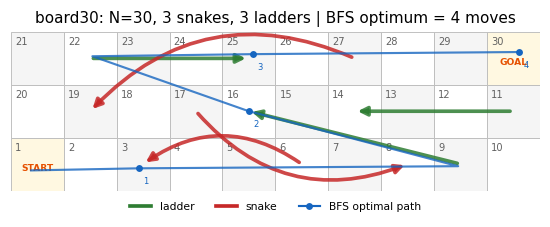

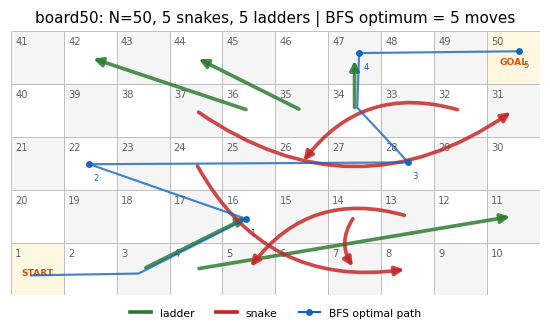

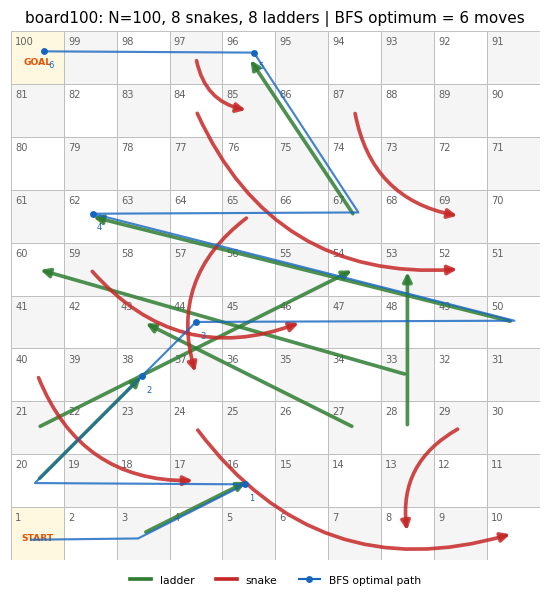

In [10]:
LADDER_C, SNAKE_C, PATH_C = "#2e7d32", "#c62828", "#1565c0"


def square_xy(square: int, cols: int = 10):
    idx = square - 1
    row, col = divmod(idx, cols)
    if row % 2 == 1:
        col = cols - 1 - col
    return col + 0.5, row + 0.5


def draw_board(board: Board, path=None, title=None, ax=None, cols=10, path_label="agent path"):
    rows = int(np.ceil(board.n / cols))
    if ax is None:
        _, ax = plt.subplots(figsize=(cols * 0.62, rows * 0.62 + 0.6))
    for s in range(1, board.n + 1):
        x, y = square_xy(s, cols)
        face = "#fff8e1" if s in (1, board.n) else ("#f5f5f5" if (s % 2) else "white")
        ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=face, edgecolor="#bdbdbd", lw=0.6))
        ax.text(x - 0.42, y + 0.40, str(s), fontsize=6.5, va="top", ha="left", color="#616161")
    for label, s in (("START", 1), ("GOAL", board.n)):
        x, y = square_xy(s, cols)
        ax.text(x, y - 0.12, label, fontsize=6, ha="center", fontweight="bold", color="#e65100")

    for a, b in board.ladders.items():
        ax.add_patch(FancyArrowPatch(square_xy(a, cols), square_xy(b, cols), arrowstyle="-|>",
                                     mutation_scale=12, lw=2.4, color=LADDER_C, alpha=0.85, zorder=3))
    for a, b in board.snakes.items():
        ax.add_patch(FancyArrowPatch(square_xy(a, cols), square_xy(b, cols), arrowstyle="-|>",
                                     connectionstyle="arc3,rad=0.35", mutation_scale=12, lw=2.4,
                                     color=SNAKE_C, alpha=0.85, zorder=3))
    handles = [Line2D([], [], color=LADDER_C, lw=2.4, label="ladder"),
               Line2D([], [], color=SNAKE_C, lw=2.4, label="snake")]

    if path is not None and len(path) > 1:
        # Expand each move so the line goes dice-move -> jump start -> jump end, following the arrow.
        trace, move_no = [path[0]], [None]
        for i, (p, q) in enumerate(zip(path[:-1], path[1:]), start=1):
            if q != p and not (1 <= q - p <= 6):
                start = next(t for t, e in board.jumps.items() if e == q and p < t <= p + 6)
                trace.append(start)
                move_no.append(None)
            trace.append(q)
            move_no.append(i)
        xy = np.array([square_xy(s, cols) for s in trace])
        xy = xy + np.linspace(-0.12, 0.12, len(trace))[:, None]       # separate repeated visits
        ax.plot(xy[:, 0], xy[:, 1], "-", color=PATH_C, lw=1.4, alpha=0.8, zorder=4)
        land = np.array([k is not None for k in move_no])
        ax.plot(xy[land, 0], xy[land, 1], "o", color=PATH_C, ms=3.5, zorder=4)
        for (x, y), k in zip(xy, move_no):
            if k is not None:
                ax.text(x + 0.08, y - 0.30, str(k), fontsize=5.5, color=PATH_C, zorder=5)
        handles.append(Line2D([], [], color=PATH_C, marker="o", ms=3.5, lw=1.4, label=path_label))

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3,
              fontsize=7, frameon=False)
    ax.set_title(title or board.name, fontsize=10)
    return ax


for name, b in boards.items():
    opt = bfs_optimal(b)
    ax = draw_board(b, path=opt["path"], path_label="BFS optimal path",
                    title=f"{name}: N={b.n}, {len(b.snakes)} snakes, {len(b.ladders)} ladders | "
                          f"BFS optimum = {opt['moves']} moves")
    plt.savefig(FIG_DIR / f"{name}_bfs.png", dpi=150, bbox_inches="tight")
    plt.show()

## 9. Baselines: how well do simple policies play?

**What this does:** runs three hand-made policies for 1,000 games on each board and measures them with the same metrics the RL agents will be judged on:

| Policy | Rule | Role |
|---|---|---|
| **Random** | Pick a dice value uniformly at random | The "before training" agent. Every learner must beat it |
| **Always 6** | Always choose 6 | A naive "move as far as possible" heuristic. It ignores snakes and overshooting, so it shows why a policy must depend on the square |
| **BFS** | Always choose an optimal dice value | The ceiling. Running it through the environment also checks that the environment and BFS agree |

**Metrics** (used for every agent from here on):
- **success rate**: percentage of games that reach square $N$ before the $4N$ move limit
- **average moves**: moves per game (failed games count the full $4N$)
- **average return**: total reward per game
- counts of ladders, snakes and invalid moves per game, which explain *why* a policy scores what it does

`run_episode` and `evaluate_policy` are reused unchanged to evaluate every trained agent in later sections.

In [11]:
def run_episode(env: SmartDiceEnv, policy, seed=None) -> dict:
    # Play one game with `policy(obs, env) -> action index`; return its metrics and the squares visited.
    obs, info = env.reset(seed=seed)
    total, path, events = 0.0, [info["position"]], Counter()
    terminated = truncated = False
    while not (terminated or truncated):
        obs, reward, terminated, truncated, info = env.step(policy(obs, env))
        total += reward
        events[info["event"]] += 1
        path.append(info["position"])
    return {"return": total, "moves": info["steps"], "success": bool(terminated),
            "ladders": events["ladder"], "snakes": events["snake"], "invalid": events["invalid"],
            "path": path}


def evaluate_policy(board: Board, policy, episodes=1_000, seed=SEED, obs_mode="index") -> pd.DataFrame:
    env = SmartDiceEnv(board, obs_mode=obs_mode)
    rows = [run_episode(env, policy, seed=seed + i) for i in range(episodes)]
    return pd.DataFrame(rows)


def summarize(df: pd.DataFrame) -> dict:
    return {"success %": 100 * df["success"].mean(),
            "avg moves": df["moves"].mean(),
            "avg return": df["return"].mean(),
            "ladders/game": df["ladders"].mean(),
            "snakes/game": df["snakes"].mean(),
            "invalid/game": df["invalid"].mean()}


class RandomPolicy:
    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def __call__(self, obs, env):
        return int(self.rng.integers(N_ACTIONS))


def always_six(obs, env):
    return N_ACTIONS - 1


def make_bfs_policy(board: Board):
    mask = optimal_action_mask(board)
    return lambda obs, env: int(np.argmax(mask[env.pos - 1]))

In [12]:
baseline_rows, baseline_runs = [], {}
for name, b in boards.items():
    policies = {"Random": RandomPolicy(SEED), "Always 6": always_six, "BFS": make_bfs_policy(b)}
    for pname, policy in policies.items():
        df = evaluate_policy(b, policy, episodes=1_000)
        baseline_runs[(name, pname)] = df
        baseline_rows.append({"board": name, "N": b.n, "policy": pname, **summarize(df)})

baselines = pd.DataFrame(baseline_rows)
bfs_moves = {name: bfs_optimal(b)["moves"] for name, b in boards.items()}
baselines.insert(3, "BFS optimum", baselines["board"].map(bfs_moves))
baselines.to_csv(RESULTS_DIR / "day1_baselines.csv", index=False)

# Sanity check: the environment and BFS agree exactly.
for name in boards:
    bfs_row = baselines[(baselines.board == name) & (baselines.policy == "BFS")].iloc[0]
    assert bfs_row["success %"] == 100 and bfs_row["avg moves"] == bfs_moves[name]

baselines.round(2)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,board,N,policy,BFS optimum,success %,avg moves,avg return,ladders/game,snakes/game,invalid/game
0,board30,30,Random,4,100.0,13.61,54.67,1.03,1.10,3.72
1,board30,30,Always 6,4,0.0,120.00,-1164.00,0.00,0.00,116.00
2,board30,30,BFS,4,100.0,4.00,139.00,2.00,0.00,0.00
3,board50,50,Random,5,100.0,21.06,26.47,1.28,2.31,4.04
4,board50,50,Always 6,5,100.0,8.00,95.00,1.00,1.00,0.00
5,board50,50,BFS,5,100.0,5.00,138.00,2.00,0.00,0.00
6,board100,100,Random,6,100.0,34.64,27.19,2.15,2.75,3.56
7,board100,100,Always 6,6,0.0,400.00,-3880.00,1.00,0.00,389.00
8,board100,100,BFS,6,100.0,6.00,179.00,4.00,0.00,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


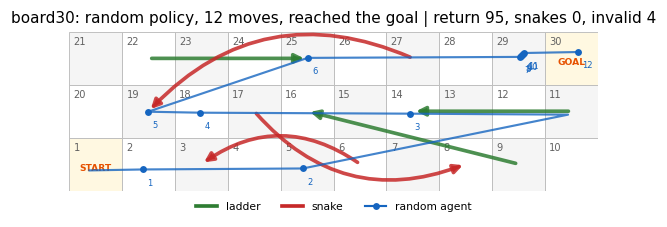

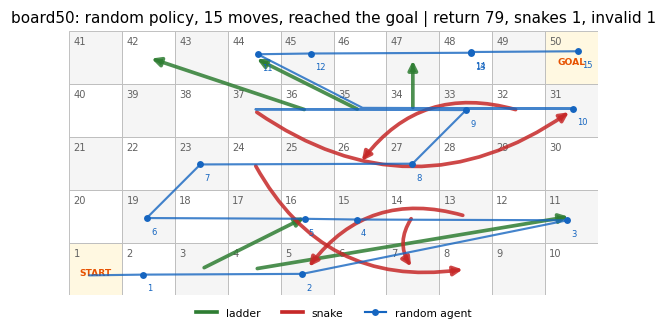

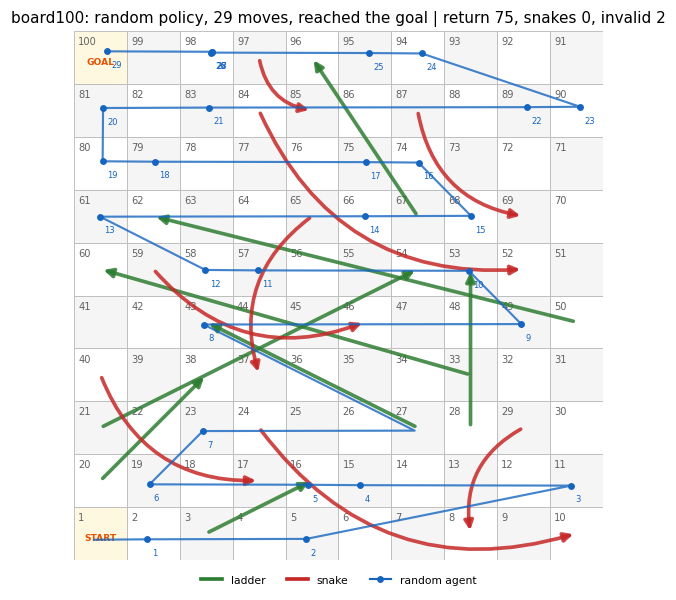

In [13]:
# One random game per board, drawn: the "agent before training" for the demonstration.
for name, b in boards.items():
    game = run_episode(SmartDiceEnv(b), RandomPolicy(SEED + 7), seed=SEED)
    outcome = "reached the goal" if game["success"] else "hit the move limit"
    shown = game["path"][:61]                                   # at most 60 moves, to stay readable
    draw_board(b, path=shown,
               path_label="random agent" + (" (first 60 moves)" if len(game["path"]) > 61 else ""),
               title=f"{name}: random policy, {game['moves']} moves, {outcome} | "
                     f"return {game['return']:.0f}, snakes {game['snakes']}, invalid {game['invalid']}")
    plt.savefig(FIG_DIR / f"{name}_random_game.png", dpi=150, bbox_inches="tight")
    plt.show()

### What the baselines show

*(Numbers from the run above. Board layouts and the random games are seeded, so they reproduce exactly.)*

- **Success rate alone does not separate policies here.** Even the random policy finishes 100% of games on all three boards. It needs 13.6, 21.1 and 34.6 moves on average, far inside the 120 / 200 / 400 move limits. So the metrics that actually measure learning are **average moves compared with the BFS optimum** (4, 5 and 6 moves) and **average return**. From Day 2, agents are also scored on the **share of squares where they pick an optimal dice value**.
- **There is plenty to learn, and more on bigger boards.** Random play takes about 3.4×, 4.2× and 5.8× the optimal number of moves on boards 30, 50 and 100. It hits 1.1–2.8 snakes per game, while BFS hits none and uses 2–4 ladders.
- **"Always 6" shows why the policy must depend on the square.** It never finishes board 30 or board 100. It gets stuck one roll short of the goal (on square 25 of board 30, and on square 96 of board 100 after a ladder), where every 6 overshoots and costs −10 until the move limit. On board 50 the same rule happens to work (8 moves). A fixed action can't be good everywhere. The best dice value depends on the current square, which is exactly what a state-dependent RL policy learns.
- **The environment and BFS agree:** the BFS policy, played through `SmartDiceEnv`, finishes every board in exactly the BFS number of moves. This is checked with an `assert` above.

### Day 1 checkpoint

- [x] Environment follows the brief's transition rule and passes hand-checked tests and `check_env`
- [x] Three seeded boards (30/3/3, 50/5/5, 100/8/8), each drawn with its BFS optimal path
- [x] BFS optimum: 4, 5 and 6 moves
- [x] Random, "always 6" and BFS baselines saved to `results/day1_baselines.csv`

**Next (Day 2):** tabular Q-Learning and SARSA with ε-greedy exploration, trained on all three boards with 3 seeds each.

## 10. Tabular RL: Q-Learning and SARSA

Both algorithms learn a **Q-table**: one row per square, one column per dice value. $Q(s,a)$ estimates the total discounted reward of choosing dice $a$ on square $s$ and playing well afterwards. The policy is read off the table: on each square, choose the dice with the highest $Q$.

Both are **temporal-difference (TD)** methods. After every move they nudge $Q(s,a)$ toward a *target* built from the reward just received plus their estimate of what comes next:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,\text{target} - Q(s,a)\,\big]$$

They differ only in the target:

| | Target | Type | What it learns |
|---|---|---|---|
| **Q-Learning** | $r + \gamma \max_{a'} Q(s', a')$ | off-policy | The value of the **best** action in the next state, even while exploring. It converges toward the optimal policy |
| **SARSA** | $r + \gamma\, Q(s', a')$ where $a'$ is the action actually chosen next | on-policy | The value of the policy it **actually follows**, exploration included. It learns what happens when it sometimes takes random moves |

The name SARSA comes from the five values used in one update: $(s, a, r, s', a')$.

If the episode **terminated** (goal reached), the target is just $r$: there is no future after the goal. If it was only **truncated** (move limit), the target still includes the next state's value, because the game itself was not over.

### 10.1 ε-greedy exploration

**What this does:** with probability ε the agent picks a random dice value (**explore**); otherwise it picks the dice with the highest Q-value (**exploit**). Ties are broken at random.

**Why random tie-breaking matters:** the Q-table starts at all zeros, so every action ties at first. A plain `argmax` would always return action 0 (dice 1), and the agent would crawl one square at a time.

**Schedule:** ε starts at 1.0 (pure exploration, since nothing is known yet) and decays exponentially to 0.05 over the first 60% of training episodes, then stays at 0.05. Early episodes gather information; later episodes use it while still trying an occasional random move.

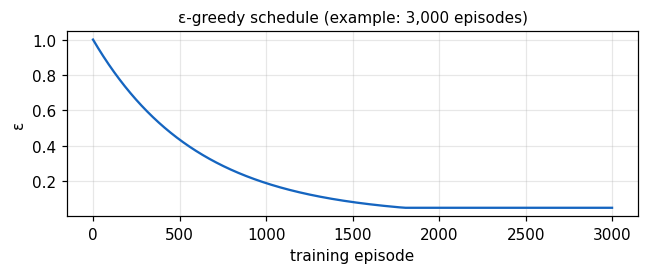

In [14]:
@dataclass
class TabularConfig:
    alpha: float = 0.1           # learning rate
    alpha_end: float = None      # None = constant alpha; else decays to alpha_end on the same schedule as epsilon
    gamma: float = GAMMA         # discount factor (0.99)
    eps_start: float = 1.0
    eps_end: float = 0.05
    eps_decay_frac: float = 0.6  # epsilon reaches eps_end after this fraction of the episodes
    q_init: float = 0.0          # initial Q-values
    eval_every: int = 10         # greedy evaluation every N training episodes


def epsilon_at(episode: int, episodes: int, cfg: TabularConfig) -> float:
    rate = (cfg.eps_end / cfg.eps_start) ** (1.0 / (cfg.eps_decay_frac * episodes))
    return max(cfg.eps_end, cfg.eps_start * rate ** episode)


def alpha_at(episode: int, episodes: int, cfg: TabularConfig) -> float:
    if cfg.alpha_end is None:
        return cfg.alpha
    rate = (cfg.alpha_end / cfg.alpha) ** (1.0 / (cfg.eps_decay_frac * episodes))
    return max(cfg.alpha_end, cfg.alpha * rate ** episode)


def epsilon_greedy(Q: np.ndarray, s: int, eps: float, rng: np.random.Generator) -> int:
    if rng.random() < eps:
        return int(rng.integers(N_ACTIONS))                 # explore
    best = np.flatnonzero(Q[s] == Q[s].max())               # exploit, random tie-break
    return int(rng.choice(best))


cfg_demo, eps_curve = TabularConfig(), [epsilon_at(e, 3_000, TabularConfig()) for e in range(3_000)]
plt.figure(figsize=(6, 2.6))
plt.plot(eps_curve, color=PATH_C)
plt.xlabel("training episode")
plt.ylabel("ε")
plt.title("ε-greedy schedule (example: 3,000 episodes)", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10.2 Measuring the learned policy

Training curves include exploration (random moves), so they understate how good the policy really is. The brief asks for evaluation on **separate games**, so every 10 training episodes the current Q-table is frozen and evaluated with **ε = 0** on a separate environment:

- **greedy moves** from square 1 to the goal, and whether it gets there at all
- **optimal-action %**: on every square the agent can actually stand on (all squares except snake heads and ladder bottoms, which it leaves immediately), is the greedy dice one of the BFS-optimal dice? This measures the **whole policy**, not just the one path from square 1.

**Which "optimal"?** BFS minimises the **number of moves**, but RL maximises the **discounted return**. These can differ: an extra ladder (+20) can be worth one extra move (−1). So the true target of Q-Learning and SARSA is computed exactly with **value iteration**, which repeatedly applies the Bellman optimality equation to the known rules until it converges:

$$Q^*(s,a) = r(s,a) + \gamma \max_{a'} Q^*(s',a') \quad (\text{no future term if } s' = N)$$

Value iteration is a planning method: it needs the rules. It is used only to *grade* the agents, like BFS. The policy-quality metric therefore has two versions:
- **optimal-action % (Q\*)**: the greedy dice is return-optimal. This is what RL is actually trying to learn.
- **optimal-action % (BFS)**: the greedy dice is move-optimal.

**One evaluation game is enough.** In this game both the environment and the greedy policy are deterministic, so repeating the game gives exactly the same result. (Stochastic versions in Challenge 1 will need many games.)

**Late stability:** the % of evaluations in the last 20% of training where the greedy game is optimal. A policy can end optimal but keep flipping in and out of optimality, and this metric shows that.

**Convergence criterion** (needed for the report): the first evaluation point from which the greedy policy **reaches the goal in exactly the BFS-optimal number of moves and keeps doing so at every later evaluation**. A looser version, *near-optimal* (within 1 move of BFS), is reported too.

*Why not success rate?* Section 9 showed that even the random policy finishes 100% of games, so success rate cannot mark convergence here. Matching BFS can.

In [15]:
def playable_squares(board: Board) -> list:
    # Squares the agent can stand on: not the goal, not a snake head or ladder bottom.
    return [s for s in range(1, board.n) if s not in board.jumps]


def value_iteration(board: Board, gamma: float = GAMMA, rewards: dict = REWARDS, tol: float = 1e-10) -> np.ndarray:
    # Exact Q* for the known deterministic rules (rows = squares 1..N, columns = dice 1..6).
    nxt = np.zeros((board.n, N_ACTIONS), dtype=int)
    rew = np.zeros((board.n, N_ACTIONS))
    term = np.zeros((board.n, N_ACTIONS), dtype=bool)
    for s in range(1, board.n):
        for a in range(N_ACTIONS):
            t, r, done, _ = transition(board, s, a + 1, rewards)
            nxt[s - 1, a], rew[s - 1, a], term[s - 1, a] = t - 1, r, done
    Q = np.zeros((board.n, N_ACTIONS))
    for _ in range(100_000):
        V = Q.max(axis=1)
        V[board.n - 1] = 0.0
        Q_new = rew + gamma * np.where(term, 0.0, V[nxt])
        Q_new[board.n - 1] = 0.0
        if np.abs(Q_new - Q).max() < tol:
            return Q_new
        Q = Q_new
    raise RuntimeError("value iteration did not converge")


def qstar_action_mask(Qstar: np.ndarray, atol: float = 1e-6) -> np.ndarray:
    return np.isclose(Qstar, Qstar.max(axis=1, keepdims=True), atol=atol)


def greedy_policy_from_q(Q: np.ndarray):
    return lambda obs, env: int(np.argmax(Q[obs]))


def evaluate_q(Q: np.ndarray, board: Board, masks: dict, squares: list, rewards: dict = None) -> dict:
    # masks = {"qstar": return-optimal actions, "bfs": move-optimal actions}
    game = run_episode(SmartDiceEnv(board, obs_mode="index", rewards=rewards), greedy_policy_from_q(Q))
    rows = np.array(squares) - 1
    greedy = Q[rows].argmax(axis=1)
    return {"greedy_moves": game["moves"], "greedy_success": game["success"],
            "greedy_return": game["return"],
            "optimal_action_pct": 100 * masks["qstar"][rows, greedy].mean(),
            "bfs_action_pct": 100 * masks["bfs"][rows, greedy].mean()}


# Value iteration per board, and a check that the return-optimal game is also the shortest game.
qstar = {name: value_iteration(b) for name, b in boards.items()}
masks = {name: {"qstar": qstar_action_mask(qstar[name]), "bfs": optimal_action_mask(b)} for name, b in boards.items()}
for name, b in boards.items():
    game = run_episode(SmartDiceEnv(b), greedy_policy_from_q(qstar[name]))
    agree = 100 * (masks[name]["qstar"] == masks[name]["bfs"])[np.array(playable_squares(b)) - 1].all(axis=1).mean()
    print(f"{name}: Q* plays {game['moves']} moves (BFS {bfs_moves[name]}), return {game['return']:.0f}, "
          f"V*(1) = {qstar[name][0].max():.2f} | optimal dice sets identical on {agree:.0f}% of squares")


def late_stability(evals: pd.DataFrame, bfs_moves: int, last_frac: float = 0.2, x: str = "episode") -> float:
    # % of evaluations in the last 20% of training where the greedy game is optimal.
    tail = evals[evals[x] > (1 - last_frac) * evals[x].max()]
    return 100 * (tail["greedy_success"] & (tail["greedy_moves"] == bfs_moves)).mean()


def convergence_episode(evals: pd.DataFrame, bfs_moves: int, tolerance: int = 0, x: str = "episode"):
    # First evaluation point (episode, or env step with x="env_steps") from which the greedy
    # policy stays within `tolerance` moves of BFS.
    ok = (evals["greedy_success"] & (evals["greedy_moves"] <= bfs_moves + tolerance)).to_numpy()
    if not ok[-1]:
        return np.nan
    bad = np.flatnonzero(~ok)
    return int(evals[x].iloc[0 if len(bad) == 0 else bad[-1] + 1])

board30: Q* plays 4 moves (BFS 4), return 139, V*(1) = 135.43 | optimal dice sets identical on 70% of squares
board50: Q* plays 5 moves (BFS 5), return 138, V*(1) = 133.50 | optimal dice sets identical on 100% of squares
board100: Q* plays 6 moves (BFS 6), return 179, V*(1) = 172.54 | optimal dice sets identical on 87% of squares


### 10.3 The training loop (shared by both algorithms)

One function trains either algorithm, so the comparison differs **only** in the update rule:

1. Start each episode on square 1 with the current ε.
2. Choose an action with ε-greedy, play it, observe $(r, s')$.
3. **SARSA** picks its next action $a'$ *first* and updates toward $Q(s',a')$. **Q-Learning** updates toward $\max_{a'} Q(s',a')$ and *then* picks its next action from the updated table.
4. Log every episode (return, moves, success, ε, cumulative environment steps), and run the greedy evaluation every 10 episodes.

Environment steps are logged as well as episodes because Day 3's deep-RL agents count training in steps. Steps are the only fair common x-axis for all five agents.

**Hyperparameters:** α = 0.1, γ = 0.99, Q initialised to 0. Episode budgets are 6,000 / 9,000 / 15,000 for boards 30 / 50 / 100: larger boards have more squares to learn. Training is cheap (about a second per run), so the budgets are set generously. In a pilot with 5 seeds, 2,000 / 3,000 / 5,000 episodes still left some board-50 runs one move above the optimum, and tripling the budgets removed that gap. Section 10.6 shows how many episodes are actually needed. Each (algorithm, board) pair is trained with **3 seeds**, and results are reported as mean ± standard deviation.

In [16]:
def train_tabular(algo: str, board: Board, episodes: int, seed: int, cfg: TabularConfig = None,
                  rewards: dict = None, eval_masks: dict = None):
    # rewards / eval_masks: optional reward table and matching Q* masks (used by Challenge 6).
    assert algo in ("qlearning", "sarsa")
    cfg = cfg or TabularConfig()
    rng = np.random.default_rng(seed)
    env = SmartDiceEnv(board, obs_mode="index", rewards=rewards)
    eval_masks = eval_masks or masks[board.name]
    Q = np.full((board.n, N_ACTIONS), cfg.q_init, dtype=np.float64)
    Q[board.n - 1] = 0.0                                   # the goal square has no future value
    squares = playable_squares(board)

    log, evals, total_steps = [], [], 0
    for ep in range(episodes):
        eps, alpha = epsilon_at(ep, episodes, cfg), alpha_at(ep, episodes, cfg)
        s, _ = env.reset(seed=seed * 100_000 + ep)
        a = epsilon_greedy(Q, s, eps, rng)
        ep_return, terminated, truncated = 0.0, False, False
        while not (terminated or truncated):
            s2, r, terminated, truncated, info = env.step(a)
            ep_return += r
            if algo == "sarsa":
                a2 = epsilon_greedy(Q, s2, eps, rng)                       # choose a' first
                target = r if terminated else r + cfg.gamma * Q[s2, a2]
                Q[s, a] += alpha * (target - Q[s, a])
            else:
                target = r if terminated else r + cfg.gamma * Q[s2].max()
                Q[s, a] += alpha * (target - Q[s, a])
                a2 = epsilon_greedy(Q, s2, eps, rng)                       # then choose a'
            s, a = s2, a2
        total_steps += info["steps"]
        log.append({"episode": ep + 1, "env_steps": total_steps, "return": ep_return,
                    "moves": info["steps"], "success": bool(terminated), "epsilon": eps})
        if ep == 0 or (ep + 1) % cfg.eval_every == 0:
            evals.append({"episode": ep + 1, "env_steps": total_steps,
                          **evaluate_q(Q, board, eval_masks, squares, rewards)})
    return Q, pd.DataFrame(log), pd.DataFrame(evals)

### 10.4 Training on all boards

**What this does:** trains 2 algorithms × 3 boards × 3 seeds = 18 runs (well under a minute in total on a laptop CPU). Each run's Q-table, episode log and evaluation log are saved under `results/tabular/`. When the cell runs again, saved runs are loaded instead of retrained.

In [17]:
import time

ALGOS = {"qlearning": "Q-Learning", "sarsa": "SARSA"}
TAB_EPISODES = {"board30": 6_000, "board50": 9_000, "board100": 15_000}
TAB_SEEDS = [0, 1, 2]
TAB_DIR = RESULTS_DIR / "tabular"
TAB_DIR.mkdir(parents=True, exist_ok=True)

tabular = {}   # (algo, board, seed) -> dict(Q, log, evals, seconds)
for name, b in boards.items():
    for algo in ALGOS:
        for seed in TAB_SEEDS:
            stem = TAB_DIR / f"{algo}_{name}_seed{seed}"
            if FORCE_RETRAIN or not stem.with_suffix(".npy").exists():
                t0 = time.perf_counter()
                Q, log, evals = train_tabular(algo, b, TAB_EPISODES[name], seed)
                seconds = time.perf_counter() - t0
                np.save(stem.with_suffix(".npy"), Q)
                log.assign(seconds=seconds).to_csv(f"{stem}_log.csv", index=False)
                evals.to_csv(f"{stem}_evals.csv", index=False)
            else:
                Q = np.load(stem.with_suffix(".npy"))
                log = pd.read_csv(f"{stem}_log.csv")
                evals = pd.read_csv(f"{stem}_evals.csv")
                seconds = float(log["seconds"].iloc[0]) if "seconds" in log else np.nan
            tabular[(algo, name, seed)] = {"Q": Q, "log": log, "evals": evals, "seconds": seconds}
        print(f"{name:>8} | {ALGOS[algo]:<10} done")

 board30 | Q-Learning done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 board30 | SARSA      done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 board50 | Q-Learning done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

board100 | Q-Learning done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


board100 | SARSA      done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 10.5 Results: Q-Learning vs SARSA vs BFS

The table reports, for each board and algorithm, the mean ± std over 3 seeds of:

- **greedy moves / gap to BFS**: the learned policy's game from square 1, compared with the optimum
- **optimal-action % (Q\*) / (BFS)**: share of playable squares where the greedy dice is return-optimal / move-optimal
- **train return / moves (last 100)**: average over the last 100 *training* episodes, which still include ε = 0.05 exploration
- **episodes to optimal / near-optimal**: the convergence criterion from Section 10.2
- **late stability %**: how often the greedy game is optimal during the last 20% of training

In [18]:
def mean_std(values, fmt="{:.1f}"):
    v = np.asarray(values, dtype=float)
    if np.isnan(v).all():
        return "not reached"
    note = "" if not np.isnan(v).any() else f" ({np.isnan(v).sum()} seed(s) not reached)"
    return f"{fmt.format(np.nanmean(v))} ± {fmt.format(np.nanstd(v))}{note}"


rows, raw = [], []
for name, b in boards.items():
    for algo, label in ALGOS.items():
        runs = [tabular[(algo, name, s)] for s in TAB_SEEDS]
        final = [r["evals"].iloc[-1] for r in runs]
        rec = {
            "board": name, "algorithm": label, "BFS optimum": bfs_moves[name],
            "greedy moves": [f["greedy_moves"] for f in final],
            "gap to BFS": [f["greedy_moves"] - bfs_moves[name] for f in final],
            "optimal-action % (Q*)": [f["optimal_action_pct"] for f in final],
            "optimal-action % (BFS)": [f["bfs_action_pct"] for f in final],
            "greedy return": [f["greedy_return"] for f in final],
            "train return (last 100)": [r["log"]["return"].tail(100).mean() for r in runs],
            "train moves (last 100)": [r["log"]["moves"].tail(100).mean() for r in runs],
            "episodes to optimal": [convergence_episode(r["evals"], bfs_moves[name], 0) for r in runs],
            "episodes to near-optimal": [convergence_episode(r["evals"], bfs_moves[name], 1) for r in runs],
            "late stability %": [late_stability(r["evals"], bfs_moves[name]) for r in runs],
            "train time (s)": [r["seconds"] for r in runs],
        }
        raw.append(rec)
        rows.append({k: (mean_std(v, "{:.0f}" if k.startswith("episodes") else "{:.1f}")
                         if isinstance(v, list) else v) for k, v in rec.items()})

tabular_summary = pd.DataFrame(rows)
pd.DataFrame(raw).to_csv(RESULTS_DIR / "tabular_summary_raw.csv", index=False)
tabular_summary.to_csv(RESULTS_DIR / "tabular_summary.csv", index=False)
tabular_summary

,board,algorithm,BFS optimum,greedy moves,gap to BFS,optimal-action % (Q*),optimal-action % (BFS),greedy return,train return (last 100),train moves (last 100),episodes to optimal,episodes to near-optimal,late stability %,train time (s)
0,board30,Q-Learning,4,4.0 ± 0.0,0.0 ± 0.0,91.3 ± 3.5,95.7 ± 3.5,139.0 ± 0.0,138.4 ± 0.1,4.2 ± 0.0,50 ± 24,20 ± 14,100.0 ± 0.0,1.2 ± 0.0
1,board30,SARSA,4,4.0 ± 0.0,0.0 ± 0.0,100.0 ± 0.0,95.7 ± 0.0,139.0 ± 0.0,138.6 ± 0.3,4.2 ± 0.0,2000 ± 2730,13 ± 5,99.4 ± 0.8,1.1 ± 0.0
2,board50,Q-Learning,5,5.0 ± 0.0,0.0 ± 0.0,88.9 ± 3.2,88.9 ± 3.2,138.0 ± 0.0,136.7 ± 0.6,5.3 ± 0.0,437 ± 314,73 ± 48,100.0 ± 0.0,2.6 ± 0.4
3,board50,SARSA,5,5.0 ± 0.0,0.0 ± 0.0,98.3 ± 1.2,98.3 ± 1.2,138.0 ± 0.0,136.0 ± 0.7,5.6 ± 0.3,8923 ± 54,5587 ± 3763,64.1 ± 15.1,2.0 ± 0.0
4,board100,Q-Learning,6,6.0 ± 0.0,0.0 ± 0.0,87.1 ± 5.7,88.8 ± 6.2,179.0 ± 0.0,177.2 ± 0.2,6.4 ± 0.0,60 ± 57,33 ± 33,100.0 ± 0.0,4.6 ± 0.4
5,board100,SARSA,6,6.0 ± 0.0,0.0 ± 0.0,92.0 ± 3.7,96.4 ± 1.0,179.0 ± 0.0,176.8 ± 0.6,6.4 ± 0.1,14433 ± 258,9023 ± 6327,94.3 ± 0.7,4.1 ± 0.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 10.6 Learning curves: Q-Learning vs SARSA

One row per board. Solid lines are the mean over 3 seeds; shaded bands are ± one standard deviation.

1. **Total reward** per training episode (rolling mean over 50 episodes)
2. **Moves** per training episode (rolling 50), with the greedy policy's moves (dotted) and the BFS optimum (dashed)
3. **Success rate** over the last 100 training episodes
4. **Optimal-action % (Q\*)** of the greedy policy

These are the brief's required plots (reward, moves and success rate vs episodes, and a Q-Learning vs SARSA comparison). Day 4 adds the deep-RL agents to the same axes.

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1984: PyparsingDeprecationWarning: 'setName' deprecated - use 'set_name'
  val.setName(key)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1987: PyparsingDeprecationWarning: 'setParseA

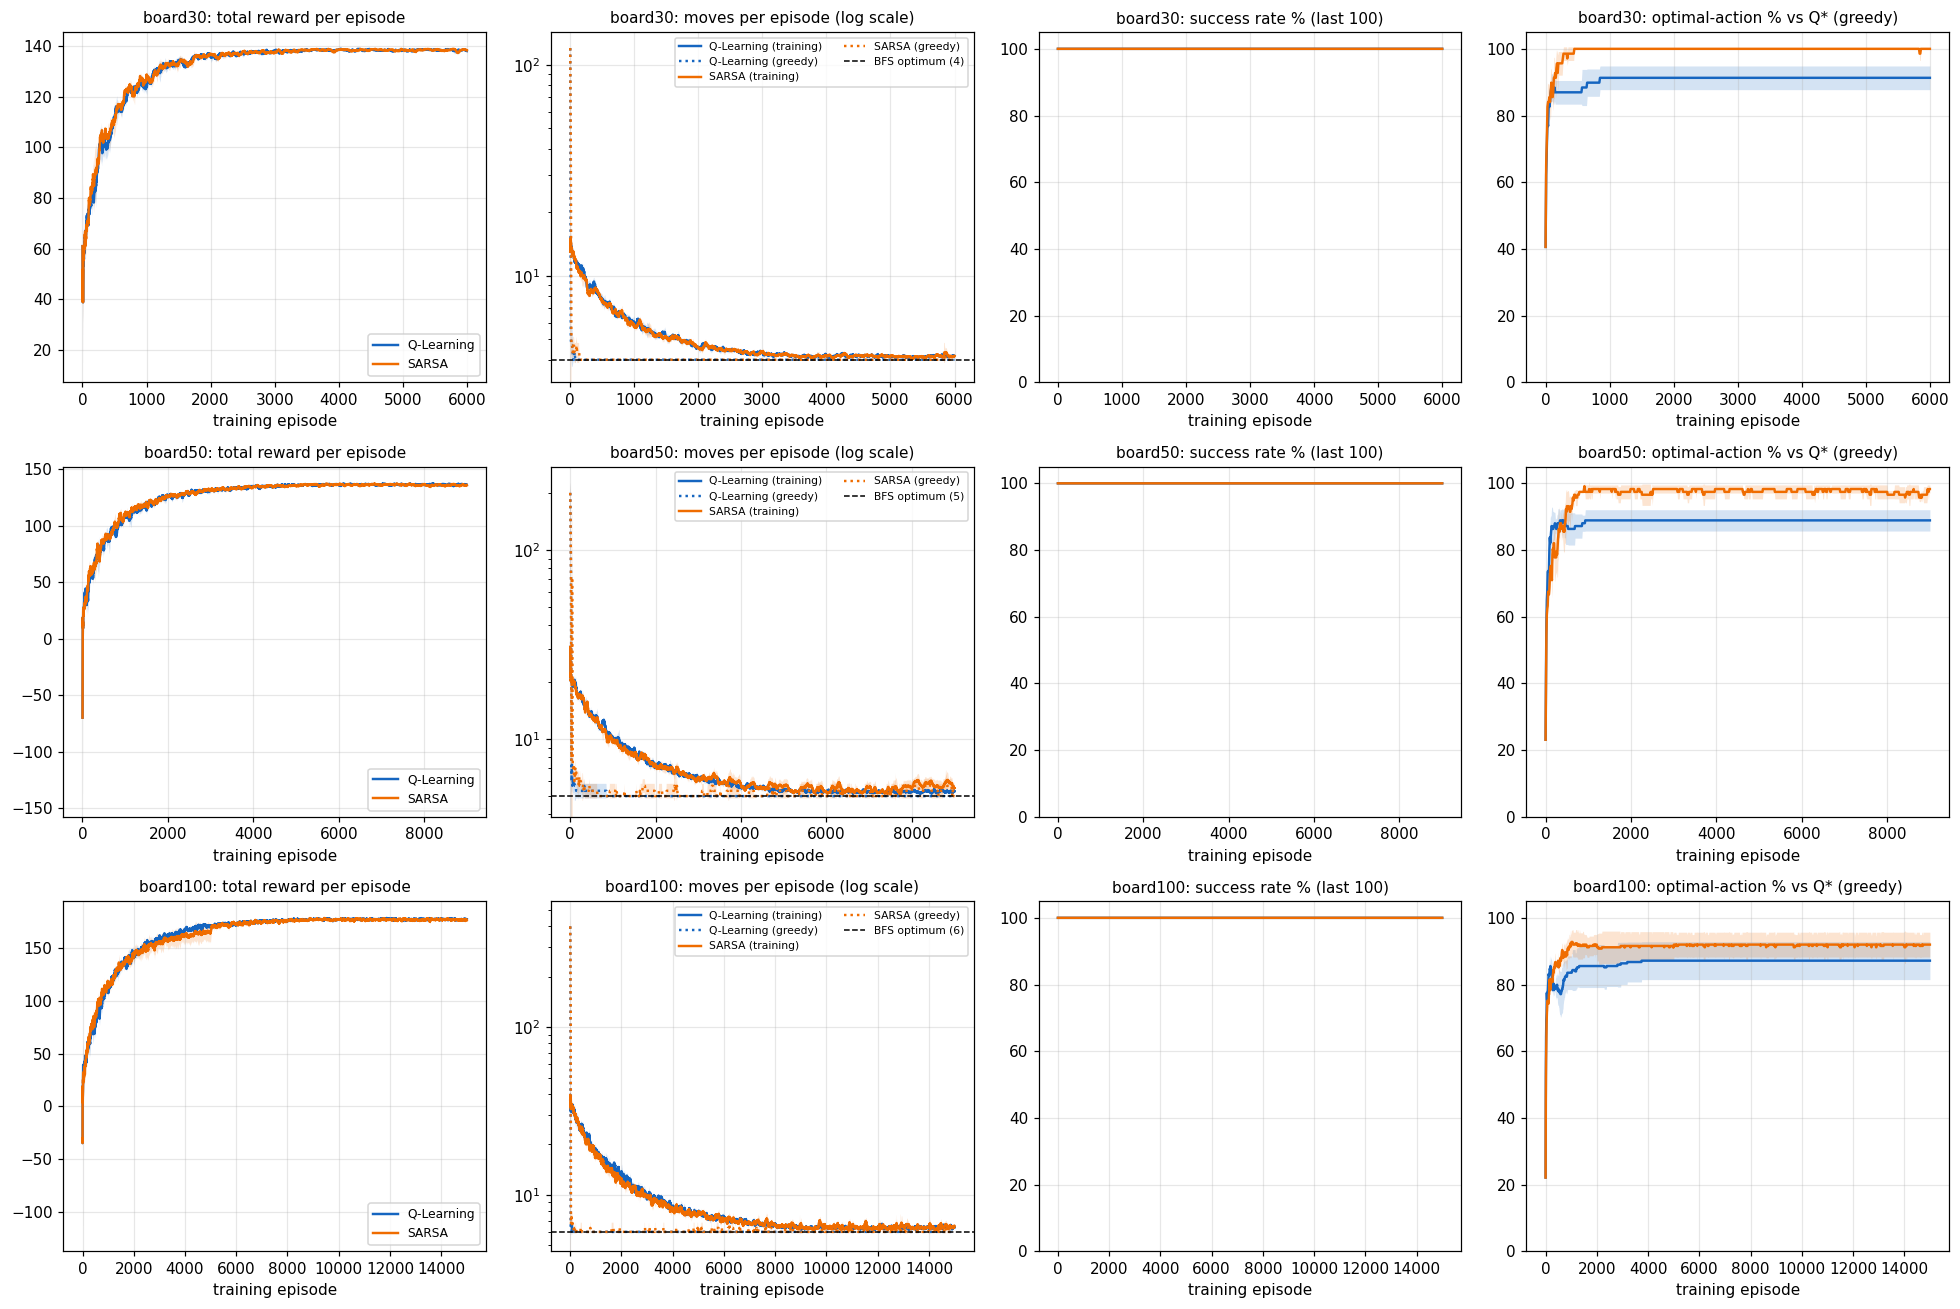

In [19]:
ALGO_COLORS = {"qlearning": "#1565c0", "sarsa": "#ef6c00"}


def band(ax, x, runs, color, label, ls="-"):
    arr = np.vstack(runs)
    mean, std = arr.mean(axis=0), arr.std(axis=0)
    ax.plot(x, mean, ls, color=color, lw=1.6, label=label)
    ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.18, lw=0)


fig, axes = plt.subplots(len(boards), 4, figsize=(18, 4.0 * len(boards)))
for row, (name, b) in enumerate(boards.items()):
    ax_ret, ax_mov, ax_suc, ax_opt = axes[row]
    for algo, label in ALGOS.items():
        runs = [tabular[(algo, name, s)] for s in TAB_SEEDS]
        c = ALGO_COLORS[algo]
        x = runs[0]["log"]["episode"].to_numpy()
        xe = runs[0]["evals"]["episode"].to_numpy()
        band(ax_ret, x, [r["log"]["return"].rolling(50, min_periods=1).mean() for r in runs], c, label)
        band(ax_mov, x, [r["log"]["moves"].rolling(50, min_periods=1).mean() for r in runs], c, f"{label} (training)")
        band(ax_mov, xe, [r["evals"]["greedy_moves"].to_numpy() for r in runs], c, f"{label} (greedy)", ls=":")
        band(ax_suc, x, [100 * r["log"]["success"].astype(float).rolling(100, min_periods=1).mean() for r in runs], c, label)
        band(ax_opt, xe, [r["evals"]["optimal_action_pct"].to_numpy() for r in runs], c, label)
    ax_mov.axhline(bfs_moves[name], color="k", ls="--", lw=1, label=f"BFS optimum ({bfs_moves[name]})")
    ax_mov.set_yscale("log")
    ax_suc.set_ylim(0, 105)
    ax_opt.set_ylim(0, 105)
    for ax, t in zip(axes[row], ["total reward per episode", "moves per episode (log scale)",
                                  "success rate % (last 100)", "optimal-action % vs Q* (greedy)"]):
        ax.set_title(f"{name}: {t}", fontsize=10)
        ax.set_xlabel("training episode")
        ax.grid(alpha=0.3)
    ax_ret.legend(fontsize=8)
    ax_mov.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "tabular_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.7 Where do Q-Learning and SARSA choose differently?

**What this does:** for seed 0 on each board, lists every playable square where the two greedy policies pick different dice, marks which choice is return-optimal (Q\*), and reports how many squares away the nearest snake head is. Then it draws both greedy games on the board.

**Why:** this is the direct evidence for report questions 5 and 6 (how the algorithms differ, and why they can converge to different policies).

board30: policies differ on 4 of 23 playable squares


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,square,Q-Learning dice,Q-L optimal?,SARSA dice,SARSA optimal?,Q*-optimal dice,snake head within reach
0,2,6,True,1,True,"[1, 2, 3, 5, 6]",4 ahead
1,10,6,False,1,True,[1],-
2,14,2,True,5,True,"[2, 4, 5, 6]",3 ahead
3,23,2,True,5,True,"[1, 2, 3, 5, 6]",4 ahead


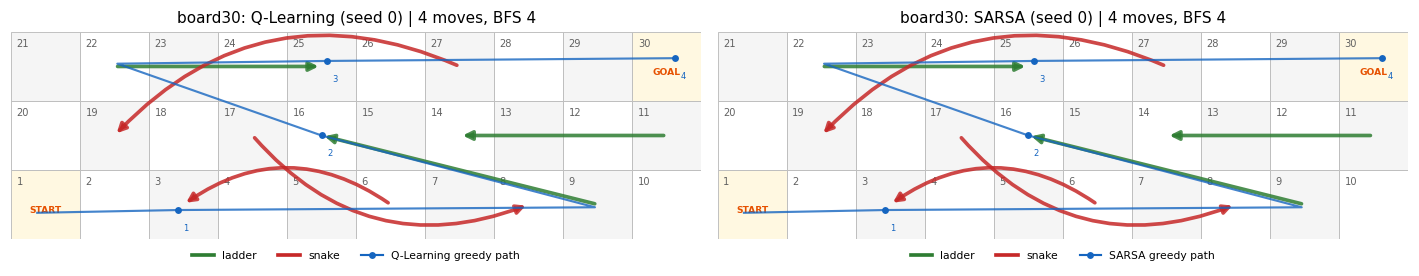

board50: policies differ on 19 of 39 playable squares


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,square,Q-Learning dice,Q-L optimal?,SARSA dice,SARSA optimal?,Q*-optimal dice,snake head within reach
0,2,2,False,1,True,[1],-
1,5,6,True,5,True,"[5, 6]",-
2,6,4,True,5,True,"[4, 5, 6]",-
3,7,5,True,3,True,"[3, 4, 5]",6 ahead
4,8,4,True,3,True,"[2, 3, 4]",5 ahead
5,9,3,True,6,True,"[1, 2, 3, 6]",4 ahead
6,12,4,True,6,True,"[4, 5, 6]",1 ahead
7,15,5,True,6,True,"[1, 2, 3, 4, 5, 6]",-
8,17,6,True,4,False,"[5, 6]",-
9,18,4,True,5,True,"[4, 5]",6 ahead


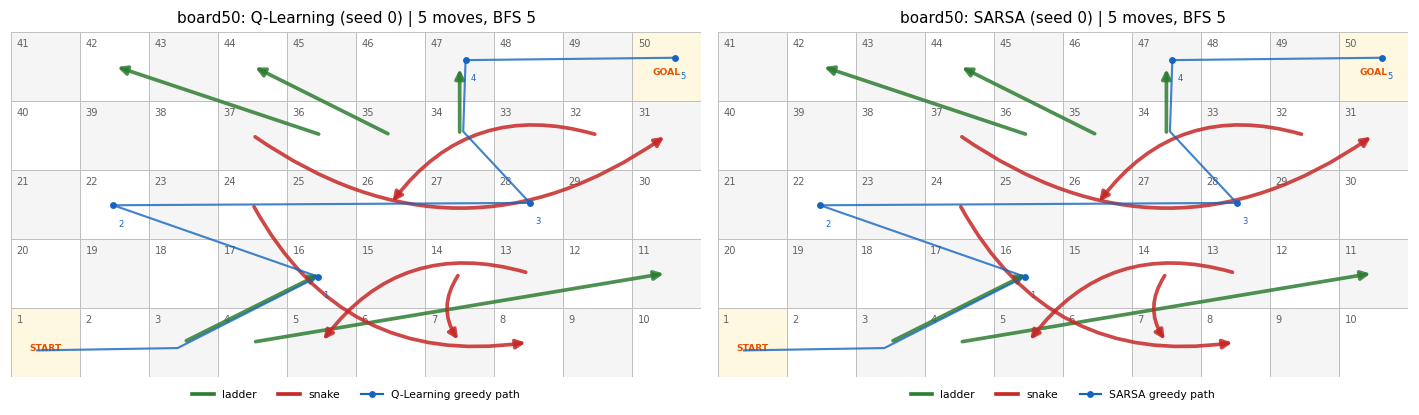

board100: policies differ on 29 of 83 playable squares


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,square,Q-Learning dice,Q-L optimal?,SARSA dice,SARSA optimal?,Q*-optimal dice,snake head within reach
0,7,3,True,5,True,"[1, 2, 3, 4, 5, 6]",-
1,8,2,False,6,True,[6],-
2,9,6,True,5,True,"[5, 6]",-
3,11,6,True,5,True,"[3, 4, 5, 6]",-
4,13,6,True,3,True,"[1, 2, 3, 4, 5, 6]",-
5,25,3,False,2,True,[2],4 ahead
6,32,6,False,1,True,[1],-
7,36,6,True,2,True,"[2, 3, 5, 6]",4 ahead
8,37,5,True,6,True,"[1, 2, 4, 5, 6]",3 ahead
9,41,5,True,3,True,"[3, 4, 5, 6]",-


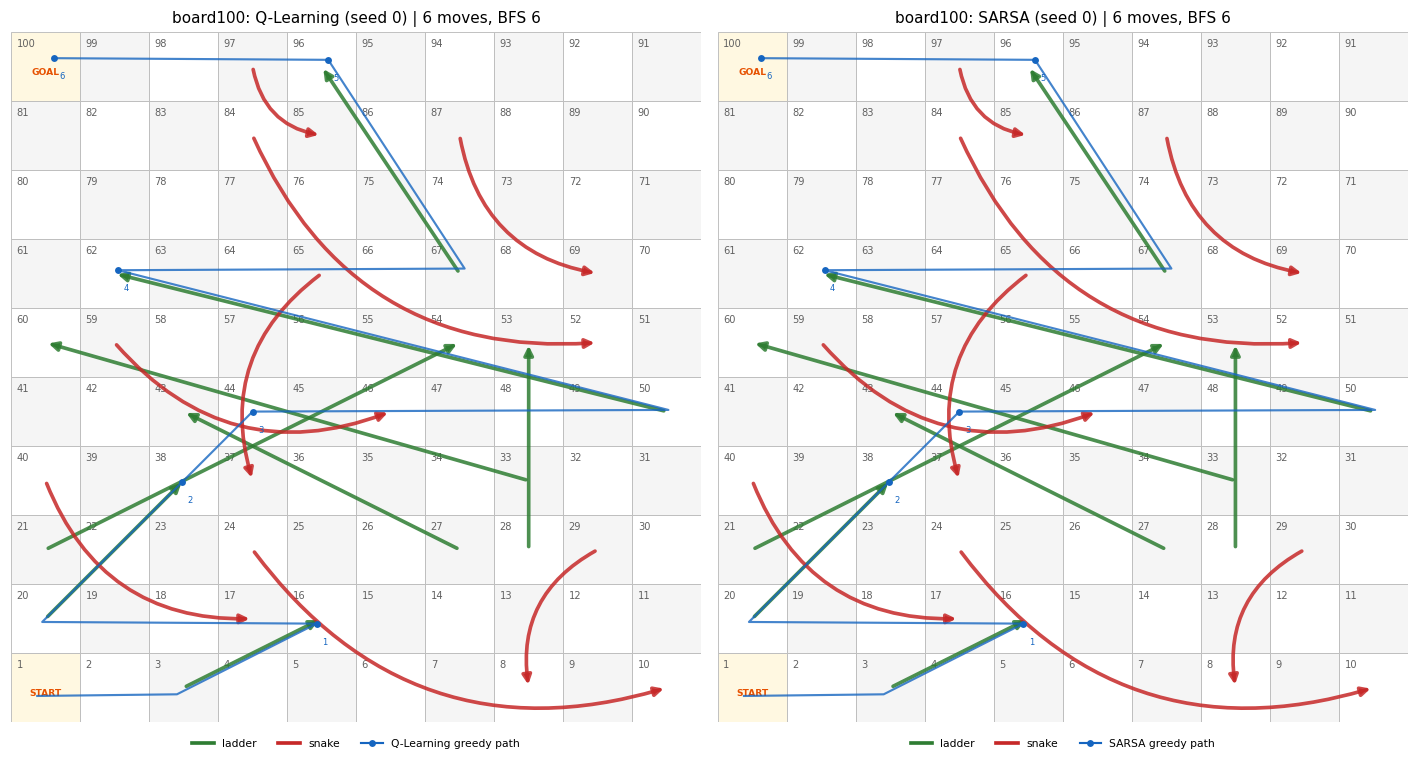

In [20]:
def policy_differences(board: Board, Qa: np.ndarray, Qb: np.ndarray) -> pd.DataFrame:
    mask, rows = masks[board.name]["qstar"], []
    for s in playable_squares(board):
        a, b2 = int(Qa[s - 1].argmax()), int(Qb[s - 1].argmax())
        if a != b2:
            ahead = [h - s for h in board.snakes if 1 <= h - s <= 6]
            rows.append({"square": s,
                         "Q-Learning dice": a + 1, "Q-L optimal?": bool(mask[s - 1, a]),
                         "SARSA dice": b2 + 1, "SARSA optimal?": bool(mask[s - 1, b2]),
                         "Q*-optimal dice": [d + 1 for d in np.flatnonzero(mask[s - 1])],
                         "snake head within reach": f"{min(ahead)} ahead" if ahead else "-"})
    return pd.DataFrame(rows)


for name, b in boards.items():
    Qq, Qs = tabular[("qlearning", name, 0)]["Q"], tabular[("sarsa", name, 0)]["Q"]
    diff = policy_differences(b, Qq, Qs)
    print(f"{name}: policies differ on {len(diff)} of {len(playable_squares(b))} playable squares")
    if len(diff):
        display(diff)

    fig, axes = plt.subplots(1, 2, figsize=(13, 0.62 * np.ceil(b.n / 10) + 1.6))
    for ax, (algo, Q) in zip(axes, (("Q-Learning", Qq), ("SARSA", Qs))):
        game = run_episode(SmartDiceEnv(b), greedy_policy_from_q(Q))
        draw_board(b, path=game["path"][:61], ax=ax, path_label=f"{algo} greedy path",
                   title=f"{name}: {algo} (seed 0) | {game['moves']} moves, BFS {bfs_moves[name]}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}_tabular_policies.png", dpi=150, bbox_inches="tight")
    plt.show()

### 10.8 Follow-up experiment: a decaying learning rate

**Question:** is SARSA's late instability (low *late stability %* in Section 10.5) caused by its noisier update target?

**Reasoning:** the environment is deterministic, so Q-Learning's target $r + \gamma \max_{a'} Q(s',a')$ is deterministic too. SARSA's target $r + \gamma Q(s',a')$ depends on $a'$, which is random 5% of the time. With a **constant** α = 0.1, each noisy target keeps moving the Q-values. When two routes have almost the same value, the greedy choice keeps flipping between them. Stochastic-approximation theory says the noise averages out only if α decreases over time.

**Experiment:** retrain both algorithms with α decaying from 0.1 to 0.01 on the same schedule as ε. Everything else (seeds, episodes, ε, boards) is unchanged.

In [21]:
ALPHA_DIR = TAB_DIR / "alpha_decay"
ALPHA_DIR.mkdir(parents=True, exist_ok=True)
decay_cfg = TabularConfig(alpha_end=0.01)

tabular_decay = {}
for name, b in boards.items():
    for algo in ALGOS:
        for seed in TAB_SEEDS:
            stem = ALPHA_DIR / f"{algo}_{name}_seed{seed}"
            if FORCE_RETRAIN or not stem.with_suffix(".npy").exists():
                Q, log, evals = train_tabular(algo, b, TAB_EPISODES[name], seed, decay_cfg)
                np.save(stem.with_suffix(".npy"), Q)
                log.to_csv(f"{stem}_log.csv", index=False)
                evals.to_csv(f"{stem}_evals.csv", index=False)
            else:
                Q, evals = np.load(stem.with_suffix(".npy")), pd.read_csv(f"{stem}_evals.csv")
                log = pd.read_csv(f"{stem}_log.csv")
            tabular_decay[(algo, name, seed)] = {"Q": Q, "log": log, "evals": evals}

rows = []
for name in boards:
    for algo, label in ALGOS.items():
        for schedule, store in (("constant 0.1", tabular), ("0.1 -> 0.01", tabular_decay)):
            runs = [store[(algo, name, s)] for s in TAB_SEEDS]
            rows.append({
                "board": name, "algorithm": label, "alpha": schedule,
                "gap to BFS": mean_std([r["evals"]["greedy_moves"].iloc[-1] - bfs_moves[name] for r in runs]),
                "optimal-action % (Q*)": mean_std([r["evals"]["optimal_action_pct"].iloc[-1] for r in runs]),
                "late stability %": mean_std([late_stability(r["evals"], bfs_moves[name]) for r in runs]),
                "episodes to optimal": mean_std([convergence_episode(r["evals"], bfs_moves[name]) for r in runs], "{:.0f}"),
            })
alpha_ablation = pd.DataFrame(rows)
alpha_ablation.to_csv(RESULTS_DIR / "tabular_alpha_ablation.csv", index=False)
alpha_ablation

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,board,algorithm,alpha,gap to BFS,optimal-action % (Q*),late stability %,episodes to optimal
0,board30,Q-Learning,constant 0.1,0.0 ± 0.0,91.3 ± 3.5,100.0 ± 0.0,50 ± 24
1,board30,Q-Learning,0.1 -> 0.01,0.0 ± 0.0,89.9 ± 4.1,100.0 ± 0.0,27 ± 17
2,board30,SARSA,constant 0.1,0.0 ± 0.0,100.0 ± 0.0,99.4 ± 0.8,2000 ± 2730
3,board30,SARSA,0.1 -> 0.01,0.0 ± 0.0,100.0 ± 0.0,100.0 ± 0.0,117 ± 66
4,board50,Q-Learning,constant 0.1,0.0 ± 0.0,88.9 ± 3.2,100.0 ± 0.0,437 ± 314
5,board50,Q-Learning,0.1 -> 0.01,0.0 ± 0.0,89.7 ± 2.1,100.0 ± 0.0,383 ± 408
6,board50,SARSA,constant 0.1,0.0 ± 0.0,98.3 ± 1.2,64.1 ± 15.1,8923 ± 54
7,board50,SARSA,0.1 -> 0.01,0.0 ± 0.0,97.4 ± 0.0,100.0 ± 0.0,497 ± 100
8,board100,Q-Learning,constant 0.1,0.0 ± 0.0,87.1 ± 5.7,100.0 ± 0.0,60 ± 57
9,board100,Q-Learning,0.1 -> 0.01,0.0 ± 0.0,80.3 ± 3.5,100.0 ± 0.0,997 ± 705


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


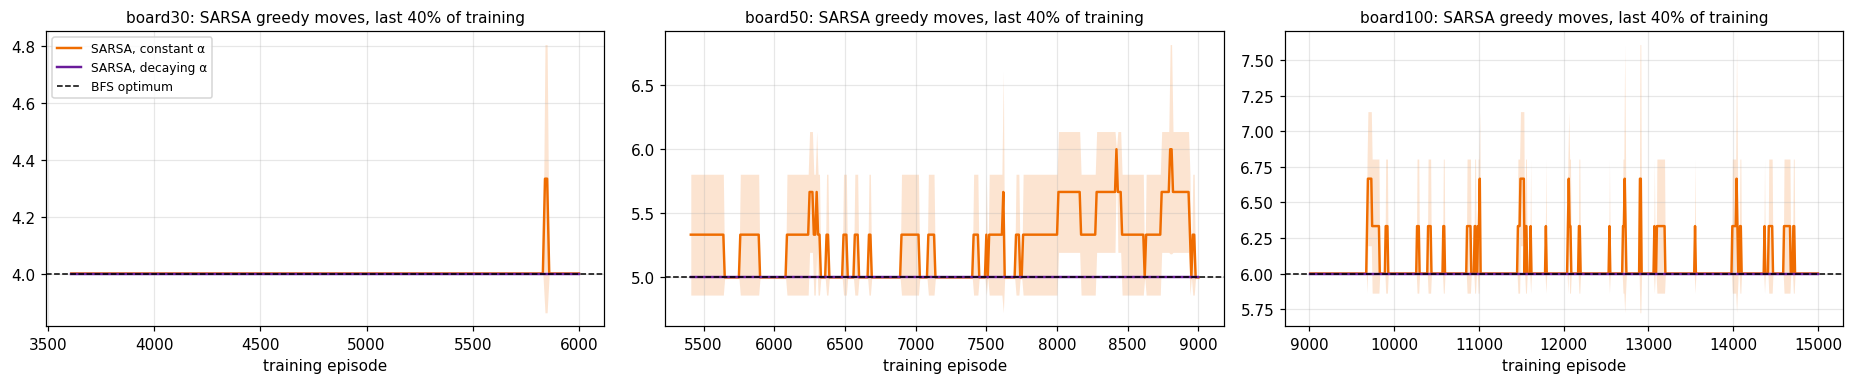

In [22]:
# SARSA greedy moves during training: constant vs decaying alpha (mean of 3 seeds, last 40% of training).
fig, axes = plt.subplots(1, len(boards), figsize=(17, 3.6))
for ax, name in zip(axes, boards):
    for schedule, store, color in (("SARSA, constant α", tabular, ALGO_COLORS["sarsa"]),
                                   ("SARSA, decaying α", tabular_decay, "#6a1b9a")):
        runs = [store[("sarsa", name, s)]["evals"] for s in TAB_SEEDS]
        x = runs[0]["episode"].to_numpy()
        keep = x > 0.6 * x.max()
        band(ax, x[keep], [r["greedy_moves"].to_numpy()[keep] for r in runs], color, schedule)
    ax.axhline(bfs_moves[name], color="k", ls="--", lw=1, label="BFS optimum")
    ax.set_title(f"{name}: SARSA greedy moves, last 40% of training", fontsize=10)
    ax.set_xlabel("training episode")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "sarsa_alpha_decay.png", dpi=150, bbox_inches="tight")
plt.show()

### What the tabular results show

*(Numbers from the runs above, mean over 3 seeds. Everything is seeded, so a rerun reproduces them.)*

**1. Both algorithms learn the optimal game on every board.** On all 3 seeds the final greedy policy plays 4 / 5 / 6 moves, exactly the BFS optimum. Its return is 139 / 138 / 179, exactly the value-iteration optimum. On these boards the shortest game is also the highest-return game, so BFS and $Q^*$ agree on the game from square 1. They don't agree on every square: the sets of optimal dice match on 70% / 100% / 87% of squares, because sometimes an extra ladder is worth an extra move.

**2. Learning is fast, which matters for the research question.** Q-Learning's greedy game is within one move of optimal after about 20 / 73 / 33 episodes and exactly optimal for good after 50 / 437 / 60 episodes. BFS gets the answer instantly, with no training. On a fixed, deterministic board a planner is the simpler tool. RL's advantages need the harder versions of the game (random dice, changing boards).

**3. Q-Learning is stable; SARSA with a constant α is not.** Q-Learning's greedy game is optimal at 100% of the evaluations in the last 20% of training on every board. SARSA's is optimal only 64% of the time on board 50 and 94% on board 100. It keeps switching between the optimal route and routes one move longer (Section 10.8 figure). That is why SARSA's "episodes to optimal" falls almost at the end of training. SARSA's target uses the next action actually taken, which is random 5% of the time, so its Q-values never settle when α is constant. **With α decaying to 0.01, SARSA becomes 100% stable and is optimal after 117 / 497 / 160 episodes** (Section 10.8). This is direct evidence for report questions 5 and 6.

**4. SARSA's policy is better away from the main route.** Across all playable squares, SARSA's greedy dice is return-optimal on 100% / 98.3% / 92.0% of squares, against 91.3% / 88.9% / 87.1% for Q-Learning. Q-Learning's mistakes are on squares off its own greedy route. For example, on square 10 of board 30 it picks 6, while the only optimal choice is 1 (onto the 11→14 ladder). These mistakes don't affect the game from square 1, but they would if the agent started elsewhere (Challenge 3). Why Q-Learning covers these squares less well is not tested here; counting state visits on Day 4 can check it.

**5. "Different" does not mean "worse".** For seed 0 the two policies choose different dice on 4 / 19 / 29 squares, but on 3 / 14 / 22 of those squares **both** choices are optimal. Many squares have several equally good dice values, so two correct agents can legitimately disagree.

**6. Success rate is flat at 100%, as Section 9 predicted.** Even early, exploratory training finishes every game inside the 4N limit. The training moves curve stays slightly above the optimum (4.2 / 5.3–5.6 / 6.4 moves) because of the 5% random exploration that continues to the end. The greedy (dotted) curve shows the policy itself is optimal.

### Day 2 checkpoint

- [x] ε-greedy with random tie-breaking and an exponential schedule
- [x] Q-Learning and SARSA from scratch, sharing one training loop
- [x] 18 runs (2 algorithms × 3 boards × 3 seeds) evaluated on separate greedy games, with logs and Q-tables saved under `results/tabular/`
- [x] Graded against both BFS (fewest moves) and value iteration (highest return)
- [x] Required plots: reward, moves and success rate vs episodes, Q-Learning vs SARSA
- [x] Follow-up: a decaying α fixes SARSA's instability

**Next (Day 3):** DQN, PPO and A2C with stable-baselines3 on the same boards, observations one-hot encoded.

## 11. Deep RL: DQN, PPO and A2C (stable-baselines3)

Tabular methods store one number per (square, dice) pair. Deep RL replaces the table with a **neural network** that maps the observation to values or action probabilities. Here the observation is the one-hot square vector (Section 6). All three agents use the same network size: two hidden layers of 128 units.

### Why these three algorithms

The three algorithms cover the three main families of deep RL. Comparing families says more than comparing three variants of one idea. All three support the `Discrete(6)` action space this game needs.

| | DQN | PPO | A2C |
|---|---|---|---|
| Family | Value-based | Policy gradient (clipped) | Actor-critic |
| On / off-policy | Off-policy | On-policy | On-policy |
| What the network learns | $Q(s,a)$ for all 6 dice values | A policy $\pi(a\mid s)$ and a value $V(s)$ | A policy $\pi(a\mid s)$ and a value $V(s)$ |
| Exploration | ε-greedy (like the tabular agents) | Sampling from $\pi$, plus an entropy bonus | Sampling from $\pi$, plus an entropy bonus |
| Reuses past experience | Yes: a replay buffer | A few passes over each batch, then discards it | No |
| Link to Section 10 | The deep version of Q-Learning | Like SARSA, learns from its own actions | Like SARSA, learns from its own actions |

**DQN (Deep Q-Network).** Q-Learning with a neural network instead of a table. Two ideas make it stable. A **replay buffer** stores past moves and trains on random batches of them, which breaks the correlation between consecutive moves. A **target network**, a copy of the network updated only every 1,000 steps, provides fixed targets so the network is not chasing its own changing output. *Chosen because* it is the direct deep counterpart of Q-Learning, which makes the tabular-vs-deep comparison clean.

**PPO (Proximal Policy Optimization).** Learns the policy directly and improves it by gradient ascent on expected return, using an *advantage* estimate: how much better an action was than expected. Its key idea is a **clipped objective** that stops any single update from changing the policy too much, which makes training stable. *Chosen because* it is the most widely used general-purpose deep-RL algorithm and represents the policy-gradient family.

**A2C (Advantage Actor-Critic).** An **actor** (the policy) chooses actions and a **critic** (the value function) judges them. The actor is pushed toward actions with positive advantage $A = r + \gamma V(s') - V(s)$. It runs several environments in parallel and updates synchronously after a few steps. *Chosen because* it is the simpler, unclipped actor-critic, so comparing it with PPO shows what PPO's clipping and batch reuse add.

### 11.1 Hyperparameters and budgets

| | DQN | PPO | A2C |
|---|---|---|---|
| Parallel environments | 1 | 4 | 4 |
| Learning rate | 5e-4 | 3e-4 | 7e-4 |
| Batch / rollout | replay buffer 50,000; batch 64; train every 4 steps | 256 steps × 4 envs per update; minibatch 64; 10 epochs | 8 steps × 4 envs per update |
| Exploration | ε: 1.0 → 0.05 over the first 30% of training | entropy coefficient 0.01 | entropy coefficient 0.01 |
| Other | learning starts after 1,000 steps; target network updated every 1,000 steps | GAE λ = 0.95, clip 0.2 | standard RMSprop settings |

All use γ = 0.99, as the tabular agents do. Training budgets in **environment steps** are 40,000 / 60,000 / 100,000 for boards 30 / 50 / 100, each with **3 seeds**. That is many times more interaction than Q-Learning needed to reach the optimum (a few hundred to a few thousand steps, Section 12), so the comparison is generous to the deep agents.

**Runtime:** about 35–45 minutes for all 27 runs on a Colab CPU runtime (a GPU does not help networks this small). Every run is saved as soon as it finishes, so after a disconnect a rerun skips the finished runs. To get a quick result first, reduce `DRL_SEEDS` to `[0]`.

In [23]:
import torch
from stable_baselines3 import A2C, DQN, PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env

torch.set_num_threads(1)          # small MLPs run faster single-threaded

DRL_ALGOS = {"dqn": "DQN", "ppo": "PPO", "a2c": "A2C"}
DRL_CLASSES = {"dqn": DQN, "ppo": PPO, "a2c": A2C}
DRL_STEPS = {"board30": 40_000, "board50": 60_000, "board100": 100_000}
DRL_SEEDS = [0, 1, 2]
DRL_DIR = RESULTS_DIR / "drl"
DRL_DIR.mkdir(parents=True, exist_ok=True)

NET = dict(net_arch=[128, 128])
DRL_CONFIG = {
    "dqn": dict(n_envs=1, kwargs=dict(learning_rate=5e-4, buffer_size=50_000, learning_starts=1_000,
                                      batch_size=64, train_freq=4, gradient_steps=1,
                                      target_update_interval=1_000, exploration_fraction=0.3,
                                      exploration_initial_eps=1.0, exploration_final_eps=0.05,
                                      gamma=GAMMA, policy_kwargs=NET)),
    "ppo": dict(n_envs=4, kwargs=dict(learning_rate=3e-4, n_steps=256, batch_size=64, n_epochs=10,
                                      gae_lambda=0.95, clip_range=0.2, ent_coef=0.01,
                                      gamma=GAMMA, policy_kwargs=NET)),
    "a2c": dict(n_envs=4, kwargs=dict(learning_rate=7e-4, n_steps=8, ent_coef=0.01,
                                      gamma=GAMMA, policy_kwargs=NET)),
}

### 11.2 Evaluating a network the same way as a Q-table

**What this does:** a stable-baselines3 *callback* is code that SB3 runs after every environment step during training. This one does two jobs:

1. **Logs every finished training episode** (return, moves, success), using the episode summary that SB3's `Monitor` wrapper attaches when an episode ends.
2. **Evaluates the greedy policy** about 100 times per run, on a separate environment with `deterministic=True` (no exploration). It records exactly the Section 10.2 metrics: greedy moves, success, return, and optimal-action % against both Q\* and BFS. For optimal-action %, the network is asked for its choice on every playable square at once.

**Why:** with identical metrics on an identical evaluation protocol, the five agents can be compared directly. The x-axis is **environment steps**, the one quantity all five agents share.

In [24]:
class GreedyEvalCallback(BaseCallback):
    def __init__(self, board: Board, eval_freq: int):
        super().__init__(verbose=0)
        self.board, self.eval_freq = board, eval_freq
        self.rows = np.array(playable_squares(board)) - 1
        self.square_obs = np.eye(board.n, dtype=np.float32)[self.rows]   # one-hot of every playable square
        self.episodes, self.evals, self.next_eval = [], [], eval_freq

    def _evaluate(self):
        policy = lambda obs, env: int(self.model.predict(obs, deterministic=True)[0])
        game = run_episode(SmartDiceEnv(self.board, obs_mode="onehot"), policy)
        actions = np.asarray(self.model.predict(self.square_obs, deterministic=True)[0]).astype(int)
        m = masks[self.board.name]
        self.evals.append({"env_steps": self.num_timesteps, "episode": len(self.episodes),
                           "greedy_moves": game["moves"], "greedy_success": game["success"],
                           "greedy_return": game["return"],
                           "optimal_action_pct": 100 * m["qstar"][self.rows, actions].mean(),
                           "bfs_action_pct": 100 * m["bfs"][self.rows, actions].mean()})

    def _on_training_start(self):
        self._evaluate()

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if "episode" in info:                              # added by Monitor when an episode ends
                self.episodes.append({"episode": len(self.episodes) + 1, "env_steps": self.num_timesteps,
                                      "return": float(info["episode"]["r"]),
                                      "moves": int(info["episode"]["l"]),
                                      "success": info.get("event") == "goal"})
        if self.num_timesteps >= self.next_eval:
            self._evaluate()
            self.next_eval += self.eval_freq
        return True

    def _on_training_end(self):
        if not self.evals or self.evals[-1]["env_steps"] != self.num_timesteps:
            self._evaluate()


def train_drl(algo: str, board: Board, steps: int, seed: int):
    cfg = DRL_CONFIG[algo]
    venv = make_vec_env(lambda b=board: SmartDiceEnv(b, obs_mode="onehot"), n_envs=cfg["n_envs"], seed=seed)
    model = DRL_CLASSES[algo]("MlpPolicy", venv, seed=seed, device="cpu", verbose=0, **cfg["kwargs"])
    callback = GreedyEvalCallback(board, eval_freq=max(steps // 100, 100))
    t0 = time.perf_counter()
    model.learn(total_timesteps=steps, callback=callback)
    seconds = time.perf_counter() - t0
    venv.close()
    return model, pd.DataFrame(callback.episodes), pd.DataFrame(callback.evals), seconds

### 11.3 Training all deep-RL runs

**What this does:** trains 3 algorithms × 3 boards × 3 seeds. Each run saves its model (`.zip`), episode log and evaluation log under `results/drl/`, and prints its time and final greedy result. If the session disconnects, run the notebook again: finished runs are loaded and only the missing ones are trained.

In [25]:
def drl_paths(algo, name, seed, root=DRL_DIR):
    stem = root / f"{algo}_{name}_seed{seed}"
    return stem.with_suffix(".zip"), Path(f"{stem}_episodes.csv"), Path(f"{stem}_evals.csv")


def run_or_load_drl(algo, board, steps, seed, root=DRL_DIR):
    zip_path, ep_path, ev_path = drl_paths(algo, board.name, seed, root)
    if FORCE_RETRAIN or not (zip_path.exists() and ev_path.exists()):
        model, episodes, evals, seconds = train_drl(algo, board, steps, seed)
        model.save(zip_path)
        episodes.assign(seconds=seconds).to_csv(ep_path, index=False)
        evals.to_csv(ev_path, index=False)
        status = f"trained in {seconds:5.0f} s"
    else:
        episodes, evals = pd.read_csv(ep_path), pd.read_csv(ev_path)
        seconds = float(episodes["seconds"].iloc[0]) if len(episodes) else np.nan
        status = "loaded"
    return {"model_path": zip_path, "log": episodes, "evals": evals, "seconds": seconds, "status": status}


drl = {}   # (algo, board, seed) -> dict(model_path, log, evals, seconds)
for name, b in boards.items():
    for algo, label in DRL_ALGOS.items():
        for seed in DRL_SEEDS:
            run = run_or_load_drl(algo, b, DRL_STEPS[name], seed)
            drl[(algo, name, seed)] = run
            last = run["evals"].iloc[-1]
            print(f"{name:>8} | {label:<3} | seed {seed} | {run['status']} | final greedy game: "
                  f"{int(last['greedy_moves'])} moves (BFS {bfs_moves[name]}), "
                  f"optimal-action {last['optimal_action_pct']:.0f}%")

 board30 | DQN | seed 0 | loaded | final greedy game: 4 moves (BFS 4), optimal-action 100%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 board30 | DQN | seed 1 | loaded | final greedy game: 4 moves (BFS 4), optimal-action 100%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 board30 | DQN | seed 2 | loaded | final greedy game: 4 moves (BFS 4), optimal-action 100%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (44 outputs left out)

board100 | A2C | seed 1 | loaded | final greedy game: 7 moves (BFS 6), optimal-action 61%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


board100 | A2C | seed 2 | loaded | final greedy game: 7 moves (BFS 6), optimal-action 58%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 11.4 Deep-RL results

Same metrics as Section 10.5, with convergence measured in **environment steps** (the first evaluation from which the greedy game stays optimal to the end of training).

In [26]:
def summarize_runs(runs, name, x="env_steps"):
    final = [r["evals"].iloc[-1] for r in runs]
    return {
        "greedy moves": mean_std([f["greedy_moves"] for f in final]),
        "gap to BFS": mean_std([f["greedy_moves"] - bfs_moves[name] for f in final]),
        "optimal seeds": f"{sum(bool(f['greedy_success']) and f['greedy_moves'] == bfs_moves[name] for f in final)}/{len(final)}",
        "optimal-action % (Q*)": mean_std([f["optimal_action_pct"] for f in final]),
        "greedy return": mean_std([f["greedy_return"] for f in final]),
        "steps to optimal": mean_std([convergence_episode(r["evals"], bfs_moves[name], 0, x=x) for r in runs], "{:.0f}"),
        "steps to near-optimal": mean_std([convergence_episode(r["evals"], bfs_moves[name], 1, x=x) for r in runs], "{:.0f}"),
        "late stability %": mean_std([late_stability(r["evals"], bfs_moves[name], x=x) for r in runs]),
        "train time (s)": mean_std([r["seconds"] for r in runs]),
    }


drl_summary = pd.DataFrame([
    {"board": name, "algorithm": label, "BFS optimum": bfs_moves[name],
     **summarize_runs([drl[(algo, name, s)] for s in DRL_SEEDS], name)}
    for name in boards for algo, label in DRL_ALGOS.items()])
drl_summary.to_csv(RESULTS_DIR / "drl_summary.csv", index=False)
drl_summary

,board,algorithm,BFS optimum,greedy moves,gap to BFS,optimal seeds,optimal-action % (Q*),greedy return,steps to optimal,steps to near-optimal,late stability %,train time (s)
0,board30,DQN,4,4.0 ± 0.0,0.0 ± 0.0,3/3,100.0 ± 0.0,139.0 ± 0.0,17867 ± 680,17600 ± 566,100.0 ± 0.0,40.3 ± 0.2
1,board30,PPO,4,4.0 ± 0.0,0.0 ± 0.0,3/3,95.7 ± 6.1,139.0 ± 0.0,22667 ± 11111,11467 ± 10853,100.0 ± 0.0,34.9 ± 0.4
2,board30,A2C,4,4.0 ± 0.0,0.0 ± 0.0,3/3,73.9 ± 6.1,139.0 ± 0.0,6533 ± 1969,3067 ± 2620,100.0 ± 0.0,14.9 ± 0.0
3,board50,DQN,5,5.0 ± 0.0,0.0 ± 0.0,3/3,99.1 ± 1.2,138.0 ± 0.0,22600 ± 1980,22200 ± 2245,100.0 ± 0.0,57.9 ± 0.7
4,board50,PPO,5,5.0 ± 0.0,0.0 ± 0.0,3/3,87.2 ± 3.6,138.0 ± 0.0,13000 ± 1575,5400 ± 3059,100.0 ± 0.0,49.6 ± 1.0
5,board50,A2C,5,5.0 ± 0.0,0.0 ± 0.0,3/3,82.9 ± 5.3,138.0 ± 0.0,9600 ± 4271,4400 ± 2698,100.0 ± 0.0,21.6 ± 0.6
6,board100,DQN,6,6.0 ± 0.0,0.0 ± 0.0,3/3,92.8 ± 2.6,179.0 ± 0.0,29333 ± 5558,28333 ± 6182,100.0 ± 0.0,102.6 ± 3.9
7,board100,PPO,6,6.3 ± 0.5,0.3 ± 0.5,2/3,78.7 ± 7.3,178.7 ± 0.5,26000 ± 9000 (1 seed(s) not reached),9333 ± 3399,98.4 ± 2.2,84.1 ± 0.1
8,board100,A2C,6,7.3 ± 0.5,1.3 ± 0.5,0/3,58.6 ± 2.0,177.7 ± 0.5,not reached,11000 ± 1000 (1 seed(s) not reached),0.0 ± 0.0,37.1 ± 0.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12. All five agents compared

**What this does:** puts Q-Learning, SARSA, DQN, PPO and A2C side by side on every board, using the same metrics and the same evaluation protocol. The common unit is the **environment step** (one dice choice), because tabular agents count episodes and SB3 counts steps.

Tabular agents use the constant α = 0.1 from Section 10.4. Section 10.8 covers the decaying-α variant.

In [27]:
AGENTS = {**{a: ALGOS[a] for a in ALGOS}, **DRL_ALGOS}
AGENT_COLORS = {"qlearning": "#1565c0", "sarsa": "#ef6c00", "dqn": "#2e7d32", "ppo": "#6a1b9a", "a2c": "#c62828"}


def agent_runs(agent, name):
    store = tabular if agent in ALGOS else drl
    seeds = TAB_SEEDS if agent in ALGOS else DRL_SEEDS
    return [store[(agent, name, s)] for s in seeds]


comparison = pd.DataFrame([
    {"board": name, "agent": label, "family": "tabular" if agent in ALGOS else "deep RL",
     "BFS optimum": bfs_moves[name], **summarize_runs(agent_runs(agent, name), name)}
    for name in boards for agent, label in AGENTS.items()])
comparison.to_csv(RESULTS_DIR / "comparison_all_agents.csv", index=False)
comparison

,board,agent,family,BFS optimum,greedy moves,gap to BFS,optimal seeds,optimal-action % (Q*),greedy return,steps to optimal,steps to near-optimal,late stability %,train time (s)
0,board30,Q-Learning,tabular,4,4.0 ± 0.0,0.0 ± 0.0,3/3,91.3 ± 3.5,139.0 ± 0.0,627 ± 270,268 ± 170,100.0 ± 0.0,1.2 ± 0.0
1,board30,SARSA,tabular,4,4.0 ± 0.0,0.0 ± 0.0,3/3,100.0 ± 0.0,139.0 ± 0.0,10439 ± 13600,186 ± 54,99.5 ± 0.6,1.1 ± 0.0
2,board30,DQN,deep RL,4,4.0 ± 0.0,0.0 ± 0.0,3/3,100.0 ± 0.0,139.0 ± 0.0,17867 ± 680,17600 ± 566,100.0 ± 0.0,40.3 ± 0.2
3,board30,PPO,deep RL,4,4.0 ± 0.0,0.0 ± 0.0,3/3,95.7 ± 6.1,139.0 ± 0.0,22667 ± 11111,11467 ± 10853,100.0 ± 0.0,34.9 ± 0.4
4,board30,A2C,deep RL,4,4.0 ± 0.0,0.0 ± 0.0,3/3,73.9 ± 6.1,139.0 ± 0.0,6533 ± 1969,3067 ± 2620,100.0 ± 0.0,14.9 ± 0.0
5,board50,Q-Learning,tabular,5,5.0 ± 0.0,0.0 ± 0.0,3/3,88.9 ± 3.2,138.0 ± 0.0,6960 ± 4274,1430 ± 896,100.0 ± 0.0,2.6 ± 0.4
6,board50,SARSA,tabular,5,5.0 ± 0.0,0.0 ± 0.0,3/3,98.3 ± 1.2,138.0 ± 0.0,62257 ± 1130,40584 ± 24806,68.3 ± 15.5,2.0 ± 0.0
7,board50,DQN,deep RL,5,5.0 ± 0.0,0.0 ± 0.0,3/3,99.1 ± 1.2,138.0 ± 0.0,22600 ± 1980,22200 ± 2245,100.0 ± 0.0,57.9 ± 0.7
8,board50,PPO,deep RL,5,5.0 ± 0.0,0.0 ± 0.0,3/3,87.2 ± 3.6,138.0 ± 0.0,13000 ± 1575,5400 ± 3059,100.0 ± 0.0,49.6 ± 1.0
9,board50,A2C,deep RL,5,5.0 ± 0.0,0.0 ± 0.0,3/3,82.9 ± 5.3,138.0 ± 0.0,9600 ± 4271,4400 ± 2698,100.0 ± 0.0,21.6 ± 0.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 12.1 Learning curves against environment steps

One row per board; mean over seeds with ± 1 std bands. Each agent's curve ends where its training budget ends.

1. **Greedy moves** of the policy being learned (BFS optimum dashed). Lower is better.
2. **Optimal-action % (Q\*)** across all playable squares: the quality of the whole policy.
3. **Training return** (rolling 50 episodes), which includes each agent's exploration.
4. **Training success rate** (rolling 100 episodes).

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


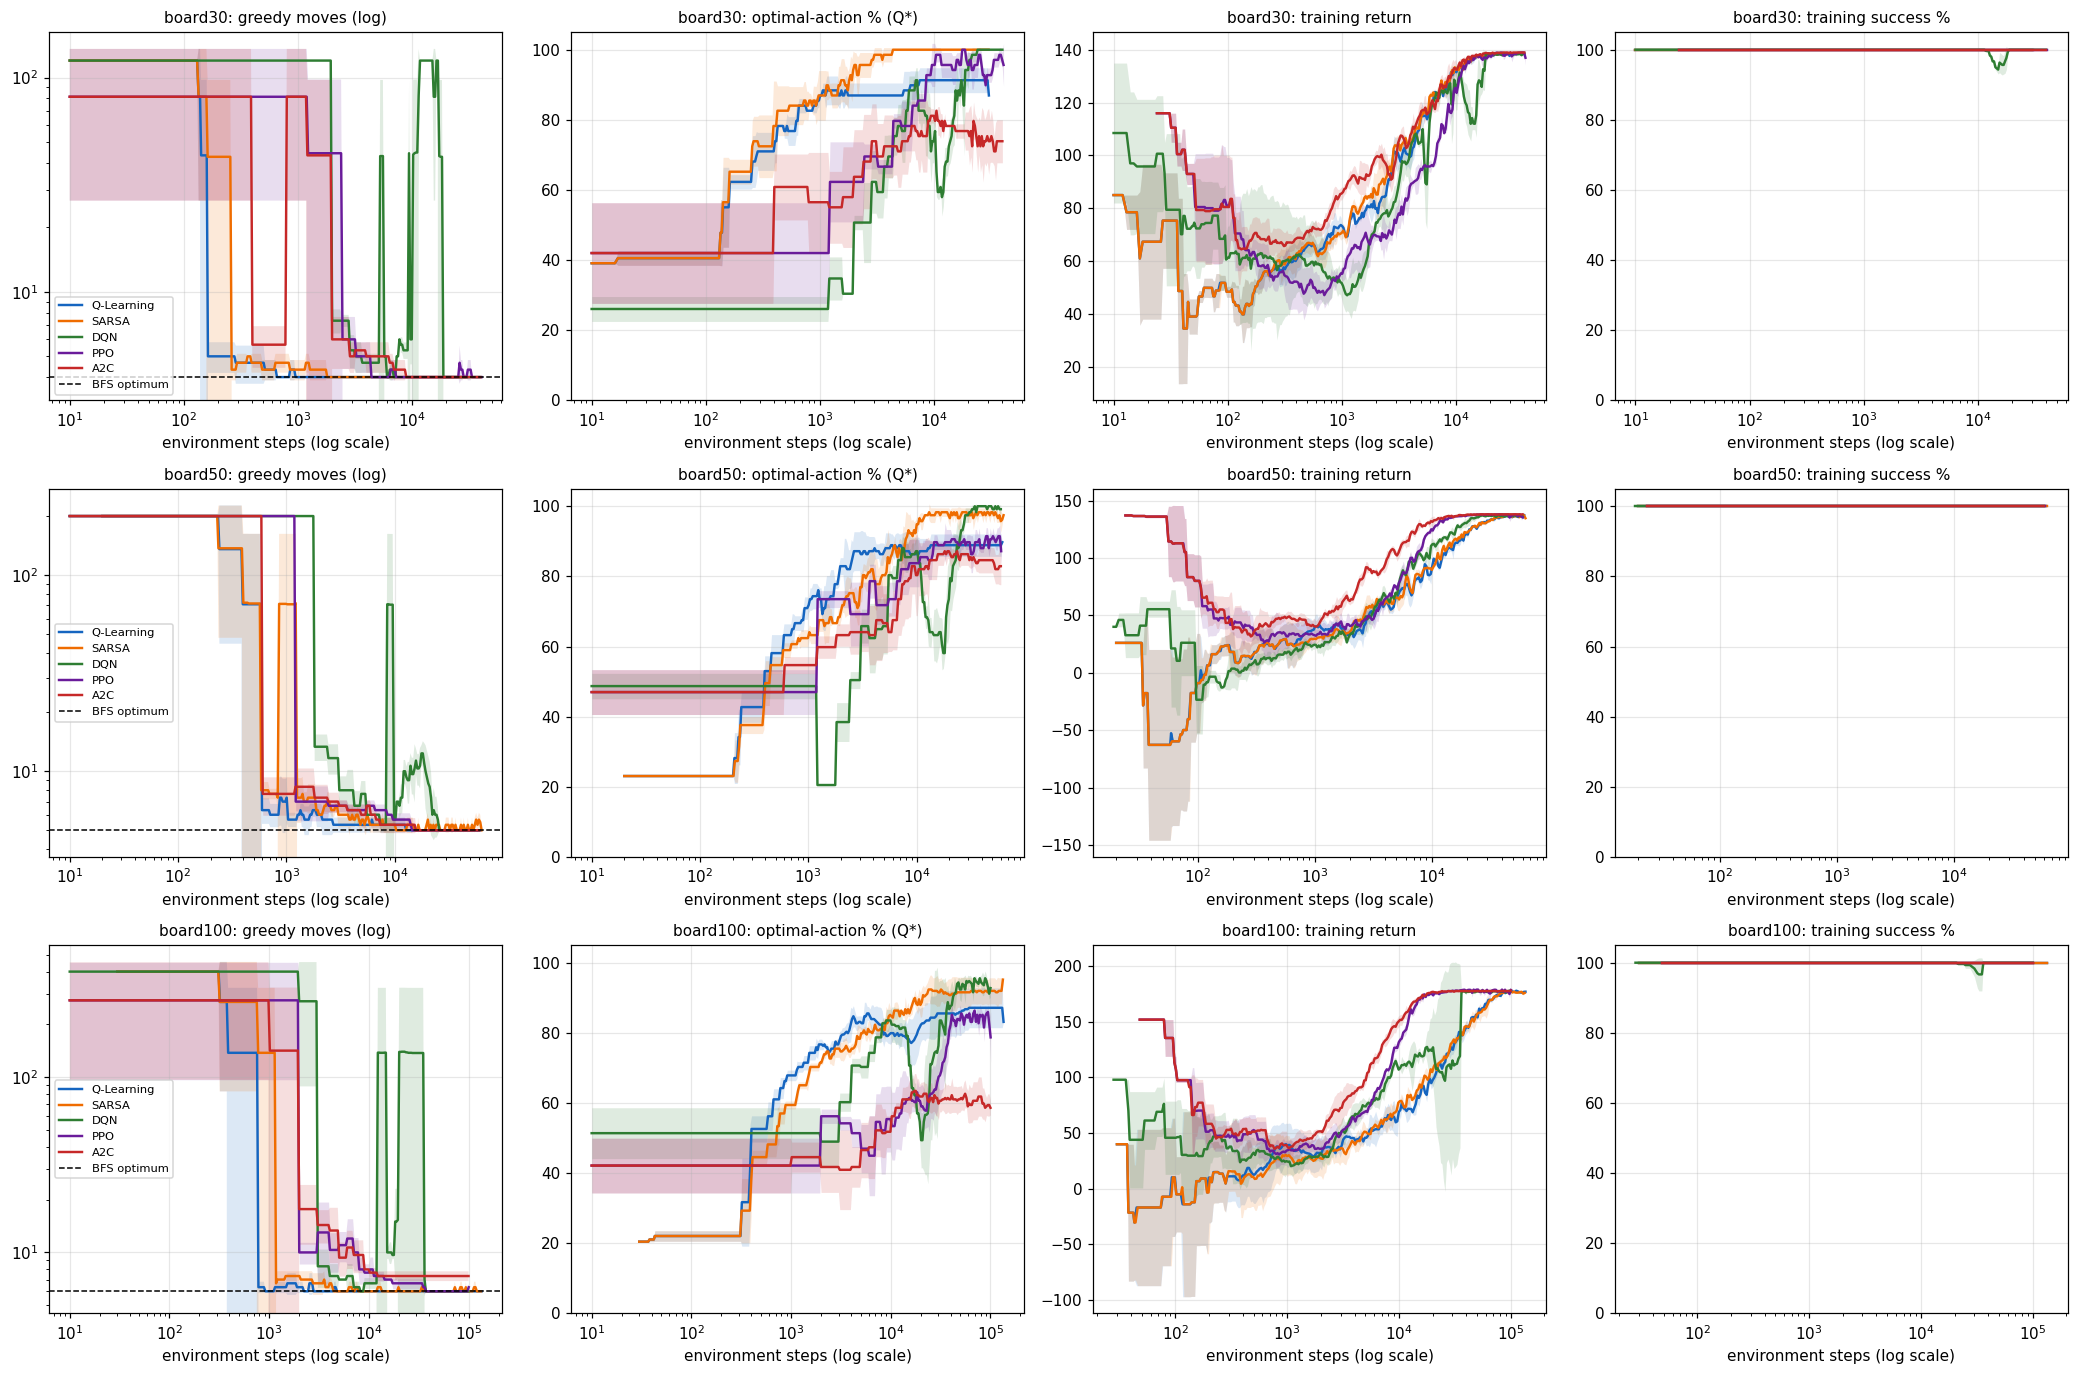

In [28]:
def step_interp(x, y, grid):
    # Value of a step function (last value at or before each grid point); NaN before the first point.
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    idx = np.searchsorted(x, grid, side="right") - 1
    out = np.where(idx >= 0, y[np.clip(idx, 0, len(y) - 1)], np.nan)
    return np.where(grid <= x[-1], out, np.nan)


def band_steps(ax, runs, xcol, ycol, color, label, frame="evals", rolling=None, scale=1.0):
    xmax = max(r[frame][xcol].max() for r in runs)
    grid = np.unique(np.geomspace(10, xmax, 300).round())
    curves = []
    for r in runs:
        df = r[frame]
        y = df[ycol].astype(float) * scale
        if rolling:
            y = y.rolling(rolling, min_periods=1).mean()
        curves.append(step_interp(df[xcol], y, grid))
    arr = np.vstack(curves)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean, std = np.nanmean(arr, axis=0), np.nanstd(arr, axis=0)
    ax.plot(grid, mean, color=color, lw=1.6, label=label)
    ax.fill_between(grid, mean - std, mean + std, color=color, alpha=0.15, lw=0)


fig, axes = plt.subplots(len(boards), 4, figsize=(19, 4.2 * len(boards)))
for row, name in enumerate(boards):
    for agent, label in AGENTS.items():
        runs, c = agent_runs(agent, name), AGENT_COLORS[agent]
        band_steps(axes[row, 0], runs, "env_steps", "greedy_moves", c, label)
        band_steps(axes[row, 1], runs, "env_steps", "optimal_action_pct", c, label)
        band_steps(axes[row, 2], runs, "env_steps", "return", c, label, frame="log", rolling=50)
        band_steps(axes[row, 3], runs, "env_steps", "success", c, label, frame="log", rolling=100, scale=100)
    axes[row, 0].axhline(bfs_moves[name], color="k", ls="--", lw=1, label="BFS optimum")
    axes[row, 0].set_yscale("log")
    axes[row, 1].set_ylim(0, 105)
    axes[row, 3].set_ylim(0, 105)
    for ax, t in zip(axes[row], ["greedy moves (log)", "optimal-action % (Q*)", "training return", "training success %"]):
        ax.set_xscale("log")
        ax.set_xlabel("environment steps (log scale)")
        ax.set_title(f"{name}: {t}", fontsize=10)
        ax.grid(alpha=0.3)
    axes[row, 0].legend(fontsize=7.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "all_agents_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [29]:
# Auto-generated reading of the comparison, so the text always matches the numbers of this run.
from IPython.display import Markdown, display


def final_metric(agent, name, col):
    return np.mean([r["evals"].iloc[-1][col] for r in agent_runs(agent, name)])


def steps_to_opt(agent, name):
    v = [convergence_episode(r["evals"], bfs_moves[name], 0, x="env_steps") for r in agent_runs(agent, name)]
    return np.nan if np.isnan(v).any() else float(np.mean(v))


lines = ["**What the comparison shows (numbers from this run):**", ""]
for name in boards:
    solved = [AGENTS[a] for a in AGENTS
              if all(bool(r["evals"].iloc[-1]["greedy_success"]) and r["evals"].iloc[-1]["greedy_moves"] == bfs_moves[name]
                     for r in agent_runs(a, name))]
    fastest = {a: steps_to_opt(a, name) for a in AGENTS}
    ranked = sorted([(v, AGENTS[a]) for a, v in fastest.items() if not np.isnan(v)])
    best_policy = max(AGENTS, key=lambda a: final_metric(a, name, "optimal_action_pct"))
    text = (f"- **{name}** (BFS optimum {bfs_moves[name]} moves): optimal on every seed: "
            f"{', '.join(solved) if solved else 'none'}. ")
    if ranked:
        text += "Mean environment steps until the greedy game stays optimal: " + ", ".join(
            f"{lab} {v:,.0f}" for v, lab in ranked) + ". "
    text += (f"Best whole-policy quality: {AGENTS[best_policy]} "
             f"({final_metric(best_policy, name, 'optimal_action_pct'):.1f}% of squares Q*-optimal).")
    lines.append(text)
display(Markdown("\n".join(lines)))

**What the comparison shows (numbers from this run):**

- **board30** (BFS optimum 4 moves): optimal on every seed: Q-Learning, SARSA, DQN, PPO, A2C. Mean environment steps until the greedy game stays optimal: Q-Learning 627, A2C 6,533, SARSA 10,439, DQN 17,867, PPO 22,667. Best whole-policy quality: SARSA (100.0% of squares Q*-optimal).
- **board50** (BFS optimum 5 moves): optimal on every seed: Q-Learning, SARSA, DQN, PPO, A2C. Mean environment steps until the greedy game stays optimal: Q-Learning 6,960, A2C 9,600, PPO 13,000, DQN 22,600, SARSA 62,257. Best whole-policy quality: DQN (99.1% of squares Q*-optimal).
- **board100** (BFS optimum 6 moves): optimal on every seed: Q-Learning, SARSA, DQN. Mean environment steps until the greedy game stays optimal: Q-Learning 1,962, DQN 29,333, SARSA 128,109. Best whole-policy quality: DQN (92.8% of squares Q*-optimal).

### 12.2 What the comparison shows (submitted run)

*Numbers from the submitted run (Colab CPU, seeds 0–2). Tabular results are bit-for-bit reproducible. Deep-RL results on another machine can differ slightly, because PyTorch is not guaranteed to be bit-identical across hardware; the auto-generated summary above always reflects the run on screen.*

**1. Reaching the optimum.** On boards 30 and 50, all five agents reach the BFS optimum on every seed. On board 100, Q-Learning, SARSA and DQN still do (3/3 seeds), PPO does on 2 of 3 seeds, and **A2C on none**: it settles on a 7-move route (7.3 moves on average). Over all three boards, DQN is optimal on 9/9 seeds, PPO on 8/9 and A2C on 6/9.

**2. Sample efficiency: the table wins on a small board.** Q-Learning's greedy game stays optimal after about **630 / 6,960 / 1,960 environment steps** on boards 30 / 50 / 100, while DQN needs **17,900 / 22,600 / 29,300**. DQN's convergence follows its exploration schedule: ε reaches its floor at 30% of the budget (12,000 / 18,000 / 30,000 steps), and DQN converges only just after that. DQN's greedy-moves curve also shows temporary relapses around 10⁴ steps, where the greedy game suddenly takes 100+ moves before recovering. That's the instability of training a network on its own changing targets, which the target network and replay buffer reduce but don't remove.

**3. Policy quality away from the route: DQN is best.** At the end of training, DQN chooses a Q\*-optimal dice on **100% / 99.1% / 92.8%** of squares, more than tabular Q-Learning (91.3% / 88.9% / 87.1%) and SARSA (100% / 98.3% / 92.0%). A plausible reason (not tested separately) is that the replay buffer keeps re-training on transitions from squares the current policy no longer visits.

**4. The on-policy deep agents learn the route fast but neglect the rest.** PPO and A2C get within one move of optimal quickest among the deep agents (A2C after about 3,100 / 4,400 steps on boards 30 / 50). But their whole-policy quality stays below DQN's on every board (PPO: 95.7% / 87.2% / 78.7%), and A2C's is the lowest of all five agents (73.9% / 82.9% / 58.6%). On-policy methods learn mostly about the squares their own current policy visits, and A2C's small, single-pass updates did not escape a near-optimal route on board 100 within its budget.

**5. Stability.** Every deep agent's greedy game stays optimal through the last 20% of training on boards 30 and 50 (100% late stability), as do Q-Learning's. The exceptions are tabular SARSA with a constant α (Section 10.8) and, on board 100, PPO (98.4%) and A2C (0%, never optimal).

**Bottom line:** on this small, deterministic game, tabular Q-Learning is the most sample-efficient learner and DQN ends with the best whole policy. A2C is the weakest of the five.

## 13. Advanced challenges

Three challenges were chosen because each one adds new evidence for a report question:

| Challenge | Question it answers |
|---|---|
| **6: Reward optimization** | Q3: how the reward design shapes behaviour, including how it can go wrong |
| **1: Random dice** | The research question: what happens when BFS no longer applies |
| **5: DQN vs tabular on a larger board** | Q9: how the methods scale with board size |

### 13.1 Challenge 6: reward optimization

**Design.** Five reward schemes, each a full reward table:

| Scheme | Goal | Ladder | Normal | Snake | Invalid | Idea |
|---|---|---|---|---|---|---|
| brief | +100 | +20 | −1 | −20 | −10 | the project's default |
| sparse | +100 | −1 | −1 | −1 | −1 | only reaching the goal matters; every move costs 1 |
| no step cost | +100 | +20 | 0 | −20 | −10 | remove the time pressure |
| goal only | +100 | 0 | 0 | 0 | 0 | the purest sparse reward |
| big ladder | +100 | **+60** | −1 | −20 | −10 | an over-generous shaping bonus |

**Two questions:**
1. **What is the optimal behaviour under each scheme?** Answered exactly with value iteration, which shows what any good RL agent will converge to.
2. **Does the scheme change how fast Q-Learning learns the shortest game?** Answered by training Q-Learning (3 seeds) under each scheme and measuring progress with a reward-independent yardstick: greedy moves compared with BFS. Same episode budgets as Section 10, evaluated every 25 episodes. (The looping scheme takes about 3 minutes, because its games always run the full 4N moves. Like every run, it's saved, so it only runs once.)

In [30]:
REWARD_SCHEMES = {
    "brief":        REWARDS,
    "sparse":       {"goal": 100.0, "ladder": -1.0, "normal": -1.0, "snake": -1.0, "invalid": -1.0},
    "no step cost": {"goal": 100.0, "ladder": 20.0, "normal": 0.0, "snake": -20.0, "invalid": -10.0},
    "goal only":    {"goal": 100.0, "ladder": 0.0, "normal": 0.0, "snake": 0.0, "invalid": 0.0},
    "big ladder":   {"goal": 100.0, "ladder": 60.0, "normal": -1.0, "snake": -20.0, "invalid": -10.0},
}

# Question 1: the exact optimal behaviour under each scheme.
rows = []
for name, b in boards.items():
    for scheme, R in REWARD_SCHEMES.items():
        Qs = value_iteration(b, rewards=R)
        game = run_episode(SmartDiceEnv(b, rewards=R), greedy_policy_from_q(Qs))
        rows.append({"board": name, "scheme": scheme, "optimal policy finishes?": game["success"],
                     "moves": game["moves"], "ladders": game["ladders"], "snakes": game["snakes"],
                     "first squares visited": " -> ".join(map(str, game["path"][:9])) + (" ..." if len(game["path"]) > 9 else "")})
reward_optimal = pd.DataFrame(rows)
reward_optimal.to_csv(RESULTS_DIR / "challenge6_optimal_behaviour.csv", index=False)
reward_optimal

,board,scheme,optimal policy finishes?,moves,ladders,snakes,first squares visited
0,board30,brief,True,4,2,0,1 -> 3 -> 16 -> 25 -> 30
1,board30,sparse,True,4,2,0,1 -> 3 -> 16 -> 25 -> 30
2,board30,no step cost,True,4,2,0,1 -> 3 -> 16 -> 25 -> 30
3,board30,goal only,True,4,2,0,1 -> 3 -> 16 -> 25 -> 30
4,board30,big ladder,False,120,60,59,1 -> 3 -> 16 -> 25 -> 19 -> 25 -> 19 -> 25 -> ...
5,board50,brief,True,5,2,0,1 -> 16 -> 22 -> 28 -> 47 -> 50
6,board50,sparse,True,5,2,0,1 -> 16 -> 22 -> 28 -> 47 -> 50
7,board50,no step cost,True,5,2,0,1 -> 16 -> 22 -> 28 -> 47 -> 50
8,board50,goal only,True,5,2,0,1 -> 16 -> 22 -> 28 -> 47 -> 50
9,board50,big ladder,True,5,2,0,1 -> 16 -> 22 -> 28 -> 47 -> 50


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Where does a ladder bonus become harmful?** The cell below increases the ladder reward from +20 in steps of 1 and finds, for each board, the smallest value at which the optimal policy prefers a **ladder → snake → ladder loop** to finishing. Climbing the ladder pays the bonus now, the snake's −20 comes a move later and is discounted by γ, and the loop can repeat. Above that threshold the "optimal" agent never reaches the goal.

In [31]:
def loop_threshold(board, max_bonus=200):
    for bonus in range(20, max_bonus + 1):
        R = {**REWARDS, "ladder": float(bonus)}
        game = run_episode(SmartDiceEnv(board, rewards=R), greedy_policy_from_q(value_iteration(board, rewards=R)))
        if not game["success"]:
            loop = game["path"][-6:]
            return bonus, loop
    return None, None


for name, b in boards.items():
    bonus, loop = loop_threshold(b)
    if bonus is None:
        print(f"{name}: no ladder-snake loop up to a +200 ladder reward (no ladder and snake close enough to cycle)")
    else:
        print(f"{name}: the optimal policy starts looping at a ladder reward of +{bonus} "
              f"(the brief uses +20); last squares of the game: {loop}")

board30: the optimal policy starts looping at a ladder reward of +23 (the brief uses +20); last squares of the game: [25, 19, 25, 19, 25, 19]
board50: no ladder-snake loop up to a +200 ladder reward (no ladder and snake close enough to cycle)
board100: the optimal policy starts looping at a ladder reward of +24 (the brief uses +20); last squares of the game: [17, 38, 17, 38, 17, 38]


In [32]:
# Question 2: learning speed of Q-Learning under each scheme (3 seeds, same budget as Section 10).
C6_DIR = RESULTS_DIR / "challenge6"
C6_DIR.mkdir(parents=True, exist_ok=True)
c6_runs, rows = {}, []
for name in ("board50", "board100"):
    b = boards[name]
    for scheme, R in REWARD_SCHEMES.items():
        runs = []
        for seed in TAB_SEEDS:
            path = C6_DIR / f"{name}_{scheme.replace(' ', '_')}_seed{seed}_evals.csv"
            if FORCE_RETRAIN or not path.exists():
                scheme_masks = {"qstar": qstar_action_mask(value_iteration(b, rewards=R)), "bfs": masks[name]["bfs"]}
                Q, log, evals = train_tabular("qlearning", b, TAB_EPISODES[name], seed, TabularConfig(eval_every=25),
                                              rewards=R, eval_masks=scheme_masks)
                evals.to_csv(path, index=False)
            else:
                evals = pd.read_csv(path)
            runs.append(evals)
        c6_runs[(name, scheme)] = runs
        final = [e.iloc[-1] for e in runs]
        rows.append({"board": name, "scheme": scheme,
                     "greedy finishes (seeds)": f"{sum(bool(f['greedy_success']) for f in final)}/3",
                     "greedy moves": mean_std([f["greedy_moves"] for f in final]),
                     "episodes to near-optimal": mean_std([convergence_episode(e, bfs_moves[name], 1) for e in runs], "{:.0f}"),
                     "episodes to optimal": mean_std([convergence_episode(e, bfs_moves[name], 0) for e in runs], "{:.0f}")})
reward_learning = pd.DataFrame(rows)
reward_learning.to_csv(RESULTS_DIR / "challenge6_learning_speed.csv", index=False)
reward_learning

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,board,scheme,greedy finishes (seeds),greedy moves,episodes to near-optimal,episodes to optimal
0,board50,brief,3/3,5.0 ± 0.0,75 ± 54,367 ± 360
1,board50,sparse,3/3,5.0 ± 0.0,83 ± 12,633 ± 546
2,board50,no step cost,3/3,5.3 ± 0.5,117 ± 51,475 ± 400 (1 seed(s) not reached)
3,board50,goal only,3/3,5.0 ± 0.0,58 ± 47,908 ± 599
4,board50,big ladder,3/3,5.0 ± 0.0,75 ± 54,1058 ± 1008
5,board100,brief,3/3,6.0 ± 0.0,25 ± 0,50 ± 35
6,board100,sparse,3/3,6.0 ± 0.0,117 ± 12,150 ± 35
7,board100,no step cost,3/3,6.0 ± 0.0,25 ± 0,850 ± 566
8,board100,goal only,3/3,6.0 ± 0.0,25 ± 0,192 ± 105
9,board100,big ladder,0/3,400.0 ± 0.0,not reached,not reached


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 13.2 Challenge 1: random dice

**New rules.** The agent no longer picks any value. Each turn **two dice are rolled** and the agent chooses **which of the two to use**. The rest of the game is unchanged.

- **State:** (square, smaller die, larger die). There are 21 possible unordered dice pairs, so $21N$ states.
- **Actions:** 0 = use the smaller die, 1 = use the larger die.
- **Transition:** now **stochastic**, because the next pair of dice is random.

**Why this matters:** BFS needs a deterministic graph, so it no longer gives the optimal policy. The best policy must weigh *expected* outcomes. Value iteration still works (it now averages over the 21 possible next rolls), but only because we know the dice probabilities. Q-Learning learns from play alone. This is the situation the research question asks about.

**Baselines:**
- *Random choice*: pick either die at random. This is the same as rolling a single die, i.e. the classic game with **no decisions**.
- *Always larger*: a greedy "move as far as possible" rule.
- *Value-iteration optimum*: the best achievable expected performance.

In [33]:
DICE_PAIRS = [(lo, hi) for lo in range(1, 7) for hi in range(lo, 7)]          # 21 unordered pairs
PAIR_PROB = np.array([(1 if lo == hi else 2) / 36 for lo, hi in DICE_PAIRS])


class TwoDiceEnv(gym.Env):
    # Each turn two dice are rolled; the agent chooses which one to use (0 = smaller, 1 = larger).
    def __init__(self, board: Board, max_steps=None, rewards=None):
        super().__init__()
        self.board, self.n = board, board.n
        self.max_steps = max_steps or MAX_STEPS_FACTOR * board.n
        self.rewards = dict(REWARDS if rewards is None else rewards)
        self.observation_space = spaces.Discrete(self.n * len(DICE_PAIRS))
        self.action_space = spaces.Discrete(2)

    def _roll(self):
        self.pair = int(self.np_random.choice(len(DICE_PAIRS), p=PAIR_PROB))

    def _obs(self):
        return (self.pos - 1) * len(DICE_PAIRS) + self.pair

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.pos, self.steps = 1, 0
        self._roll()
        return self._obs(), {"position": 1, "steps": 0, "dice": DICE_PAIRS[self.pair]}

    def step(self, action):
        dice = DICE_PAIRS[self.pair][int(action)]
        prev = self.pos
        self.pos, reward, terminated, event = transition(self.board, prev, dice, self.rewards)
        self.steps += 1
        truncated = (not terminated) and self.steps >= self.max_steps
        self._roll()
        return self._obs(), float(reward), terminated, truncated, {
            "position": self.pos, "from": prev, "dice": dice, "event": event, "steps": self.steps}


def value_iteration_two_dice(board, gamma=GAMMA, tol=1e-10):
    n, P = board.n, len(DICE_PAIRS)
    nxt = np.zeros((n, P, 2), dtype=int)
    rew = np.zeros((n, P, 2))
    term = np.zeros((n, P, 2), dtype=bool)
    for s in range(1, n):
        for p, pair in enumerate(DICE_PAIRS):
            for a in range(2):
                t, r, done, _ = transition(board, s, pair[a])
                nxt[s - 1, p, a], rew[s - 1, p, a], term[s - 1, p, a] = t - 1, r, done
    Q = np.zeros((n, P, 2))
    for _ in range(100_000):
        V_expected = (Q.max(axis=2) * PAIR_PROB).sum(axis=1)          # value of a square before the roll
        V_expected[n - 1] = 0.0
        Q_new = rew + gamma * np.where(term, 0.0, V_expected[nxt])
        Q_new[n - 1] = 0.0
        if np.abs(Q_new - Q).max() < tol:
            return Q_new.reshape(n * P, 2)
        Q = Q_new
    raise RuntimeError("value iteration did not converge")


def evaluate_two_dice(board, policy, games=2_000, seed=SEED):
    env = TwoDiceEnv(board)
    df = pd.DataFrame([run_episode(env, policy, seed=seed + i) for i in range(games)])
    return {"success %": 100 * df["success"].mean(), "avg moves": df["moves"].mean(),
            "avg return": df["return"].mean(), "snakes/game": df["snakes"].mean()}

In [34]:
def train_q_two_dice(board, episodes, seed, cfg=None, eval_every=2_500, eval_games=200):
    # Tabular Q-Learning on TwoDiceEnv (same update and epsilon schedule as Section 10).
    cfg = cfg or TabularConfig()
    rng = np.random.default_rng(seed)
    env = TwoDiceEnv(board)
    Q = np.zeros((env.observation_space.n, 2))
    Qopt = value_iteration_two_dice(board)
    differs = np.abs(Qopt[:, 0] - Qopt[:, 1]) > 1e-6            # states where the choice matters
    differs[(board.n - 1) * len(DICE_PAIRS):] = False
    for s in board.jumps:                                        # the agent never stands on a jump start
        differs[(s - 1) * len(DICE_PAIRS):s * len(DICE_PAIRS)] = False
    evals = []
    for ep in range(episodes):
        eps, alpha = epsilon_at(ep, episodes, cfg), alpha_at(ep, episodes, cfg)
        s, _ = env.reset(seed=seed * 1_000_000 + ep)
        done = False
        while not done:
            a = int(rng.integers(2)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s2, r, term, trunc, _ = env.step(a)
            Q[s, a] += alpha * ((r if term else r + cfg.gamma * Q[s2].max()) - Q[s, a])
            s, done = s2, term or trunc
        if (ep + 1) % eval_every == 0:
            res = evaluate_two_dice(board, greedy_policy_from_q(Q), games=eval_games, seed=10_000)
            evals.append({"episode": ep + 1, **res,
                          "optimal-choice %": 100 * (Q[differs].argmax(1) == Qopt[differs].argmax(1)).mean()})
    return Q, pd.DataFrame(evals)


C1_EPISODES = {"board30": 20_000, "board50": 30_000, "board100": 50_000}
C1_DIR = RESULTS_DIR / "challenge1"
C1_DIR.mkdir(parents=True, exist_ok=True)
two_dice_rows, two_dice_curves = [], {}
for name, b in boards.items():
    Qopt = value_iteration_two_dice(b)
    choice_rng = np.random.default_rng(SEED)
    policies = {"Random choice (= single die, no decisions)": lambda obs, env: int(choice_rng.integers(2)),
                "Always larger die": lambda obs, env: 1,
                "Value-iteration optimum": greedy_policy_from_q(Qopt)}
    for label, pol in policies.items():
        two_dice_rows.append({"board": name, "policy": label, **evaluate_two_dice(b, pol)})
    learned = []
    for seed in TAB_SEEDS:
        stem = C1_DIR / f"{name}_seed{seed}"
        if FORCE_RETRAIN or not Path(f"{stem}_evals.csv").exists():
            Q, evals = train_q_two_dice(b, C1_EPISODES[name], seed)
            np.save(stem.with_suffix(".npy"), Q)
            evals.to_csv(f"{stem}_evals.csv", index=False)
        else:
            Q, evals = np.load(stem.with_suffix(".npy")), pd.read_csv(f"{stem}_evals.csv")
        two_dice_curves[(name, seed)] = evals
        learned.append(evaluate_two_dice(b, greedy_policy_from_q(Q)))
    two_dice_rows.append({"board": name, "policy": "Q-Learning (3 seeds, mean)",
                          **{k: np.mean([l[k] for l in learned]) for k in learned[0]}})
    print(f"{name}: done (BFS optimum when the agent chooses any value: {bfs_moves[name]} moves)")

two_dice = pd.DataFrame(two_dice_rows)
two_dice.to_csv(RESULTS_DIR / "challenge1_random_dice.csv", index=False)
two_dice.round(2)

board30: done (BFS optimum when the agent chooses any value: 4 moves)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


board50: done (BFS optimum when the agent chooses any value: 5 moves)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


board100: done (BFS optimum when the agent chooses any value: 6 moves)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,board,policy,success %,avg moves,avg return,snakes/game
0,board30,"Random choice (= single die, no decisions)",100.00,13.42,55.82,1.10
1,board30,Always larger die,98.65,23.69,-69.79,0.75
2,board30,Value-iteration optimum,100.00,8.79,108.35,0.14
3,board30,"Q-Learning (3 seeds, mean)",100.00,8.60,105.16,0.18
4,board50,"Random choice (= single die, no decisions)",100.00,20.79,27.22,2.30
5,board50,Always larger die,99.80,29.33,-89.97,1.73
6,board50,Value-iteration optimum,100.00,11.16,108.21,0.25
7,board50,"Q-Learning (3 seeds, mean)",100.00,11.39,106.93,0.27
8,board100,"Random choice (= single die, no decisions)",100.00,34.99,25.26,2.74
9,board100,Always larger die,100.00,38.98,-86.92,1.80


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


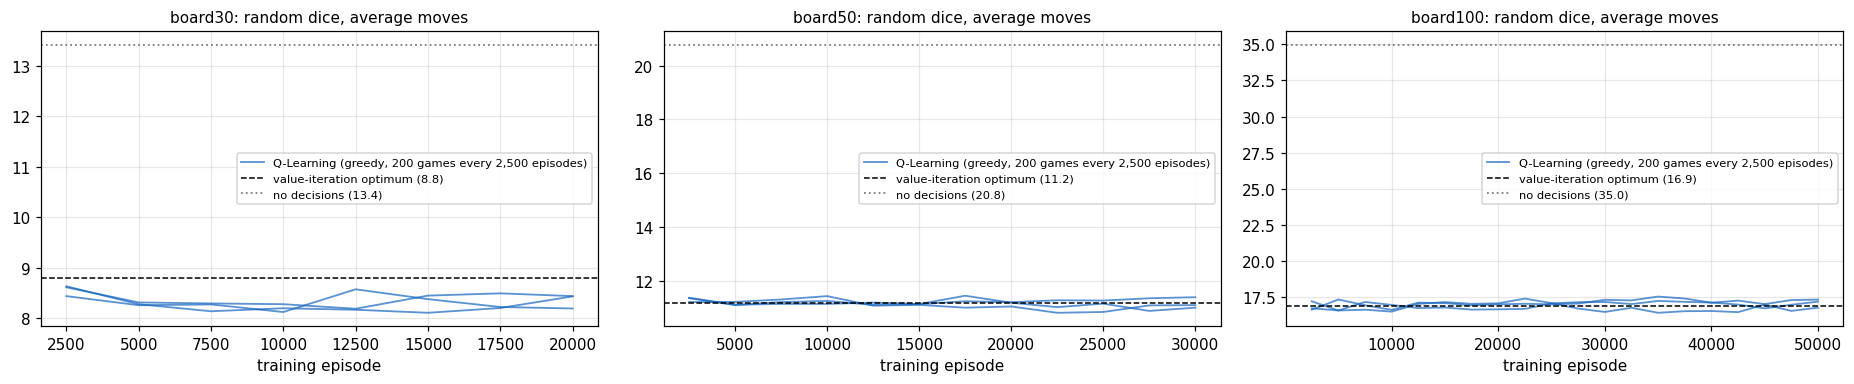

In [35]:
fig, axes = plt.subplots(1, len(boards), figsize=(17, 3.6))
for ax, (name, b) in zip(axes, boards.items()):
    opt_moves = two_dice[(two_dice.board == name) & (two_dice.policy == "Value-iteration optimum")]["avg moves"].iloc[0]
    rnd_moves = two_dice[(two_dice.board == name) & two_dice.policy.str.startswith("Random")]["avg moves"].iloc[0]
    for seed in TAB_SEEDS:
        e = two_dice_curves[(name, seed)]
        ax.plot(e["episode"], e["avg moves"], color=AGENT_COLORS["qlearning"], alpha=0.7, lw=1.2,
                label="Q-Learning (greedy, 200 games every 2,500 episodes)" if seed == 0 else None)
    ax.axhline(opt_moves, color="k", ls="--", lw=1, label=f"value-iteration optimum ({opt_moves:.1f})")
    ax.axhline(rnd_moves, color="grey", ls=":", lw=1.2, label=f"no decisions ({rnd_moves:.1f})")
    ax.set_title(f"{name}: random dice, average moves", fontsize=10)
    ax.set_xlabel("training episode")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "challenge1_random_dice.png", dpi=150, bbox_inches="tight")
plt.show()

### 13.3 Challenge 5: DQN vs tabular Q-Learning on a larger board

**Design.** A fourth board with **200 squares, 12 snakes and 12 ladders** (seed 2200, same generator rules). Q-Learning is trained for 30,000 episodes and DQN for 150,000 environment steps, each with 3 seeds. Both are measured with the same metrics as before.

**Why:** the Q-table grows linearly with $N$, and every square must be visited to be learned. A network can in principle **generalise** across squares, but with one-hot inputs every square is a separate input unit, so this experiment tests whether that advantage appears at all at this scale.

**A twist this board reveals:** here the shortest game (BFS: 14 moves) is *not* the highest-return game. Value iteration's optimal game takes **15 moves**: it deliberately lands on a snake (161 → 138, −20) to reach the long ladder 139 → 177 (+20). It uses 4 ladders instead of 3 and earns a return of 151 against the shortest game's 150. RL maximises return, so an agent that plays 15 moves here is *correct*, not one move short. That's why this section also judges agents against the Q\* game ("matches Q\* game", "steps to Q\* game"). On boards 30–100 the two references coincide.

Set `RUN_BOARD200_DQN = False` to skip the DQN part (about 10 minutes on Colab).

In [36]:
RUN_BOARD200_DQN = True          # about 10 minutes on Colab; set False to skip
big = make_board(200, 12, 12, seed=2200, name="board200")
assert validate_board(big) == []
bfs_moves["board200"] = bfs_optimal(big)["moves"]
qstar["board200"] = value_iteration(big)
masks["board200"] = {"qstar": qstar_action_mask(qstar["board200"]), "bfs": optimal_action_mask(big)}
print(big.describe(), f"\nBFS optimum: {bfs_moves['board200']} moves")

big_runs = {"qlearning": [], "dqn": []}
for seed in TAB_SEEDS:
    stem = TAB_DIR / f"qlearning_board200_seed{seed}"
    if FORCE_RETRAIN or not Path(f"{stem}_evals.csv").exists():
        t0 = time.perf_counter()
        Q, log, evals = train_tabular("qlearning", big, 30_000, seed)
        seconds = time.perf_counter() - t0
        log.assign(seconds=seconds).to_csv(f"{stem}_log.csv", index=False)
        evals.to_csv(f"{stem}_evals.csv", index=False)
        np.save(stem.with_suffix(".npy"), Q)
    else:
        log, evals = pd.read_csv(f"{stem}_log.csv"), pd.read_csv(f"{stem}_evals.csv")
        seconds = float(log["seconds"].iloc[0])
    big_runs["qlearning"].append({"log": log, "evals": evals, "seconds": seconds})
if RUN_BOARD200_DQN:
    for seed in DRL_SEEDS:
        big_runs["dqn"].append(run_or_load_drl("dqn", big, 150_000, seed))

def qstar_game(board, name):
    return run_episode(SmartDiceEnv(board), greedy_policy_from_q(qstar[name]))


def steps_to_qstar_return(evals, target_return):
    # First env step from which the greedy game earns the optimal return and keeps earning it.
    ok = (evals["greedy_success"] & np.isclose(evals["greedy_return"], target_return)).to_numpy()
    if not ok[-1]:
        return np.nan
    bad = np.flatnonzero(~ok)
    return int(evals["env_steps"].iloc[0 if len(bad) == 0 else bad[-1] + 1])


qg = qstar_game(big, "board200")
print(f"\nReturn-optimal (Q*) game on board200: {qg['moves']} moves, return {qg['return']:.0f} "
      f"(BFS: {bfs_moves['board200']} moves). Squares: {qg['path']}")

big_table = pd.DataFrame([{"agent": AGENTS[a], **summarize_runs(runs, "board200"),
                           "matches Q* game (seeds)": f"{sum(bool(r['evals'].iloc[-1]['greedy_success']) and np.isclose(r['evals'].iloc[-1]['greedy_return'], qg['return']) for r in runs)}/{len(runs)}"}
                          for a, runs in big_runs.items() if runs])
scaling_rows = []
for name in list(boards) + ["board200"]:
    board_obj = big if name == "board200" else boards[name]
    target = qstar_game(board_obj, name)["return"]
    for a in ("qlearning", "dqn"):
        runs = big_runs[a] if name == "board200" else agent_runs(a, name)
        if runs:
            reached = [steps_to_qstar_return(r["evals"], target) for r in runs]
            scaling_rows.append({"board": name, "N": int(name[5:]), "agent": AGENTS[a],
                                 "steps to Q* game": np.nan if np.isnan(reached).all() else np.nanmean(reached),
                                 "seeds reaching it": f"{int(np.sum(~np.isnan(reached)))}/{len(runs)}",
                                 "optimal-action % (Q*)": np.mean([r["evals"].iloc[-1]["optimal_action_pct"] for r in runs])})
scaling = pd.DataFrame(scaling_rows)
big_table.to_csv(RESULTS_DIR / "challenge5_board200.csv", index=False)
scaling.to_csv(RESULTS_DIR / "challenge5_scaling.csv", index=False)
display(big_table)
scaling.round(1)

board200: N=200
  ladders: 4->59, 10->56, 13->46, 18->48, 30->94, 32->65, 38->104, 67->101, 125->146, 132->174, 139->177, 145->166
  snakes:  36->9, 41->14, 62->17, 66->45, 86->24, 116->55, 127->97, 151->108, 161->138, 172->123, 187->122, 196->150 
BFS optimum: 14 moves

Return-optimal (Q*) game on board200: 15 moves, return 151 (BFS: 14 moves). Squares: [1, 59, 61, 101, 107, 113, 119, 146, 149, 155, 138, 177, 182, 188, 194, 200]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,agent,greedy moves,gap to BFS,optimal seeds,optimal-action % (Q*),greedy return,steps to optimal,steps to near-optimal,late stability %,train time (s),matches Q* game (seeds)
0,Q-Learning,15.0 ± 0.0,1.0 ± 0.0,0/3,93.1 ± 1.2,151.0 ± 0.0,not reached,19630 ± 1729,0.0 ± 0.0,17.9 ± 0.8,3/3
1,DQN,14.0 ± 0.0,0.0 ± 0.0,3/3,93.1 ± 2.4,150.0 ± 0.0,145500 ± 1225,81500 ± 45255,83.3 ± 9.4,197.8 ± 2.4,0/3


,board,N,agent,steps to Q* game,seeds reaching it,optimal-action % (Q*)
0,board30,30,Q-Learning,626.7,3/3,91.3
1,board30,30,DQN,17866.7,3/3,100.0
2,board50,50,Q-Learning,6960.3,3/3,88.9
3,board50,50,DQN,22600.0,3/3,99.1
4,board100,100,Q-Learning,18497.7,3/3,87.1
5,board100,100,DQN,29333.3,3/3,92.8
6,board200,200,Q-Learning,124791.3,3/3,93.1
7,board200,200,DQN,NaN,0/3,93.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


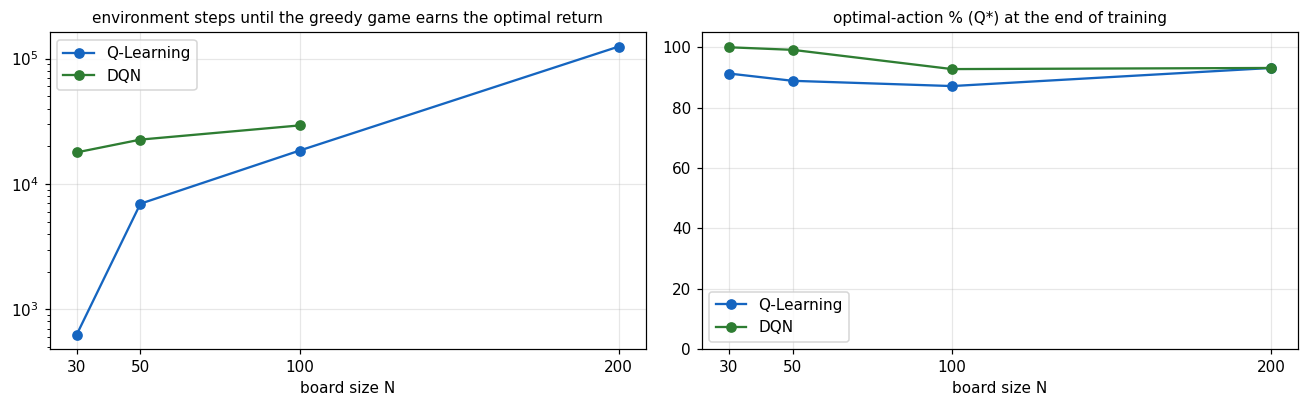

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for a in ("qlearning", "dqn"):
    d = scaling[scaling.agent == AGENTS[a]]
    axes[0].plot(d["N"], d["steps to Q* game"], "o-", color=AGENT_COLORS[a], label=AGENTS[a])
    axes[1].plot(d["N"], d["optimal-action % (Q*)"], "o-", color=AGENT_COLORS[a], label=AGENTS[a])
axes[0].set_yscale("log")
axes[0].set_title("environment steps until the greedy game earns the optimal return", fontsize=10)
axes[1].set_title("optimal-action % (Q*) at the end of training", fontsize=10)
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.set_xlabel("board size N")
    ax.set_xticks([30, 50, 100, 200])
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "challenge5_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Demonstration: the agents before and after training

### 14.1 Interactive board explorer

**What this does:** builds an interactive board, playable right in the notebook (Colab, Jupyter or VS Code), and also saves it as a standalone page at `results/board_explorer.html` that opens in any browser.

- **Pick a board and an agent**, then press **Play** to watch its game move by move. The token slides along each dice move and then up the ladder or down the snake. **Step**, **scrub** or click a row in the move log to jump to any move.
- **Hover over any square** to see what it is, the Q\*-optimal dice there, the BFS distance to the goal, and the dice **every** agent would choose (✓ optimal, ✗ not).
- **Policy quality view** colours every square green or red depending on whether the selected agent's dice there is optimal, with the dice value written in the square. This makes the *optimal-action %* metric visible, including squares the agent never visits in its own game.
- **Show other agents' routes** overlays every agent's game as a dashed line for comparison.

The "before training" agent is the random policy. The trained agents use seed 0, so their games are reproducible. BFS and Q\* (value iteration) are the two exact references.

In [38]:
import json
import uuid
from IPython.display import HTML, display

EXPLORER_TEMPLATE = r'''<div id="__ROOT__" class="sdx">
<style>
#__ROOT__{font-family:-apple-system,"Segoe UI",Roboto,Helvetica,Arial,sans-serif;color:#1f2328;background:#fff;border:1px solid #d0d7de;border-radius:10px;padding:14px 16px;max-width:1180px;box-sizing:border-box}
#__ROOT__ *{box-sizing:border-box}
#__ROOT__ h3{margin:0 0 2px;font-size:17px}
#__ROOT__ .sub{color:#57606a;font-size:12.5px;margin-bottom:10px}
#__ROOT__ .row{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin-bottom:8px}
#__ROOT__ .lbl{font-size:12px;color:#57606a;width:58px}
#__ROOT__ button{font:inherit;font-size:12.5px;border:1px solid #d0d7de;background:#f6f8fa;border-radius:6px;padding:4px 10px;cursor:pointer;color:#1f2328}
#__ROOT__ button:hover{background:#eef1f4}
#__ROOT__ button.on{background:#1f2328;color:#fff;border-color:#1f2328}
#__ROOT__ button.agent{display:inline-flex;align-items:center;gap:6px}
#__ROOT__ button.agent .dot{width:9px;height:9px;border-radius:50%}
#__ROOT__ button:disabled{opacity:.4;cursor:default}
#__ROOT__ .main{display:flex;gap:14px;align-items:flex-start;flex-wrap:wrap}
#__ROOT__ .boardwrap{position:relative;flex:0 0 auto}
#__ROOT__ svg{display:block;background:#fff;border-radius:6px}
#__ROOT__ .side{flex:1 1 300px;min-width:280px;max-width:420px}
#__ROOT__ .stats{display:grid;grid-template-columns:1fr 1fr;gap:6px;margin-bottom:8px}
#__ROOT__ .stat{background:#f6f8fa;border-radius:6px;padding:6px 8px}
#__ROOT__ .stat .k{font-size:11px;color:#57606a}
#__ROOT__ .stat .v{font-size:16px;font-weight:600}
#__ROOT__ .log{height:300px;overflow:auto;border:1px solid #d0d7de;border-radius:6px;font-size:12.5px}
#__ROOT__ .log div{padding:3px 8px;border-bottom:1px solid #f0f2f4;cursor:pointer;display:flex;gap:8px}
#__ROOT__ .log div.cur{background:#fff8c5}
#__ROOT__ .log .n{color:#8c959f;width:26px;text-align:right}
#__ROOT__ .ev-ladder{color:#1a7f37;font-weight:600}
#__ROOT__ .ev-snake{color:#cf222e;font-weight:600}
#__ROOT__ .ev-invalid{color:#9a6700;font-weight:600}
#__ROOT__ .ev-goal{color:#0969da;font-weight:600}
#__ROOT__ .controls{display:flex;gap:6px;align-items:center;flex-wrap:wrap;margin:8px 0}
#__ROOT__ input[type=range]{accent-color:#1f2328}
#__ROOT__ .tip{position:absolute;pointer-events:none;background:#1f2328;color:#fff;font-size:12px;border-radius:6px;padding:7px 9px;max-width:260px;line-height:1.45;display:none;z-index:5;box-shadow:0 4px 12px rgba(0,0,0,.2)}
#__ROOT__ .tip b{color:#fff}
#__ROOT__ .ok{color:#4ac26b}
#__ROOT__ .bad{color:#ff8182}
#__ROOT__ .legend{font-size:11.5px;color:#57606a;display:flex;gap:12px;flex-wrap:wrap;margin-top:6px}
#__ROOT__ .sw{display:inline-block;width:12px;height:12px;border-radius:3px;vertical-align:-2px;margin-right:4px}
#__ROOT__ .note{font-size:12px;color:#57606a;margin-top:6px}
</style>
<h3>Smart Dice board explorer</h3>
<div class="sub">Pick a board and an agent, then press play. Hover any square to see what every agent would do there.</div>
<div class="row"><span class="lbl">Board</span><span class="boards"></span></div>
<div class="row"><span class="lbl">Agent</span><span class="agents"></span></div>
<div class="row"><span class="lbl">View</span>
  <button class="v-path on">Game</button><button class="v-policy">Policy quality</button>
  <label style="font-size:12.5px;margin-left:8px"><input type="checkbox" class="ghosts"> show other agents' routes</label>
</div>
<div class="main">
  <div class="boardwrap"><svg class="board"></svg><div class="tip"></div></div>
  <div class="side">
    <div class="stats">
      <div class="stat"><div class="k">moves (BFS optimum)</div><div class="v s-moves">-</div></div>
      <div class="stat"><div class="k">total reward</div><div class="v s-ret">-</div></div>
      <div class="stat"><div class="k">optimal dice on squares</div><div class="v s-opt">-</div></div>
      <div class="stat"><div class="k">outcome</div><div class="v s-out">-</div></div>
    </div>
    <div class="controls">
      <button class="b-reset" title="restart">&#9198;</button>
      <button class="b-back" title="previous move">&#9664;</button>
      <button class="b-play" title="play / pause">&#9654; Play</button>
      <button class="b-next" title="next move">&#9654;&#124;</button>
      <span style="font-size:12px;color:#57606a">speed</span><input type="range" class="speed" min="1" max="10" value="5" style="width:80px">
    </div>
    <div class="controls"><span style="font-size:12px;color:#57606a">move</span><input type="range" class="scrub" min="0" max="0" value="0" style="flex:1"><span class="s-at" style="font-size:12px;width:62px;text-align:right">0 / 0</span></div>
    <div class="log"></div>
    <div class="legend legend-path"><span><span class="sw" style="background:#2da44e"></span>ladder</span><span><span class="sw" style="background:#cf222e"></span>snake</span><span><span class="sw" style="background:#fff8c5;border:1px solid #d4a72c"></span>start / goal</span></div>
    <div class="legend legend-policy" style="display:none"><span><span class="sw" style="background:#aceebb"></span>agent picks a Q*-optimal dice</span><span><span class="sw" style="background:#ffcecb"></span>not optimal</span><span><span class="sw" style="background:#eaeef2"></span>agent never stands here</span></div>
    <div class="note"></div>
  </div>
</div>
<script>
(function(){
const DATA = __DATA__;
const root = document.getElementById("__ROOT__");
const $ = s => root.querySelector(s);
const NS = "http://www.w3.org/2000/svg";
const CS = 50, COLS = 10;
let st = {board: DATA.boards[0].name, agent: null, view: "path", k: 0, playing: false, t: 0, timer: null};

function el(tag, attrs, parent){const e=document.createElementNS(NS,tag);for(const a in attrs)e.setAttribute(a,attrs[a]);if(parent)parent.appendChild(e);return e;}
function B(){return DATA.boards.find(b=>b.name===st.board);}
function rowsOf(b){return Math.ceil(b.n/COLS);}
function xy(b,s){const i=s-1,r=Math.floor(i/COLS);let c=i%COLS;if(r%2===1)c=COLS-1-c;return [c*CS+CS/2,(rowsOf(b)-1-r)*CS+CS/2];}
function ctrl(p,q,bend){const mx=(p[0]+q[0])/2,my=(p[1]+q[1])/2,dx=q[0]-p[0],dy=q[1]-p[1],L=Math.hypot(dx,dy)||1;return [mx-dy/L*bend*L*0.25,my+dx/L*bend*L*0.25];}
function lerp(a,b,t){return [a[0]+(b[0]-a[0])*t,a[1]+(b[1]-a[1])*t];}
function qbez(p,c,q,t){const u=1-t;return [u*u*p[0]+2*u*t*c[0]+t*t*q[0],u*u*p[1]+2*u*t*c[1]+t*t*q[1]];}

function segments(b,ag){
  // keyframe segments for an agent's game: dice move, then (if any) the jump along the ladder/snake
  const segs=[];
  ag.steps.forEach((m,i)=>{
    if(m.event==="invalid"){segs.push({p:xy(b,m.from),q:xy(b,m.from),c:null,move:i+1,kind:"stay"});return;}
    segs.push({p:xy(b,m.from),q:xy(b,m.target),c:null,move:i+1,kind:"move"});
    if(m.target!==m.to){const isSnake=m.to<m.target;const p=xy(b,m.target),q=xy(b,m.to);
      segs.push({p:p,q:q,c:isSnake?ctrl(p,q,0.9):null,move:i+1,kind:isSnake?"snake":"ladder"});}
  });
  return segs;
}

function drawBoard(){
  const b=B(), svg=$(".board"), R=rowsOf(b), W=COLS*CS, H=R*CS;
  svg.innerHTML=""; svg.setAttribute("viewBox",`0 0 ${W} ${H}`); svg.setAttribute("width",Math.min(W,560)); svg.setAttribute("height",Math.min(W,560)*H/W);
  const ag=b.agents[st.agent], gCells=el("g",{},svg);
  for(let s=1;s<=b.n;s++){
    const [x,y]=xy(b,s); let fill=(s===1||s===b.n)?"#fff8c5":(s%2?"#f6f8fa":"#ffffff");
    if(st.view==="policy"){
      const jump=b.ladders[s]!==undefined||b.snakes[s]!==undefined;
      if(s===b.n||jump||!ag||!ag.policy) fill="#eaeef2";
      else fill=b.qstar_opt[s-1].includes(ag.policy[s-1])?"#aceebb":"#ffcecb";
    }
    const r=el("rect",{x:x-CS/2,y:y-CS/2,width:CS,height:CS,fill:fill,stroke:"#d0d7de","stroke-width":0.8,"data-s":s},gCells);
    const t=el("text",{x:x-CS/2+3,y:y-CS/2+11,"font-size":9.5,fill:"#6e7781"},gCells); t.textContent=s;
    const playable=s!==b.n&&b.ladders[s]===undefined&&b.snakes[s]===undefined;
    if(st.view==="policy"&&playable&&ag&&ag.policy&&ag.policy[s-1]){const d=el("text",{x:x,y:y+7,"font-size":15,"font-weight":700,"text-anchor":"middle",fill:"#1f2328"},gCells);d.textContent=ag.policy[s-1];}
    if(s===1||s===b.n){const l=el("text",{x:x,y:y+15,"font-size":8.5,"font-weight":700,"text-anchor":"middle",fill:"#9a6700"},gCells);l.textContent=s===1?"START":"GOAL";}
  }
  const gJ=el("g",{"pointer-events":"none",opacity:st.view==="policy"?0.35:1},svg);
  for(const a in b.ladders){const p=xy(b,+a),q=xy(b,b.ladders[a]),dx=q[0]-p[0],dy=q[1]-p[1],L=Math.hypot(dx,dy),nx=-dy/L*5,ny=dx/L*5;
    el("line",{x1:p[0]+nx,y1:p[1]+ny,x2:q[0]+nx,y2:q[1]+ny,stroke:"#2da44e","stroke-width":3,"stroke-linecap":"round"},gJ);
    el("line",{x1:p[0]-nx,y1:p[1]-ny,x2:q[0]-nx,y2:q[1]-ny,stroke:"#2da44e","stroke-width":3,"stroke-linecap":"round"},gJ);
    const rungs=Math.max(2,Math.floor(L/14));for(let i=1;i<rungs;i++){const m=lerp(p,q,i/rungs);el("line",{x1:m[0]+nx,y1:m[1]+ny,x2:m[0]-nx,y2:m[1]-ny,stroke:"#2da44e","stroke-width":2},gJ);}}
  for(const h in b.snakes){const p=xy(b,+h),q=xy(b,b.snakes[h]),c=ctrl(p,q,0.9);
    el("path",{d:`M${p[0]},${p[1]} Q${c[0]},${c[1]} ${q[0]},${q[1]}`,stroke:"#cf222e","stroke-width":5,fill:"none","stroke-linecap":"round",opacity:0.85},gJ);
    el("circle",{cx:p[0],cy:p[1],r:5.5,fill:"#cf222e"},gJ);}
  if(st.view==="path"){
    if($(".ghosts").checked){for(const k in b.agents){if(k===st.agent)continue;const o=b.agents[k];
      el("path",{d:pathD(segments(b,o),1e9),stroke:o.color,"stroke-width":2,fill:"none","stroke-dasharray":"4 3",opacity:0.55,"pointer-events":"none"},svg);}}
    el("path",{class:"trail",stroke:ag?ag.color:"#000","stroke-width":3,fill:"none","stroke-linejoin":"round",opacity:0.9,"pointer-events":"none"},svg);
    el("circle",{class:"token",r:9,fill:ag?ag.color:"#000",stroke:"#fff","stroke-width":2.5,"pointer-events":"none"},svg);
  }
  svg.onmousemove=ev=>hover(ev); svg.onmouseleave=()=>{$(".tip").style.display="none";};
}

function pathD(segs,upto){let d="";segs.forEach((g,i)=>{if(g.move>upto)return;if(i===0||d==="")d+=`M${g.p[0]},${g.p[1]} `;d+=g.c?`Q${g.c[0]},${g.c[1]} ${g.q[0]},${g.q[1]} `:`L${g.q[0]},${g.q[1]} `;});return d;}

function render(){
  const b=B(), ag=b.agents[st.agent]; if(!ag) return;
  const segs=segments(b,ag), n=ag.steps.length;
  $(".scrub").max=n; $(".scrub").value=st.k; $(".s-at").textContent=`${st.k} / ${n}`;
  if(st.view==="path"){
    const trail=root.querySelector(".trail"), tok=root.querySelector(".token");
    let d=pathD(segs,st.k), pos=xy(b,st.k===0?1:ag.steps[st.k-1].to);
    if(st.playing&&st.k<n){ // animate the next move's segments
      const cur=segs.filter(g=>g.move===st.k+1), T=st.t*cur.length, i=Math.min(cur.length-1,Math.floor(T)), f=T-i;
      if(d==="") d=`M${xy(b,1)[0]},${xy(b,1)[1]} `;
      cur.slice(0,i).forEach(g=>{d+=g.c?`Q${g.c[0]},${g.c[1]} ${g.q[0]},${g.q[1]} `:`L${g.q[0]},${g.q[1]} `;});
      const g=cur[i]; pos=g.c?qbez(g.p,g.c,g.q,f):lerp(g.p,g.q,f); d+=`L${pos[0]},${pos[1]}`;
    }
    trail.setAttribute("d",d); tok.setAttribute("cx",pos[0]); tok.setAttribute("cy",pos[1]);
  }
  root.querySelectorAll(".log div").forEach((r,i)=>{r.classList.toggle("cur",i===st.k-1);});
  const cur=root.querySelector(".log div.cur"); if(cur){const L=$(".log");if(cur.offsetTop<L.scrollTop||cur.offsetTop>L.scrollTop+L.clientHeight-24)L.scrollTop=cur.offsetTop-L.clientHeight/2;}
  $(".b-play").innerHTML=st.playing?"&#10074;&#10074; Pause":"&#9654; Play";
}

function fillSide(){
  const b=B(), ag=b.agents[st.agent];
  $(".s-moves").textContent=`${ag.moves} (${b.bfs_moves})`;
  $(".s-ret").textContent=ag.ret.toFixed(0);
  $(".s-opt").textContent=ag.policy?`${ag.opt_pct.toFixed(0)}%`:"n/a";
  const bestRet=Math.abs(ag.ret-b.qstar_return)<1e-6;
  $(".s-out").innerHTML=!ag.success?'<span style="color:#cf222e">move limit</span>':
    (ag.moves===b.bfs_moves&&bestRet?'<span style="color:#1a7f37">optimal</span>':
     bestRet?'<span style="color:#1a7f37">optimal (max return)</span>':
     ag.moves===b.bfs_moves?'<span style="color:#1a7f37">optimal (fewest moves)</span>':"reached goal");
  $(".note").textContent=ag.note||"";
  const log=$(".log"); log.innerHTML="";
  ag.steps.forEach((m,i)=>{const r=document.createElement("div");
    const ev=m.event==="normal"?"":` <span class="ev-${m.event}">${m.event}</span>`;
    const jump=m.target!==m.to?` &rarr; ${m.to}`:"";
    r.innerHTML=`<span class="n">${i+1}</span><span>${m.from} + dice ${m.dice} &rarr; ${m.event==="invalid"?"stays on "+m.from:m.target}${jump}${ev}</span><span style="margin-left:auto;color:#57606a">${m.reward>0?"+":""}${m.reward}</span>`;
    r.onclick=()=>{stop();st.k=i+1;render();}; log.appendChild(r);});
}

function hover(ev){
  const b=B(), svg=$(".board"), r=svg.getBoundingClientRect(), sx=(ev.clientX-r.left)*(COLS*CS)/r.width, sy=(ev.clientY-r.top)*(rowsOf(b)*CS)/r.height;
  const c=Math.floor(sx/CS), rr=rowsOf(b)-1-Math.floor(sy/CS); if(c<0||c>=COLS||rr<0){$(".tip").style.display="none";return;}
  const col=rr%2===1?COLS-1-c:c, s=rr*COLS+col+1; if(s<1||s>b.n){$(".tip").style.display="none";return;}
  let h=`<b>Square ${s}</b>`;
  if(b.ladders[s]!==undefined) h+=`<br>Ladder bottom: climbs to ${b.ladders[s]} (+20)`;
  else if(b.snakes[s]!==undefined) h+=`<br>Snake head: slides to ${b.snakes[s]} (&minus;20)`;
  else if(s===b.n) h+="<br>Goal (+100)";
  else{
    h+=`<br>Q*-optimal dice: <b>${b.qstar_opt[s-1].join(", ")}</b><br>BFS: ${b.bfs_dist[s-1]} moves to goal`;
    for(const k in b.agents){const a=b.agents[k];if(!a.policy)continue;const d=a.policy[s-1],ok=b.qstar_opt[s-1].includes(d);
      h+=`<br><span style="color:${a.color}">&#9679;</span> ${a.label}: dice ${d} <span class="${ok?"ok":"bad"}">${ok?"&#10003;":"&#10007;"}</span>`;}
  }
  const tip=$(".tip"), wrap=$(".boardwrap").getBoundingClientRect(); tip.innerHTML=h; tip.style.display="block";
  let left=ev.clientX-wrap.left+14, top=ev.clientY-wrap.top+14; if(left>wrap.width-200)left-=230; tip.style.left=left+"px"; tip.style.top=top+"px";
}

function stop(){st.playing=false;if(st.timer){cancelAnimationFrame(st.timer);st.timer=null;}}
function play(){
  const ag=B().agents[st.agent]; if(st.k>=ag.steps.length) st.k=0;
  st.playing=true; st.t=0; let last=performance.now();
  const tick=now=>{if(!st.playing)return;const dt=(now-last)/1000;last=now;st.t+=dt*(0.4+0.32*$(".speed").value);
    if(st.t>=1){st.t=0;st.k++;if(st.k>=ag.steps.length){st.k=ag.steps.length;stop();render();return;}}
    render(); st.timer=requestAnimationFrame(tick);};
  render(); st.timer=requestAnimationFrame(tick);
}

function buildButtons(){
  const bw=$(".boards"); bw.innerHTML="";
  DATA.boards.forEach(b=>{const x=document.createElement("button");x.textContent=`${b.name} (N=${b.n})`;x.className=b.name===st.board?"on":"";
    x.onclick=()=>{stop();st.board=b.name;if(!B().agents[st.agent])st.agent=Object.keys(B().agents)[0];st.k=0;buildButtons();drawBoard();fillSide();render();};bw.appendChild(x);});
  const aw=$(".agents"); aw.innerHTML=""; const b=B();
  for(const k in b.agents){const a=b.agents[k],x=document.createElement("button");x.className="agent"+(k===st.agent?" on":"");
    x.innerHTML=`<span class="dot" style="background:${a.color}"></span>${a.label}`;
    x.onclick=()=>{stop();st.agent=k;st.k=0;buildButtons();drawBoard();fillSide();render();};aw.appendChild(x);}
}

$(".v-path").onclick=()=>{st.view="path";$(".v-path").classList.add("on");$(".v-policy").classList.remove("on");$(".legend-path").style.display="";$(".legend-policy").style.display="none";drawBoard();render();};
$(".v-policy").onclick=()=>{stop();st.view="policy";$(".v-policy").classList.add("on");$(".v-path").classList.remove("on");$(".legend-path").style.display="none";$(".legend-policy").style.display="";drawBoard();render();};
$(".ghosts").onchange=()=>{drawBoard();render();};
$(".b-play").onclick=()=>{st.playing?stop():play();render();};
$(".b-reset").onclick=()=>{stop();st.k=0;render();};
$(".b-back").onclick=()=>{stop();st.k=Math.max(0,st.k-1);render();};
$(".b-next").onclick=()=>{stop();st.k=Math.min(B().agents[st.agent].steps.length,st.k+1);render();};
$(".scrub").oninput=e=>{stop();st.k=+e.target.value;render();};

st.agent = DATA.default_agent in B().agents ? DATA.default_agent : Object.keys(B().agents)[0];
buildButtons(); drawBoard(); fillSide(); render();
})();
</script>
</div>
'''


def trace_game(board, policy, seed=None):
    # Play one game and record every move: square, dice, landing square, jump end, event, reward.
    env = SmartDiceEnv(board)
    obs, info = env.reset(seed=seed)
    steps, total, terminated, truncated = [], 0.0, False, False
    while not (terminated or truncated):
        prev = env.pos
        obs, r, terminated, truncated, info = env.step(policy(obs, env))
        target = prev if info["event"] == "invalid" else prev + info["dice"]
        steps.append({"from": prev, "dice": info["dice"], "target": target, "to": info["position"],
                      "event": info["event"], "reward": r})
        total += r
    return steps, total, bool(terminated)


def policy_from_square_actions(actions):
    # actions[s-1] = action index on square s  ->  a policy usable by SmartDiceEnv
    return lambda obs, env: int(actions[env.pos - 1])


def explorer_agents(board, name):
    rows = np.array(playable_squares(board)) - 1
    qmask = masks[name]["qstar"]
    agents = {}

    def add(key, label, color, actions=None, policy=None, note=""):
        pol = policy or policy_from_square_actions(actions)
        steps, total, success = trace_game(board, pol, seed=SEED)
        entry = {"label": label, "color": color, "steps": steps, "moves": len(steps), "ret": total,
                 "success": success, "policy": None, "opt_pct": None, "note": note}
        if actions is not None:
            entry["policy"] = [int(a) + 1 for a in actions[:-1]] + [None]          # dice per square, goal = None
            entry["opt_pct"] = float(100 * qmask[rows, np.asarray(actions)[rows]].mean())
        agents[key] = entry

    add("random", "Random (before training)", "#8c959f", policy=RandomPolicy(SEED + 7),
        note="A random policy: the agent before any learning.")
    add("bfs", "BFS (fewest moves)", "#57606a", actions=optimal_action_mask(board).argmax(axis=1),
        note="Breadth-first search: the exact shortest game. It uses the rules directly and is a reference, not a learner.")
    add("qstar", "Q* (value iteration)", "#0a3069", actions=qstar[name].argmax(axis=1),
        note="Value iteration: the exact highest-return policy, i.e. what RL is trying to learn.")
    for algo in ("qlearning", "sarsa"):
        key = (algo, name, 0)
        Q = tabular[key]["Q"] if key in tabular else (np.load(TAB_DIR / f"{algo}_{name}_seed0.npy")
                                                      if (TAB_DIR / f"{algo}_{name}_seed0.npy").exists() else None)
        if Q is not None:
            add(algo, ALGOS[algo], AGENT_COLORS[algo], actions=Q.argmax(axis=1), note=f"{ALGOS[algo]}, seed 0, greedy policy.")
    for algo in DRL_ALGOS:
        zip_path = drl_paths(algo, name, 0)[0]
        if zip_path.exists():
            model = DRL_CLASSES[algo].load(zip_path, device="cpu")
            acts = np.asarray(model.predict(np.eye(board.n, dtype=np.float32), deterministic=True)[0]).astype(int)
            add(algo, DRL_ALGOS[algo], AGENT_COLORS[algo], actions=acts, note=f"{DRL_ALGOS[algo]}, seed 0, deterministic policy.")
    return agents


def explorer_board(board, name):
    return {"name": name, "n": board.n,
            "ladders": {str(k): v for k, v in board.ladders.items()},
            "snakes": {str(k): v for k, v in board.snakes.items()},
            "bfs_moves": bfs_moves[name],
            "qstar_return": float(run_episode(SmartDiceEnv(board), greedy_policy_from_q(qstar[name]))["return"]),
            "bfs_dist": [None if np.isinf(d) else int(d) for d in bfs_distances(board)[1:]],
            "qstar_opt": [[int(a) + 1 for a in np.flatnonzero(masks[name]["qstar"][s])] for s in range(board.n)],
            "agents": explorer_agents(board, name)}


explorer_boards = [explorer_board(b, name) for name, b in boards.items()] + [explorer_board(big, "board200")]
explorer_data = {"boards": explorer_boards, "default_agent": "qlearning"}
widget = (EXPLORER_TEMPLATE.replace("__ROOT__", "sdx" + uuid.uuid4().hex[:8])
                           .replace("__DATA__", json.dumps(explorer_data)))
(RESULTS_DIR / "board_explorer.html").write_text(
    "<!DOCTYPE html><html><head><meta charset='utf-8'><title>Smart Dice board explorer</title></head>"
    "<body style='margin:16px;background:#f6f8fa'>" + widget + "</body></html>", encoding="utf-8")
print("Saved results/board_explorer.html (open it in any browser).")
display(HTML(widget))

Saved results/board_explorer.html (open it in any browser).


### 14.2 Static before/after figures

The explorer needs JavaScript, which GitHub's notebook preview and PDF exports don't run. These figures show the same comparison as static images: the random agent's game (before training) next to the trained Q-Learning and DQN games (seed 0), on every board.

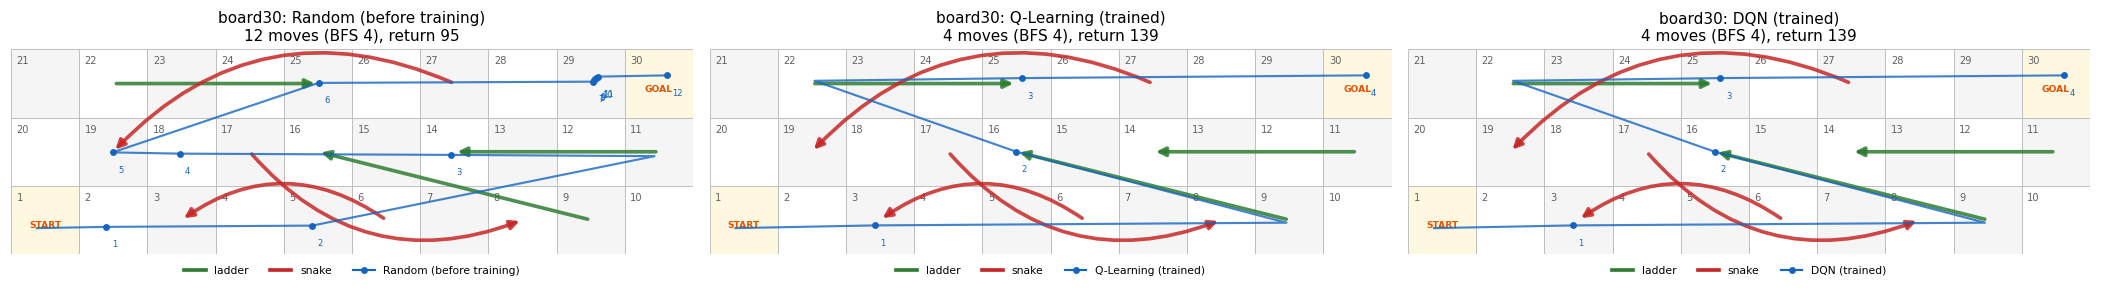

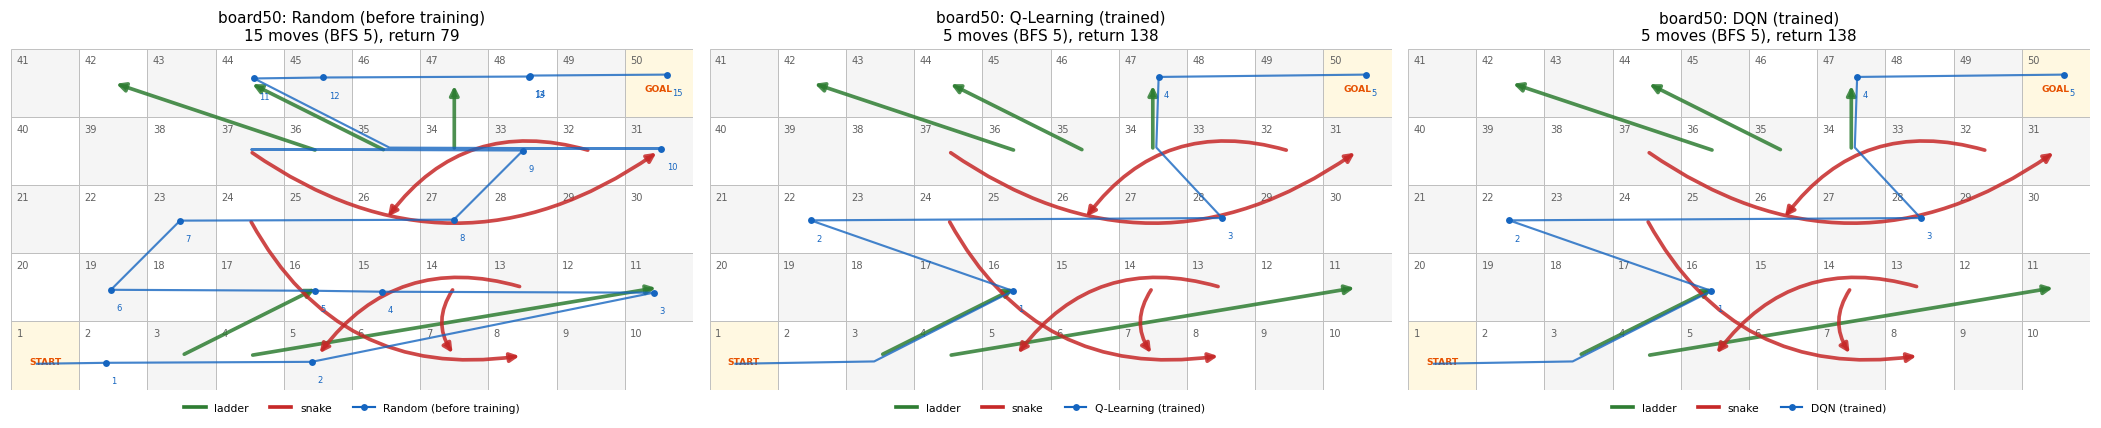

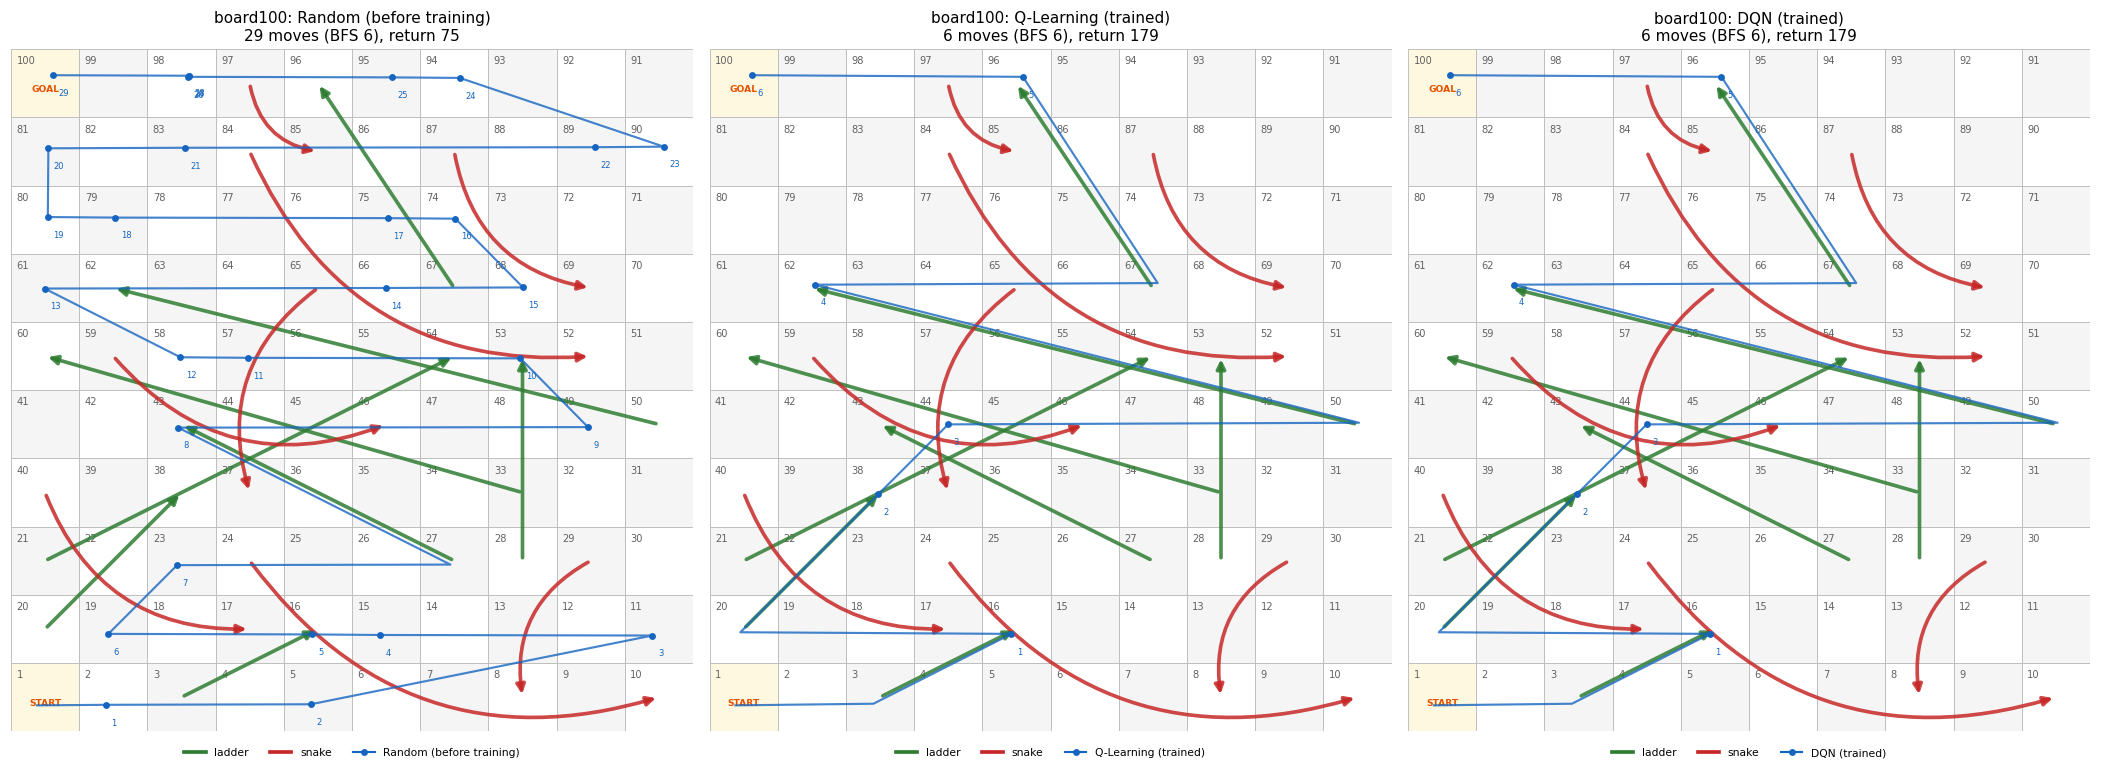

In [39]:
for name, b in boards.items():
    panels = [("Random (before training)", RandomPolicy(SEED + 7))]
    panels.append(("Q-Learning (trained)", greedy_policy_from_q(tabular[("qlearning", name, 0)]["Q"])))
    dqn_zip = drl_paths("dqn", name, 0)[0]
    if dqn_zip.exists():
        dqn_model = DQN.load(dqn_zip, device="cpu")
        panels.append(("DQN (trained)", lambda obs, env, m=dqn_model: int(m.predict(np.eye(env.n, dtype=np.float32)[env.pos - 1], deterministic=True)[0])))
    fig, axes = plt.subplots(1, len(panels), figsize=(6.4 * len(panels), 0.62 * np.ceil(b.n / 10) + 1.8))
    for ax, (label, pol) in zip(np.atleast_1d(axes), panels):
        game = run_episode(SmartDiceEnv(b), pol, seed=SEED)
        draw_board(b, path=game["path"][:61], ax=ax, path_label=label,
                   title=f"{name}: {label}\n{game['moves']} moves (BFS {bfs_moves[name]}), return {game['return']:.0f}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}_before_after.png", dpi=150, bbox_inches="tight")
    plt.show()

In [45]:
# Move-by-move replay of the trained Q-Learning agent on the 100-square board, using the environment's render().
env = SmartDiceEnv(boards["board100"])
policy = greedy_policy_from_q(tabular[("qlearning", "board100", 0)]["Q"])
obs, _ = env.reset()
print(env.render())
done = False
while not done:
    obs, r, terminated, truncated, info = env.step(policy(obs, env))
    print(env.render(), f"  reward {r:+.0f}")
    done = terminated or truncated

[board100] start on square 1/100
[board100] move   1:   1 --dice 2-->  16  (ladder)   reward +20
[board100] move   2:  16 --dice 4-->  38  (ladder)   reward +20
[board100] move   3:  38 --dice 6-->  44  (normal)   reward -1
[board100] move   4:  44 --dice 6-->  62  (ladder)   reward +20
[board100] move   5:  62 --dice 5-->  96  (ladder)   reward +20
[board100] move   6:  96 --dice 4--> 100  (goal)   reward +100


## 15. Report

### 15.1 Supporting experiment for Q4: what if the agent never explores?

Before answering Q4, one more cheap experiment: Q-Learning with **ε = 0 throughout** (always greedy, ties broken at random), against the default ε schedule. Same boards, seeds and budgets as Section 10.

In [46]:
no_explore = TabularConfig(eps_start=1e-12, eps_end=1e-12)   # effectively 0 (avoids log(0) in the schedule)
rows = []
for name, b in boards.items():
    for label, cfg in (("ε 1.0 -> 0.05 (default)", TabularConfig()), ("ε = 0 (no exploration)", no_explore)):
        runs = [tabular[("qlearning", name, s)]["evals"] for s in TAB_SEEDS] if label.endswith("(default)") else \
               [train_tabular("qlearning", b, TAB_EPISODES[name], s, cfg)[2] for s in TAB_SEEDS]
        final = [e.iloc[-1] for e in runs]
        rows.append({"board": name, "exploration": label,
                     "gap to BFS": mean_std([f["greedy_moves"] - bfs_moves[name] for f in final]),
                     "optimal-action % (Q*)": mean_std([f["optimal_action_pct"] for f in final]),
                     "episodes to optimal": mean_std([convergence_episode(e, bfs_moves[name]) for e in runs], "{:.0f}")})
exploration_ablation = pd.DataFrame(rows)
exploration_ablation.to_csv(RESULTS_DIR / "exploration_ablation.csv", index=False)
exploration_ablation

,board,exploration,gap to BFS,optimal-action % (Q*),episodes to optimal
0,board30,ε 1.0 -> 0.05 (default),0.0 ± 0.0,91.3 ± 3.5,50 ± 24
1,board30,ε = 0 (no exploration),1.0 ± 0.8,55.1 ± 4.1,10 ± 0 (2 seed(s) not reached)
2,board50,ε 1.0 -> 0.05 (default),0.0 ± 0.0,88.9 ± 3.2,437 ± 314
3,board50,ε = 0 (no exploration),2.3 ± 0.5,47.0 ± 6.7,not reached
4,board100,ε 1.0 -> 0.05 (default),0.0 ± 0.0,87.1 ± 5.7,60 ± 57
5,board100,ε = 0 (no exploration),0.3 ± 0.5,33.3 ± 3.0,20 ± 0 (1 seed(s) not reached)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 15.2 Answers to the project questions

Each answer points to the section whose results support it. Tabular numbers are fixed by the seeds. Deep-RL numbers are inserted automatically by the code cell after Q10, so they always match the latest run.

**Q1. Why can this game be modelled as a Markov Decision Process?**
The next square and the reward depend only on the **current square and the chosen dice**. The transition function in Section 4 takes nothing else as input. There is no hidden information, no history and no opponent, so the current square summarises everything relevant about the past: the Markov property. The MDP is $(S, A, P, R, \gamma)$ with $S = \{1,\dots,N\}$, $A = \{1,\dots,6\}$, a deterministic $P$, the reward table as $R$, square $N$ as the terminal state, and $\gamma = 0.99$ (Section 2). With random dice (Challenge 1), the rolled pair must be added to the state to keep it Markov, and $P$ becomes stochastic.

**Q2. What is the difference between the state space and the action space in this game?**
The **state space** is *where the agent can be*: $N$ squares (30 / 50 / 100). Only 23 / 39 / 83 of them are squares the agent can actually stand on, because it leaves snake heads and ladder bottoms immediately. The **action space** is *what it can do*: the same 6 dice values on every square, including values that overshoot $N$ (penalised by −10). The Q-table therefore has $N \times 6$ entries (180 / 300 / 600). The deep agents see the state as a one-hot vector of length $N$. In Challenge 1 the state becomes (square, dice pair) with $21N$ values and the action becomes a 2-way choice.

**Q3. How does the reward function affect the agent's behaviour?** (Section 13.1)
- **The optimal game is robust on these boards.** Under the brief's rewards, the sparse scheme, no step cost and goal-only reward, value iteration's optimal game is the same shortest game on boards 30, 50 and 100.
- **Learning speed is not robust.** On board 100, Q-Learning's greedy game becomes optimal for good after about 50 episodes with the brief's rewards, versus 150 (sparse), 192 (goal only) and 850 (no step cost). On board 50: 367 versus 633 (sparse) and 908 (goal only). The intermediate ladder/snake rewards act as *shaping*: they make good squares look valuable before the goal is ever reached. Without a step cost, only γ pushes the agent to hurry, and on board 50 one seed ended one move longer than optimal.
- **Shaping can break the task (reward hacking).** Raising the ladder reward from +20 to just **+23 (board 30) or +24 (board 100)** makes the optimal policy loop ladder → snake → ladder forever instead of finishing. Each climb pays now, and the snake's −20 arrives one move later, discounted. With +60, Q-Learning learned the loop on every seed (0/3 games finish on board 100). The brief's +20 is only slightly below this threshold. Board 50 has no ladder and snake close enough to form such a cycle.
- **The reward defines what "optimal" means.** On the 200-square board (Section 13.3), the highest-return game takes 15 moves, not the shortest 14, because one more ladder bonus outweighs one extra move.

**Q4. What is the role of ε-greedy exploration?** (Sections 10.1, 10.8, 15.1)
Exploration lets the agent try actions its current estimates undervalue, which is the only way it can discover ladders and learn the value of squares it would otherwise never reach. ε starts at 1 (no knowledge yet, so explore everything) and decays to 0.05 (exploit what was learned, keep a little exploration). Section 15.1 tests what happens without it: with ε = 0, Q-Learning still finishes every game, but only 55% / 47% / 33% of squares get an optimal dice (against 91% / 89% / 87% with exploration), its greedy game ends 1.0 / 2.3 / 0.3 moves longer than optimal on average, and it reaches the optimal game for good on only 1, 0 and 2 of the 3 seeds. Without exploration, the agent locks onto the first route that works and never finds the better ladders. Exploration also has a cost. With ε = 0.05 still active, the training games stay longer than the greedy games (e.g. 6.4 vs 6 moves on board 100). For SARSA, whose targets include its own random moves, exploration noise is exactly what keeps its policy flipping (Section 10.8).

**Q5. How does Q-Learning differ from SARSA in this game?** (Sections 10, 10.8)
Q-Learning's target uses the **best** next action, $\max_{a'} Q(s',a')$ (off-policy): it learns the optimal policy's values while behaving ε-greedily. SARSA's target uses the next action **actually taken**, $Q(s',a')$ (on-policy): it learns the value of its own ε-greedy behaviour. Because this game is deterministic, Q-Learning's target is deterministic too, and its greedy game stayed optimal at 100% of late evaluations on every board. SARSA's target is random whenever the next action is exploratory, so with a constant α its greedy game kept flipping between near-equal routes (optimal only 64% of late evaluations on board 50). A decaying α (0.1 → 0.01) removed this completely and made SARSA optimal after 117 / 497 / 160 episodes. SARSA, in turn, ended with the better policy *away* from its main route: 100% / 98% / 92% of squares Q\*-optimal against 91% / 89% / 87% for Q-Learning.

**Q6. Why might the two algorithms converge to different policies?** (Section 10.7)
1. **Ties:** many squares have several equally good dice values. Of the squares where the two seed-0 policies differ (4 / 19 / 29), **both** choices are optimal on 3 / 14 / 22.
2. **Different targets:** SARSA learns the values of the ε-greedy policy, including the risk of an exploratory move. Q-Learning learns the values of the greedy policy. When two actions are close, these different value functions can rank them differently.
3. **Visitation:** squares visited rarely keep inaccurate values. Q-Learning's errors are on squares off its own route (e.g. square 10 on board 30, where only dice 1 reaches the 11 → 14 ladder).
4. **Learning-rate noise:** with a constant α, SARSA's estimates keep moving, so its greedy choice between near-equal routes changes over time.

**Q7. How do snakes and ladders affect learning?**
Ladders make the problem *short*: the optimal games take only 4 / 5 / 6 moves on boards of 30 / 50 / 100 squares, and they use 2 / 2 / 4 ladders. Snakes make the choice of dice *matter*. A random player hits 1.1 / 2.3 / 2.8 snakes per game, while every learned optimal game hits none on these boards. Snakes are also why the "always 6" rule fails (Section 9): the best dice value depends on the square. For learning, every jump creates a big jump in value between neighbouring squares, which the agent must discover square by square. Jumps also create the ladder → snake cycles that make some reward designs unsafe (Q3).

**Q8. How can the agent learn the optimal path in fewer episodes?**
Supported by this project's results:
- **Decay the learning rate:** SARSA reached a stable optimum after 117 / 497 / 160 episodes instead of almost never (Section 10.8).
- **Shape the reward carefully:** ladder/snake rewards cut Q-Learning's episodes on board 100 from about 150 (sparse) to about 50 (Section 13.1). But keep shaping below the loop threshold (Q3).
- **Stop when converged:** the greedy game was within one move of optimal after only 20 / 73 / 33 Q-Learning episodes. Evaluating the greedy policy during training shows when to stop.
- **Reuse experience:** DQN's replay buffer trains on each move many times (Section 11).

Also worth trying, but not tested here: optimistic initial Q-values (systematic exploration) and planning methods (Dyna-Q) that learn a model of the board and replay it.

**Q9. How would the system behave with larger boards?** (Section 13.3)
A Q-table grows linearly with $N$ ($6N$ entries), and every square must be visited enough to learn its value, so the training needed grows with the board. Q-Learning needed about 630 → 1,960 environment steps from board 30 to board 100 to stay optimal, and about 125,000 to reach the return-optimal game on board 200. Even so, on the 200-square board it learned that exact game (15 moves, return 151) on all 3 seeds. In the submitted run, DQN on board 200 learned the *shortest* game (14 moves, return 150) on all 3 seeds, not the return-optimal one. A one-point difference in return (0.7%) is small enough to be lost in the network's approximation error. DQN did end with a slightly better whole policy (94.9% vs 93.1% of squares optimal), but needed about 3× more steps to get within one move (≈ 54,500 vs 19,600). At this scale a table is still feasible and more sample-efficient. A network's advantage would appear with inputs that let it generalise across squares (e.g. position plus the board layout) and with boards too large or too varied for a table. The cell below gives this run's numbers.

**Q10. How does the learned policy compare with the BFS optimal path?**
On boards 30, 50 and 100, Q-Learning, SARSA and DQN reach the BFS optimum (4 / 5 / 6 moves) on every seed. PPO does on 8 of 9 seeds and A2C on 6 of 9 (A2C fails on board 100, Section 12.2). BFS finds the answer instantly and exactly, while RL needs hundreds to thousands of moves of practice. BFS and RL optimise different things, though: BFS minimises the **number of moves**, while RL maximises the **discounted return**. They choose different optimal dice on 30% / 0% / 13% of squares on boards 30 / 50 / 100, and the 200-square board shows a case where the return-optimal game is one move longer.

In [42]:
# Deep-RL numbers for Q9 and Q10, taken from this run's results.
lines = ["**Deep-RL numbers for Q9 and Q10 (this run):**", ""]
for name in boards:
    parts = []
    for algo, label in DRL_ALGOS.items():
        runs = agent_runs(algo, name)
        final = [r["evals"].iloc[-1] for r in runs]
        n_opt = sum(bool(f["greedy_success"]) and f["greedy_moves"] == bfs_moves[name] for f in final)
        gap = np.mean([f["greedy_moves"] - bfs_moves[name] for f in final])
        parts.append(f"{label} optimal on {n_opt}/{len(runs)} seeds (mean gap {gap:+.1f} moves, "
                     f"{np.mean([f['optimal_action_pct'] for f in final]):.0f}% of squares Q*-optimal)")
    lines.append(f"- **{name}** (BFS {bfs_moves[name]} moves): " + "; ".join(parts) + ".")
qg200 = qstar_game(big, "board200")
for _, row in scaling[scaling.board == "board200"].iterrows():
    steps = "never" if np.isnan(row["steps to Q* game"]) else f"after {row['steps to Q* game']:,.0f} environment steps"
    lines.append(f"- **board200** ({row['agent']}): reached the return-optimal {qg200['moves']}-move game on "
                 f"{row['seeds reaching it']} seeds ({steps} on average); {row['optimal-action % (Q*)']:.0f}% of squares Q*-optimal.")
display(Markdown("\n".join(lines)))

**Deep-RL numbers for Q9 and Q10 (this run):**

- **board30** (BFS 4 moves): DQN optimal on 3/3 seeds (mean gap +0.0 moves, 100% of squares Q*-optimal); PPO optimal on 3/3 seeds (mean gap +0.0 moves, 96% of squares Q*-optimal); A2C optimal on 3/3 seeds (mean gap +0.0 moves, 74% of squares Q*-optimal).
- **board50** (BFS 5 moves): DQN optimal on 3/3 seeds (mean gap +0.0 moves, 99% of squares Q*-optimal); PPO optimal on 3/3 seeds (mean gap +0.0 moves, 87% of squares Q*-optimal); A2C optimal on 3/3 seeds (mean gap +0.0 moves, 83% of squares Q*-optimal).
- **board100** (BFS 6 moves): DQN optimal on 3/3 seeds (mean gap +0.0 moves, 93% of squares Q*-optimal); PPO optimal on 2/3 seeds (mean gap +0.3 moves, 79% of squares Q*-optimal); A2C optimal on 0/3 seeds (mean gap +1.3 moves, 59% of squares Q*-optimal).
- **board200** (Q-Learning): reached the return-optimal 15-move game on 3/3 seeds (after 124,791 environment steps on average); 93% of squares Q*-optimal.
- **board200** (DQN): reached the return-optimal 15-move game on 0/3 seeds (never on average); 93% of squares Q*-optimal.

### 15.3 Research question: why use RL if BFS can solve the problem?

**Answer: on the core game, BFS is the better tool, and this project's results show exactly why. RL earns its place when the conditions that make BFS work stop holding.**

BFS (and value iteration) needs three things: **(1) a known model** (the rules), **(2) deterministic transitions** (for BFS), and **(3) a state space small enough to enumerate**. The core game satisfies all three. BFS returns the exact optimum instantly, while the RL agents needed hundreds to tens of thousands of moves of practice to match it (Sections 10 and 12).

RL is needed when any of the three fails:
- **Stochastic transitions (Challenge 1).** When the dice are rolled and the agent only chooses which die to use, there is no single shortest path. The goal becomes *minimum expected moves* or *maximum expected return*. BFS cannot express that. Q-Learning, learning purely from play, reached 8.6 / 11.4 / 17.0 average moves against value iteration's optimum of 8.8 / 11.2 / 16.9, and against 13.4 / 20.8 / 35.0 with no decisions at all. (On board 30 it even needs slightly *fewer* moves than value iteration, which maximises return, not speed.)
- **Unknown model.** Value iteration matched RL in Challenge 1 only because the dice probabilities were known. RL needs only the ability to play.
- **Large or changing state spaces.** If the board changes every game, or the state includes more information, enumerating every state becomes impossible, and function approximation (the deep agents) becomes necessary.

**Objective used for comparison.** BFS: *minimum number of moves*. RL: *maximum expected discounted return* (γ = 0.99). They agree on the game from square 1 on boards 30–100 but not everywhere: they pick different optimal dice on some squares, and on the 200-square board the highest-return game is one move longer. In the stochastic version, the natural comparison is *average moves and average return over many games* (Section 13.2).

### 15.4 Limitations

- Each configuration uses 3 seeds. That's enough to see clear effects, but small differences between deep-RL algorithms may not be significant.
- Deep-RL hyperparameters are reasonable defaults, not tuned per algorithm. Results could change with tuning, longer training or reward normalisation.
- Episode budgets were set generously; convergence points, not budgets, should be used to compare speed.
- All boards come from one generator with fixed seeds. Other layouts (e.g. with ladder–snake cycles near the start) could change the conclusions in Q3.

## 16. Summary of results and export

**What this does:** collects every results table into `results/RESULTS.md`, which the GitHub README links to, so the repository shows the actual numbers of the latest run. It also lists every file the notebook produced.

In [47]:
def md_table(df):
    df = df.copy()
    for c in df.columns:
        if df[c].dtype.kind == "f":
            df[c] = df[c].map(lambda v: f"{v:.2f}")
    head = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "---|" * len(df.columns)
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([head, sep, *body])


sections = [
    ("Boards and baselines (Section 9)", baselines),
    ("Q-Learning vs SARSA (Section 10.5)", tabular_summary.drop(columns=["train time (s)"])),
    ("Learning-rate follow-up (Section 10.8)", alpha_ablation),
    ("Deep RL (Section 11.4)", drl_summary.drop(columns=["train time (s)"])),
    ("All five agents (Section 12)", comparison.drop(columns=["train time (s)"])),
    ("Challenge 6: optimal behaviour per reward scheme (Section 13.1)", reward_optimal),
    ("Challenge 6: Q-Learning learning speed per reward scheme (Section 13.1)", reward_learning),
    ("Challenge 1: random dice (Section 13.2)", two_dice),
    ("Challenge 5: 200-square board (Section 13.3)", big_table.drop(columns=["train time (s)"])),
    ("Exploration experiment (Section 15.1)", exploration_ablation),
]
text = ["# Smart Dice RL: results", "",
        "Generated by `SmartDice_RL.ipynb`. Values are mean ± std over seeds unless stated otherwise.", ""]
for title, df in sections:
    text += [f"## {title}", "", md_table(df), ""]
(RESULTS_DIR / "RESULTS.md").write_text("\n".join(text), encoding="utf-8")

produced = sorted(p.relative_to(RESULTS_DIR).as_posix() for p in RESULTS_DIR.rglob("*") if p.is_file())
print(f"Wrote results/RESULTS.md. The notebook produced {len(produced)} files in results/, including:")
for p in [p for p in produced if "/" not in p or p.startswith("figures/")]:
    print("  ", p)

Wrote results/RESULTS.md. The notebook produced 286 files in results/, including:
   RESULTS.md
   board_explorer.html
   challenge1_random_dice.csv
   challenge5_board200.csv
   challenge5_scaling.csv
   challenge6_learning_speed.csv
   challenge6_optimal_behaviour.csv
   comparison_all_agents.csv
   day1_baselines.csv
   drl_summary.csv
   exploration_ablation.csv
   figures/all_agents_learning_curves.png
   figures/board100_before_after.png
   figures/board100_bfs.png
   figures/board100_random_game.png
   figures/board100_tabular_policies.png
   figures/board30_before_after.png
   figures/board30_bfs.png
   figures/board30_random_game.png
   figures/board30_tabular_policies.png
   figures/board50_before_after.png
   figures/board50_bfs.png
   figures/board50_random_game.png
   figures/board50_tabular_policies.png
   figures/challenge1_random_dice.png
   figures/challenge5_scaling.png
   figures/sarsa_alpha_decay.png
   figures/tabular_learning_curves.png
   tabular_alpha_ablation.c

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Download the results (for the GitHub repository)

Zips the whole `results/` folder. On Colab it downloads automatically; locally the zip is saved next to the notebook. Unzip it into the repository's `results/` folder, and also save this notebook with its outputs (*File → Download → .ipynb* on Colab), so GitHub shows the real numbers and figures.

In [44]:
import shutil

archive = shutil.make_archive("smartdice_results", "zip", root_dir=RESULTS_DIR.parent, base_dir=RESULTS_DIR.name)
print(f"Created {archive} ({Path(archive).stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not on Colab: the zip is next to the notebook.")

Created /content/smartdice_results.zip (22.0 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>